# Task 2 – Model Baseline und Data Preparation
**Data Science WS 2026/27 | HdM | Case Study „Air Quality Sensor Calibration"**

**Forschungsfrage:** Kann die PM2.5-Messung eines Low-Cost-Sensors zusammen mit weiteren Sensoren und Wetterdaten genutzt werden, um die Messung eines hochwertigen Referenzgeräts (`pm25_target`) präzise zu schätzen?

**Unsere Aufgabe (Task 2):**
1. Baseline-Modell (lineare Regression) mit minimalem Preprocessing erstellen und auf der Validierung bewerten
2. Die in Task 1 gefundenen Datenqualitätsprobleme mit einzelnen Preprocessing-Modulen beheben
3. Jedes Modul **einzeln** und in **Kombination** mit einer neuen linearen Regression prüfen (MAE und R²)
4. Overfitting prüfen (Training vs. Validierung)
5. Bestes Modell + finale Data Preparation einmalig auf die Testdaten anwenden
6. Ergebnisse visualisieren (absolute und relative Verbesserung zur Baseline)
7. Vorbereitete Trainings-, Validierungs- und Testdaten als CSV exportieren (Übergabe an Task 3)

**Spielregeln, die im gesamten Notebook gelten:**
- Alle Parameter (Mediane, Kappungsgrenzen, Skalierung, Feature-Auswahl) werden **nur auf dem Trainingsanteil** gelernt und danach auf Validierung und Test angewendet.
- In Validierung und Test werden **keine Zeilen gelöscht** und **keine Labels verändert**. Zeilen ohne Label werden dort nur bei der Berechnung von MAE/R² ausgelassen.
- Jedes Experiment wird mit sprechendem Namen, Beschreibung und Kennzahlen in ein **Log-File** (`Output/evaluation_log.csv`) geschrieben.
- Die Testdaten werden erst ganz am Ende verwendet, nachdem das finale Modell feststeht.

**Aufbau des Notebooks**

| Abschnitt | Inhalt |
|---|---|
| 1 | Setup, Daten laden, Train/Validation-Split |
| 2 | Evaluations-Framework und Log-File |
| 3 | Baseline und erste Analyse der Baseline |
| 4 | Werkzeugkasten: Preprocessing-Module M1–M6 inkl. Analyse (u. a. Pearson vs. Spearman) |
| 5 | Pipeline: Module in fester Reihenfolge verbinden |
| 6 | Experimente: jedes Modul einzeln |
| 7 | Experimente: Kombinationen der Module |
| 8 | Gesamtvergleich, Visualisierung, Overfitting-Check, Auswahl des finalen Modells |
| 9 | Finales Modell auf den Testdaten |
| 10 | Analyse: Warum ist der Test schlechter als die Validierung? |
| 11 | Export der vorbereiteten Datensätze |
| 12 | Learnings, Übergabe an Task 3 und Coding-Reflexion |

### Anknüpfung an Task 1

Task 2 setzt direkt die Handlungsempfehlungen aus der Data Exploration (Task 1) um. Die folgende Tabelle zeigt, welcher Befund aus Task 1 in welchem Modul behandelt wird.

| Befund / Empfehlung aus Task 1 | Modul in Task 2 |
|---|---|
| Fehlende Werte, v. a. `co2` (927), `ufp` (777), `o3` (747), Wetterdaten (428) | **M2 Missing Values** – Median, Mittelwert, zeitliche Interpolation, Zeilenlöschung (nur Training) |
| Extreme Ausreißer, v. a. `pm25_lowcost` (max. 595 µg/m³ bei Label-Max. 15,6) sowie `no`, `black_carbon` | **M3 Outlier Handling** – Auswahl der Methode über den Vergleich Pearson vs. Spearman (Hinweis aus der Präsentation) |
| Sehr unterschiedliche Wertebereiche (z. B. `ufp` vs. `black_carbon`) | **M4 Scaling** – Standardisierung inkl. Analyse, warum sie bei linearer Regression nichts ändert |
| `timestamp` ist nicht direkt als Feature nutzbar | **M5 Feature Engineering** – Tageszeit, Windrichtung als Kreis, Feuchte-Interaktion |
| Schwach korrelierte / redundante Features prüfen | **M6 Feature Selection** – korrelationsbasiert (`corrwith`) und Multikollinearität (VIF) |
| Offene Frage: Warum ist der Test in Task 1b so viel schlechter als die Validierung? | **Abschnitt 10** – Analyse der Testdaten (Vollständigkeit, Saison) |

Zusätzlich haben wir in Task 2 zwei Datenfehler gefunden, die in Task 1 noch nicht aufgefallen sind (negative `no`-Werte und der kumulierte Regenzähler `rain_vol`). Diese werden in **M1 Regelbasierte Korrekturen** behandelt.

## 1. Setup, Daten laden und Split

Wir verwenden nur die Bibliotheken aus den Python Labs der Vorlesung: `pandas`, `numpy`, `matplotlib` und `scikit-learn`.

In [1]:
# Datenmanipulation
import pandas as pd
import numpy as np

# Visualisierung
import matplotlib.pyplot as plt

# Modell, Split, Evaluation und Preprocessing (wie in den Python Labs)
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler, QuantileTransformer

# Einheitliche Darstellung der Tabellen
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Ordner für Ein- und Ausgabedateien
DATA_DIR = "Data/"
OUTPUT_DIR = "Output/"

In [2]:
# Originaldaten laden – diese beiden DataFrames werden NIE verändert
raw_train = pd.read_csv(DATA_DIR + "pm25_train.csv", parse_dates=["timestamp"])
raw_test = pd.read_csv(DATA_DIR + "pm25_test.csv", parse_dates=["timestamp"])

# Kontrolle gegen die Aufgabenstellung (3.613 Trainings- und 1.464 Testzeilen)
assert len(raw_train) == 3613
assert len(raw_test) == 1464

print("Training:", raw_train.shape, "| Zeitraum:", raw_train["timestamp"].min(), "bis", raw_train["timestamp"].max())
print("Test:    ", raw_test.shape, "| Zeitraum:", raw_test["timestamp"].min(), "bis", raw_test["timestamp"].max())
display(raw_train.head())

Training: (3613, 17) | Zeitraum: 2024-06-03 11:00:00 bis 2024-10-31 23:00:00
Test:     (1464, 17) | Zeitraum: 2024-11-01 00:00:00 bis 2024-12-31 23:00:00


,timestamp,year_month,pm25_target,pm25_lowcost,no,no2,o3,co2,black_carbon,ufp,temperature,relative_humidity,pressure,wind_speed,wind_direction,rain_vol,glob_rad
0,2024-06-03 11:00:00,2024-06,6.26,4.48,1.1,5.9,42.6,452.8,0.393,4757.4,14.951,61.676,1013.662,0.765,66.126,45.35,436.257
1,2024-06-03 12:00:00,2024-06,5.99,4.10,1.2,5.7,44.3,451.0,0.377,5033.6,15.224,60.849,1013.400,1.329,51.441,45.35,480.905
2,2024-06-03 13:00:00,2024-06,6.01,3.69,1.6,5.9,43.7,450.4,0.364,5846.9,15.782,59.932,1013.103,1.331,52.637,45.35,708.009
3,2024-06-03 14:00:00,2024-06,7.93,4.53,1.4,6.7,43.3,454.4,0.453,5975.0,15.877,59.112,1012.868,1.380,54.700,45.35,547.942
4,2024-06-03 15:00:00,2024-06,7.49,3.82,1.3,6.3,42.2,453.5,0.399,5211.7,16.108,58.005,1012.576,1.775,50.297,45.35,550.972


**Wichtig für später:** Die Trainingsdaten stammen aus Juni bis Oktober, die Testdaten aus November und Dezember. Die Testdaten liegen also in einer anderen Jahreszeit. Das greifen wir in Abschnitt 10 wieder auf.

### Train/Validation-Split

Wie in Task 1 teilen wir die Trainingsdatei mit `train_test_split(test_size=0.2, random_state=42)` in 80 % Training und 20 % Validierung. Damit sind die Ergebnisse direkt mit Task 1 vergleichbar.

**Umgang mit fehlenden Labels:** Die Aufgabenstellung verbietet, in Validierung und Test Zeilen zu entfernen. Deshalb teilen wir **zuerst** und entfernen Zeilen ohne `pm25_target` **nur im Trainingsanteil**, weil ein Modell ohne Label nicht lernen kann. In Validierung und Test bleiben alle Zeilen erhalten; MAE und R² werden dort nur auf Zeilen mit vorhandenem Label berechnet.

Wir speichern nur die **Indizes** der beiden Anteile. So kann jedes Experiment später dieselbe Aufteilung wiederverwenden.

In [3]:
TARGET = "pm25_target"

train_split, val_split = train_test_split(raw_train, test_size=0.2, random_state=42)
train_idx = train_split.index
val_idx = val_split.index

split_overview = pd.DataFrame({
    "Zeilen": [len(train_idx), len(val_idx), len(raw_test)],
    "davon ohne Label": [raw_train.loc[train_idx, TARGET].isna().sum(),
                         raw_train.loc[val_idx, TARGET].isna().sum(),
                         raw_test[TARGET].isna().sum()],
    "Umgang": ["Zeilen ohne Label werden entfernt (nur hier erlaubt)",
               "alle Zeilen bleiben, Bewertung nur mit Label",
               "alle Zeilen bleiben, Bewertung nur mit Label"]
}, index=["Training (80 %)", "Validierung (20 %)", "Test"])
display(split_overview)

,Zeilen,davon ohne Label,Umgang
Training (80 %),2890,166,Zeilen ohne Label werden entfernt (nur hier er...
Validierung (20 %),723,38,"alle Zeilen bleiben, Bewertung nur mit Label"
Test,1464,45,"alle Zeilen bleiben, Bewertung nur mit Label"


## 2. Evaluations-Framework und Log-File

Damit alle Modelle exakt gleich bewertet werden, kapseln wir Training und Bewertung in Funktionen:

- `evaluate_model()` trainiert eine **lineare Regression** und berechnet MAE und R² auf Training und Validierung.
- `log_result()` schreibt das Ergebnis mit sprechendem Namen, Modulbezeichnung und Beschreibung in die Ergebnisliste und speichert sie sofort als CSV-Log-File.

Zusätzlich berechnen wir für jedes Modell das **Delta zur Baseline** (absolut und in %) und die **Lücke zwischen Validierungs- und Trainings-MAE** als einfachen Overfitting-Indikator.

Zur Erinnerung:
- **MAE** (Mean Absolute Error): durchschnittliche absolute Abweichung der Vorhersage vom echten Wert in µg/m³ → kleiner ist besser
- **R²**: Anteil der Varianz des Labels, den das Modell erklärt → größer ist besser (1 = perfekt, 0 = so gut wie der Mittelwert, < 0 = schlechter als der Mittelwert)

In [4]:
def evaluate_model(X_train, y_train, X_eval, y_eval):
    # Trainiert eine lineare Regression und bewertet sie auf Training und einem Evaluationsdatensatz.
    # Zeilen ohne Label im Evaluationsdatensatz werden nur bei der Bewertung ausgelassen, nicht gelöscht.
    model = LinearRegression()
    model.fit(X_train, y_train)

    has_label = y_eval.notna().to_numpy()
    pred_train = model.predict(X_train)
    pred_eval = model.predict(X_eval)

    metrics = {
        "MAE_train": mean_absolute_error(y_train, pred_train),
        "MAE_val": mean_absolute_error(y_eval[has_label], pred_eval[has_label]),
        "R2_train": r2_score(y_train, pred_train),
        "R2_val": r2_score(y_eval[has_label], pred_eval[has_label]),
    }
    return model, metrics


# Ergebnisliste – jede Zeile ist ein Experiment
results = []
LOG_FILE = OUTPUT_DIR + "evaluation_log.csv"


def log_result(name, module, description, n_features, metrics):
    # Ergebnis speichern und Log-File sofort aktualisieren
    entry = {"Modell": name, "Modul": module, "Beschreibung": description, "Anzahl Features": n_features}
    entry.update(metrics)
    results.append(entry)

    log_df = pd.DataFrame(results)
    base_mae = log_df.loc[0, "MAE_val"]   # erste Zeile ist immer die Baseline
    base_r2 = log_df.loc[0, "R2_val"]
    log_df["Delta MAE (abs)"] = base_mae - log_df["MAE_val"]                # positiv = besser als Baseline
    log_df["Delta MAE (%)"] = (base_mae - log_df["MAE_val"]) / base_mae * 100
    log_df["Delta R2 (abs)"] = log_df["R2_val"] - base_r2
    log_df["Overfitting-Lücke (MAE_val - MAE_train)"] = log_df["MAE_val"] - log_df["MAE_train"]
    log_df.round(4).to_csv(LOG_FILE, index=False, sep=";", decimal=",")
    return log_df


def show_results(log_df, rows=None):
    # Kompakte Ansicht der wichtigsten Spalten
    cols = ["Modell", "Anzahl Features", "MAE_train", "MAE_val", "R2_val", "Delta MAE (abs)", "Delta MAE (%)",
            "Overfitting-Lücke (MAE_val - MAE_train)"]
    view = log_df[cols] if rows is None else log_df.loc[rows, cols]
    display(view.round(4))

## 3. Baseline: lineare Regression mit minimalem Preprocessing

**Konzept:** Die Baseline soll zeigen, wie gut ein Modell mit dem **Originaldatensatz** ohne nennenswerte Aufbereitung ist. Alles, was wir später verbessern, wird an ihr gemessen.

Aus dem Feedback des Vorjahres haben wir gelernt, dass eine Baseline auf wenigen ausgewählten Features ein konzeptioneller Fehler ist. Deshalb verwendet unsere Baseline **alle 14 numerischen Features** (die Aufgabenstellung zählt 16 Features inkl. `timestamp` und `year_month`).

Minimal heißt bei uns genau zwei Schritte, ohne die eine lineare Regression technisch nicht laufen kann:
1. Trainingszeilen ohne Label entfernen (nur im Training)
2. Fehlende Feature-Werte mit dem **Median des Trainingsanteils** füllen (`LinearRegression` akzeptiert keine NaN). Der Median entspricht der Vorgehensweise aus Task 1b.

`timestamp` und `year_month` sind keine numerischen Features und werden in der Baseline nicht verwendet.

In [5]:
# Alle numerischen Spalten außer dem Label sind Features
baseline_features = [col for col in raw_train.select_dtypes(include="number").columns if col != TARGET]
print("Baseline-Features (" + str(len(baseline_features)) + "):", baseline_features)

# Trainingsanteil: nur Zeilen mit Label
train_base = raw_train.loc[train_idx]
train_base = train_base[train_base[TARGET].notna()]
val_base = raw_train.loc[val_idx]

# Median NUR aus dem Trainingsanteil – auch für die Validierung
train_medians = train_base[baseline_features].median()
X_train_base = train_base[baseline_features].fillna(train_medians)
X_val_base = val_base[baseline_features].fillna(train_medians)

baseline_model, baseline_metrics = evaluate_model(X_train_base, train_base[TARGET], X_val_base, val_base[TARGET])
log_df = log_result("Baseline (alle Features, Median-Imputation)", "Baseline",
                    "Originaldaten, alle 14 numerischen Features, NaN durch Trainings-Median ersetzt",
                    len(baseline_features), baseline_metrics)
show_results(log_df)

Baseline-Features (14): ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'rain_vol', 'glob_rad']


,Modell,Anzahl Features,MAE_train,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Overfitting-Lücke (MAE_val - MAE_train)
0,"Baseline (alle Features, Median-Imputation)",14,1.3457,1.2738,0.3195,0.0,0.0,-0.0718


### 3.1 Erste Analyse der Baseline

Im Vorjahr wurde kritisiert, dass die Baseline nicht analysiert wurde. Deshalb schauen wir uns an, **welche Features das Baseline-Modell tatsächlich nutzt**. Wie in Task 1 multiplizieren wir dafür jeden Koeffizienten mit der Standardabweichung des Features. So sieht man, um wie viel µg/m³ sich die Vorhersage ändert, wenn sich das Feature um eine typische Schwankung (eine Standardabweichung) verändert.

Zusätzlich betrachten wir den wichtigsten fachlichen Zusammenhang direkt: Low-Cost-Sensor gegen Referenzmessung.

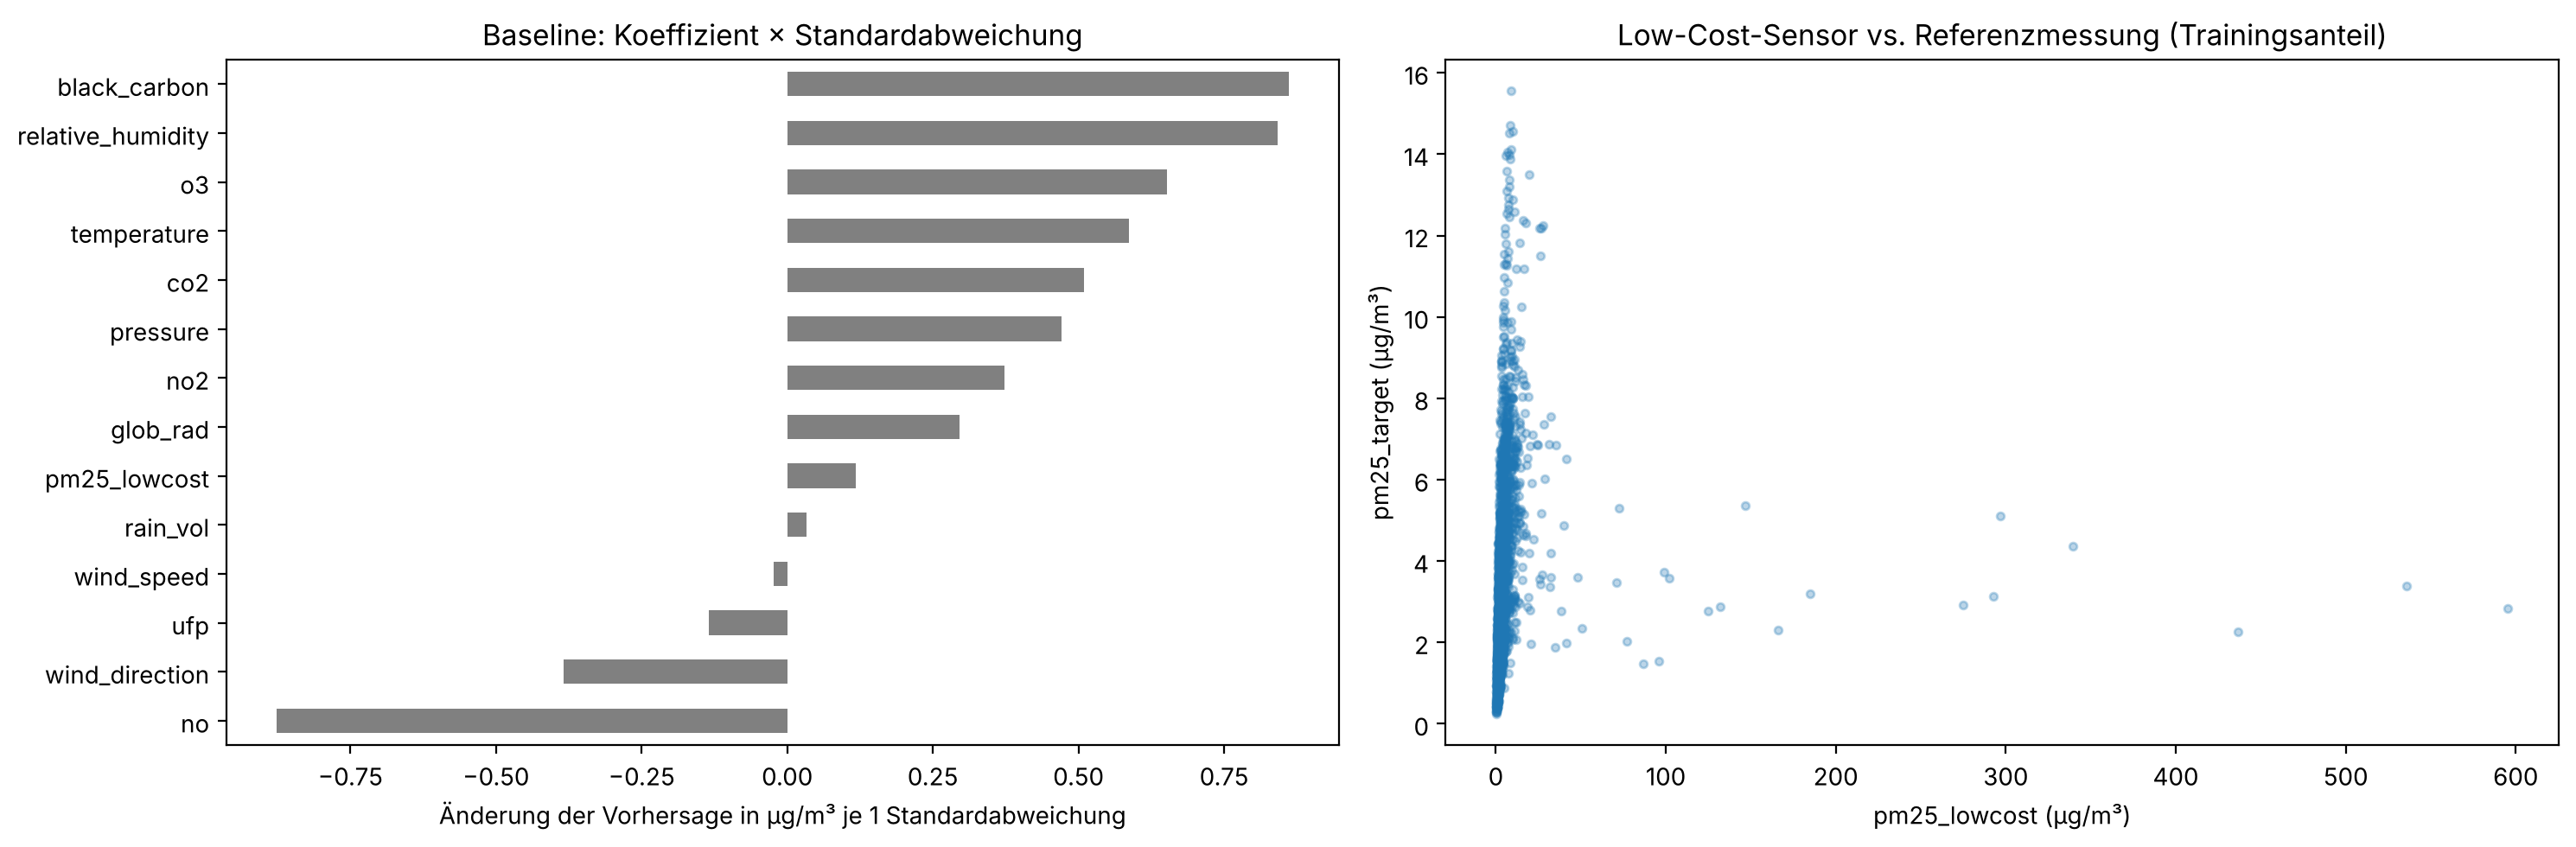

Koeffizient pm25_lowcost: 0.00522
Anteil Trainingszeilen mit pm25_lowcost > 20 µg/m³: 1.8 %


In [6]:
baseline_importance = pd.Series(baseline_model.coef_ * X_train_base.std().values, index=baseline_features).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

baseline_importance.plot.barh(ax=axes[0], color="grey")
axes[0].set_title("Baseline: Koeffizient × Standardabweichung")
axes[0].set_xlabel("Änderung der Vorhersage in µg/m³ je 1 Standardabweichung")

axes[1].scatter(train_base["pm25_lowcost"], train_base[TARGET], alpha=0.3, s=10)
axes[1].set_title("Low-Cost-Sensor vs. Referenzmessung (Trainingsanteil)")
axes[1].set_xlabel("pm25_lowcost (µg/m³)")
axes[1].set_ylabel("pm25_target (µg/m³)")

plt.tight_layout()
plt.show()

print("Koeffizient pm25_lowcost:", round(baseline_model.coef_[baseline_features.index("pm25_lowcost")], 5))
print("Anteil Trainingszeilen mit pm25_lowcost > 20 µg/m³:",
      round((train_base["pm25_lowcost"] > 20).mean() * 100, 2), "%")

**Interpretation der Baseline:**

- Die Baseline erreicht auf der Validierung einen **MAE von 1,27 µg/m³** bei einem **R² von 0,32**. Bei einem mittleren Label von etwa 3,3 µg/m³ ist das ein Fehler von fast 40 %.
- Auffällig ist, dass der Koeffizient von `pm25_lowcost` mit **0,005** praktisch null ist. Das Feature, das fachlich am meisten aussagen sollte, wird vom Modell fast ignoriert.
- Der Grund ist im Streudiagramm zu sehen: Wenige extreme Low-Cost-Werte (bis knapp 600 µg/m³, obwohl die Referenz nie über 16 µg/m³ liegt) „ziehen" die Regressionsgerade flach. Weniger als 2 % der Zeilen liegen über 20 µg/m³, bestimmen aber die Steigung. Das passt zum Ergebnis aus Task 1b, wo `pm25_lowcost` allein ein R² von nahezu 0 hatte.
- Die Validierung ist hier sogar minimal besser als das Training (negative Overfitting-Lücke). Das ist kein Overfitting, sondern zeigt, dass die extremen Ausreißer zufällig häufiger im Trainingsanteil liegen.

**Learning:** Schon die Analyse der Baseline zeigt den wichtigsten Hebel: Solange die Ausreißer von `pm25_lowcost` nicht behandelt sind, kann die lineare Regression das wichtigste Feature nicht nutzen.

## 4. Werkzeugkasten: die Preprocessing-Module M1–M6

Jedes Problem aus Task 1 wird durch ein eigenes **Modul** behandelt. Alle Module folgen demselben Muster, damit man sie frei kombinieren kann:

```
modul(train_part, other_parts, method)  ->  train_part, other_parts, info
```

- `train_part`: Trainingsanteil – hier werden Parameter **gelernt** (z. B. Median, Kappungsgrenze)
- `other_parts`: Liste aus Validierung und Test – hier werden die gelernten Parameter nur **angewendet**
- `method`: welche Variante des Moduls verwendet wird (z. B. `"median"` oder `"interpolation"`)
- `info`: was das Modul gelernt bzw. verändert hat (zur Dokumentation)

Ausnahme sind Schritte ohne gelernte Parameter, die einen **zeitlichen Zusammenhang** brauchen (M1 und die Interpolation in M2). Diese laufen auf der jeweils **ganzen Originaldatei** (Trainingsdatei bzw. Testdatei), weil ein zufällig gezogener Validierungsanteil keine lückenlose Zeitreihe mehr ist. Sie verwenden nur Feature-Werte, nie das Label, und lernen nichts aus anderen Dateien. Dadurch entsteht keine Leakage.

| Modul | Problem aus Task 1 | Varianten |
|---|---|---|
| M1 Regelbasierte Korrekturen | physikalisch unmögliche Werte, kumulierter Regenzähler | an / aus |
| M2 Missing Values | fehlende Feature-Werte | Median, Mittelwert, zeitliche Interpolation, Zeilen löschen (nur Training) |
| M3 Outlier Handling | extreme Sensorwerte | Winsorisierung 95 % / 99 %, IQR-Kappung, Pearson-optimierte Kappung, Log-, Rang-Transformation |
| M4 Scaling | unterschiedliche Wertebereiche | Standardisierung |
| M5 Feature Engineering | Zeitstempel nicht nutzbar, Windrichtung als Kreis, Feuchteeffekt | Tageszeit, Windrichtung, Feuchte-Interaktion |
| M6 Feature Selection | schwache / redundante Features | Korrelationsfilter, VIF-Check |

### M1 – Regelbasierte Korrekturen

Bei der genaueren Prüfung der Rohdaten sind uns zwei Probleme aufgefallen, die in Task 1 noch nicht behandelt wurden:

1. **Negative Stickstoffmonoxid-Werte (`no`)**: Eine Konzentration kann physikalisch nicht negativ sein. Werte knapp unter 0 entstehen typischerweise durch Messrauschen an der Nachweisgrenze. **Regel:** negative Werte werden auf 0 gesetzt.
2. **`rain_vol` ist ein kumulierter Zähler**: Der Wert steigt über den Zeitraum fast nur an (von ca. 45 auf 175). Für das Modell ist aber relevant, ob es **in dieser Stunde** geregnet hat. **Regel:** Wir bilden die Differenz zur Vorstunde (`rain_hourly`). Negative Differenzen (Zählerreset) werden auf 0 gesetzt.

Zuerst prüfen wir beide Befunde.

Negative 'no'-Werte im Trainingsdatensatz: 486 | Minimum: -2.7
Negative 'no'-Werte im Testdatensatz:      99


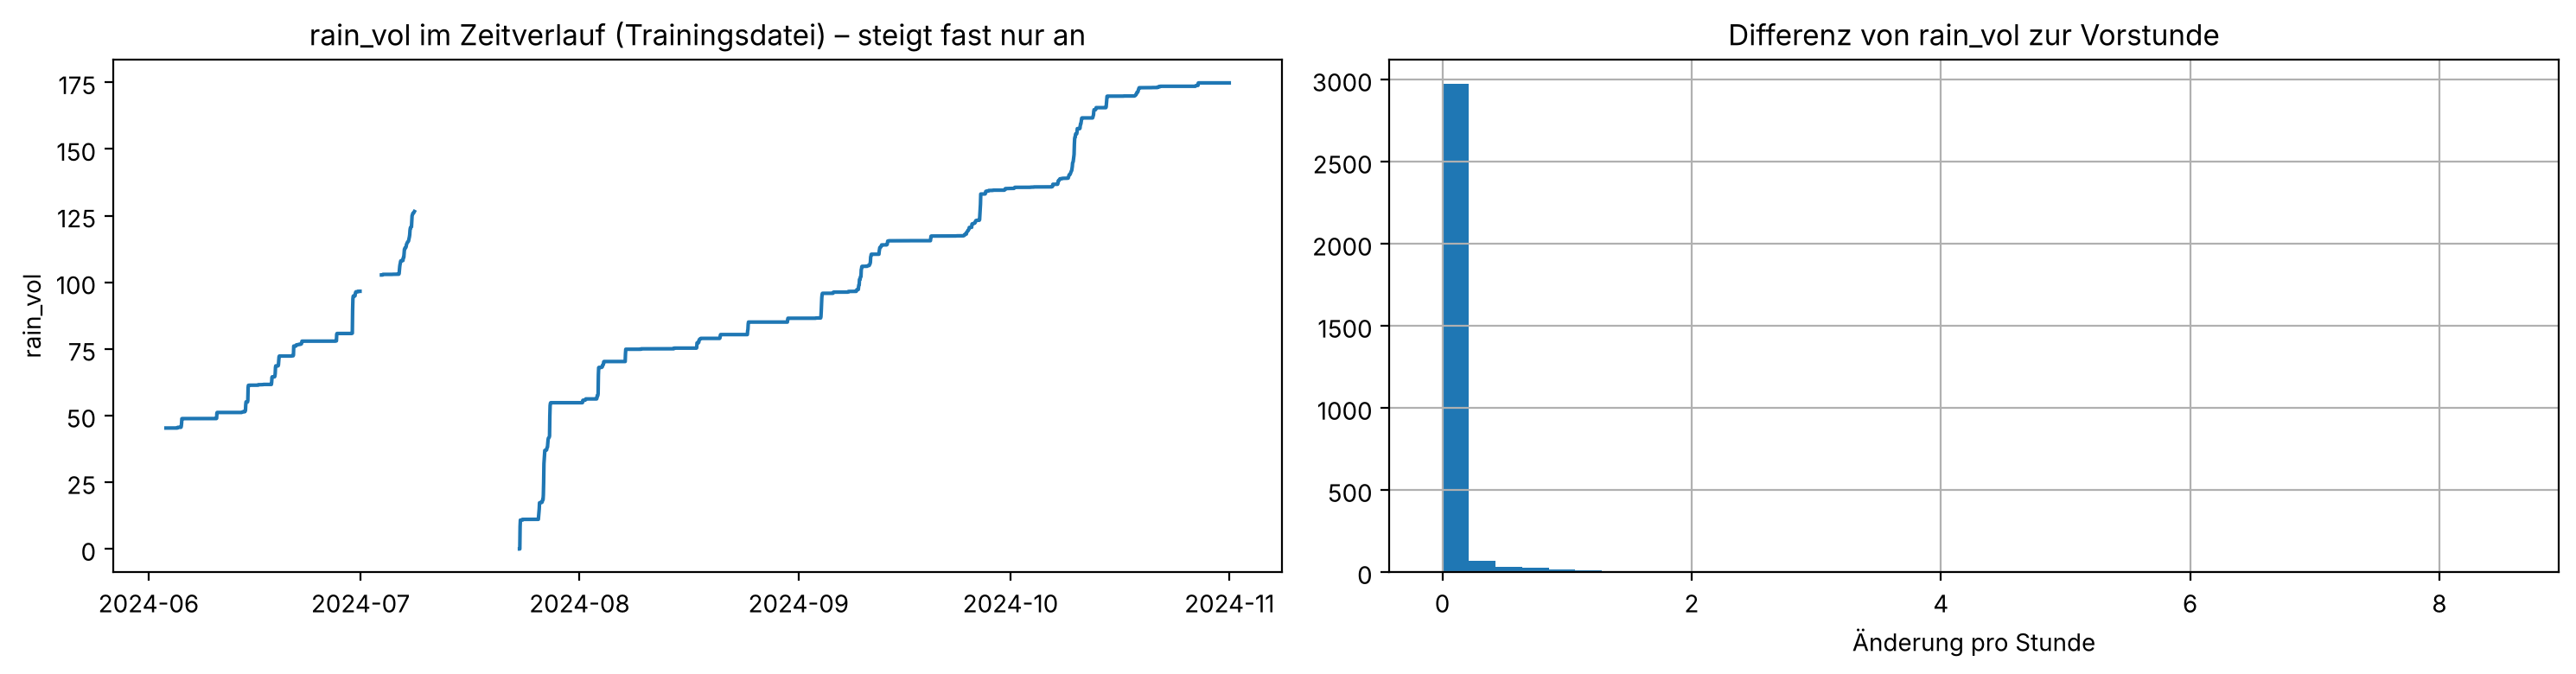

Anteil Stunden mit negativer Differenz: 0.0 %


In [7]:
print("Negative 'no'-Werte im Trainingsdatensatz:", (raw_train["no"] < 0).sum(), "| Minimum:", raw_train["no"].min())
print("Negative 'no'-Werte im Testdatensatz:     ", (raw_test["no"] < 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(raw_train["timestamp"], raw_train["rain_vol"])
axes[0].set_title("rain_vol im Zeitverlauf (Trainingsdatei) – steigt fast nur an")
axes[0].set_ylabel("rain_vol")
raw_train["rain_vol"].diff().hist(bins=40, ax=axes[1])
axes[1].set_title("Differenz von rain_vol zur Vorstunde")
axes[1].set_xlabel("Änderung pro Stunde")
plt.tight_layout()
plt.show()

print("Anteil Stunden mit negativer Differenz:", round((raw_train["rain_vol"].diff() < 0).mean() * 100, 2), "%")

In [8]:
def m1_rules(df):
    # Regelbasierte Korrekturen. Keine gelernten Parameter -> wird auf jede Originaldatei als Ganzes angewendet.
    df = df.copy()

    # Regel 1: negative Konzentrationen sind physikalisch unmöglich -> 0
    df["no"] = df["no"].clip(lower=0)

    # Regel 2: kumulierten Regenzähler in Regen pro Stunde umrechnen
    # Voraussetzung: Datei ist zeitlich sortiert (stündliches Raster, in Task 1 geprüft)
    assert df["timestamp"].is_monotonic_increasing
    df["rain_hourly"] = df["rain_vol"].diff().clip(lower=0)
    df.loc[df.index[0], "rain_hourly"] = 0      # erste Stunde hat keine Vorstunde
    df = df.drop(columns="rain_vol")
    return df


train_m1 = m1_rules(raw_train)
print("Minimum 'no' nach M1:", train_m1["no"].min())
display(train_m1[["timestamp", "rain_hourly"]].describe().T)

Minimum 'no' nach M1: 0.0


,count,mean,min,25%,50%,75%,max,std
timestamp,3613,2024-08-17 17:00:00,2024-06-03 11:00:00,2024-07-11 02:00:00,2024-08-17 17:00:00,2024-09-24 08:00:00,2024-10-31 23:00:00,NaN
rain_hourly,3183.0,0.078521,0.0,0.0,0.0,0.0,8.531,0.440869


**Ergebnis M1:** Im Training gibt es **486** negative `no`-Werte, im Test **99**. Nach M1 ist das Minimum 0. Die Differenz von `rain_vol` ist im Trainingszeitraum nie negativ. Der Zähler wurde also nicht zurückgesetzt, und `rain_hourly` ist meist 0 (keine Regenstunde), mit einem Maximum von 8,5 pro Stunde.

**Learning:** Ein Feature kann „gut aussehen" (keine Ausreißer, normale Werte) und trotzdem fachlich falsch kodiert sein. Den Regenzähler haben wir erst beim Plotten im Zeitverlauf erkannt, nicht über Histogramme oder Boxplots.

### M2 – Missing Value Handling

Aus Task 1 wissen wir, dass vor allem `co2`, `ufp`, `o3` und die Wetterdaten fehlen. Wichtig ist, **wie** die Werte fehlen: einzeln verstreut oder in langen Blöcken. Das entscheidet, welche Methode sinnvoll ist.

In [9]:
def longest_gap(series):
    # Länge des längsten zusammenhängenden NaN-Blocks (in Stunden)
    is_missing = series.isna()
    block_id = (is_missing != is_missing.shift()).cumsum()
    block_lengths = is_missing.groupby(block_id).sum()
    return int(block_lengths.max())


mv_overview = pd.DataFrame({
    "fehlend (Anzahl)": raw_train.isna().sum(),
    "fehlend (%)": (raw_train.isna().mean() * 100).round(1),
    "längster Block (Stunden)": [longest_gap(raw_train[col]) for col in raw_train.columns],
})
display(mv_overview[mv_overview["fehlend (Anzahl)"] > 0].sort_values("fehlend (Anzahl)", ascending=False))

,fehlend (Anzahl),fehlend (%),längster Block (Stunden)
co2,927,25.7,568
ufp,777,21.5,248
o3,747,20.7,513
pm25_lowcost,461,12.8,306
pressure,428,11.8,356
temperature,428,11.8,356
relative_humidity,428,11.8,356
wind_speed,428,11.8,356
wind_direction,428,11.8,356
rain_vol,428,11.8,356


Die meisten Lücken sind **lange Blöcke** (bis zu mehrere Wochen), also Sensorausfälle. Einzelne verstreute Lücken gibt es kaum.

Wir testen daher vier Varianten aus der Vorlesung:

| Variante | Vorgehen | Erwartung |
|---|---|---|
| `median` | Trainings-Median (= Baseline) | robust gegen Ausreißer |
| `mean` | Trainings-Mittelwert | wird durch Ausreißer verzerrt (z. B. `pm25_lowcost`: Mittelwert 5,5 vs. Median 2,7) |
| `interpolation` | lineare Interpolation über die Zeit, max. 6 Stunden; längere Lücken danach mit Median | nur für kurze Lücken sinnvoll, da Messwerte von Stunde zu Stunde ähnlich sind |
| `drop_rows` | Trainingszeilen ohne `pm25_lowcost` löschen (Listwise Deletion), Rest Median | nur im Training erlaubt; das wichtigste Feature wird nicht „erfunden" |

Für die Interpolation begrenzen wir auf 6 Stunden. Eine Linie über eine mehrwöchige Lücke wäre keine Schätzung mehr, sondern geraten.

In [10]:
INTERPOLATION_LIMIT = 6   # maximal 6 aufeinanderfolgende Stunden werden interpoliert


def interpolate_features(df):
    # Zeitliche Interpolation auf einer ganzen Originaldatei. Das Label wird NIE interpoliert.
    df = df.copy()
    assert df["timestamp"].is_monotonic_increasing
    feature_cols = [col for col in df.select_dtypes(include="number").columns if col != TARGET]
    df[feature_cols] = df[feature_cols].interpolate(limit=INTERPOLATION_LIMIT, limit_area="inside")
    return df


def m2_missing_values(train_part, other_parts, method):
    # Füllt fehlende Feature-Werte. Statistiken kommen ausschließlich aus dem Trainingsanteil.
    train_part = train_part.copy()
    feature_cols = [col for col in train_part.select_dtypes(include="number").columns if col != TARGET]
    info = {"Methode": method}

    if method == "drop_rows":
        # Listwise Deletion – NUR im Training erlaubt
        before = len(train_part)
        train_part = train_part[train_part["pm25_lowcost"].notna()]
        info["gelöschte Trainingszeilen"] = before - len(train_part)

    # Füllwert: Mittelwert oder Median des Trainingsanteils
    if method == "mean":
        fill_values = train_part[feature_cols].mean()
    else:
        fill_values = train_part[feature_cols].median()   # median, interpolation (Rest), drop_rows (Rest)

    info["noch fehlende Werte vor dem Füllen (Training)"] = int(train_part[feature_cols].isna().sum().sum())
    train_part[feature_cols] = train_part[feature_cols].fillna(fill_values)

    filled_others = []
    for part in other_parts:
        part = part.copy()
        part[feature_cols] = part[feature_cols].fillna(fill_values)
        filled_others.append(part)
    return train_part, filled_others, info

In [11]:
# Wie viele fehlende Werte schließt die Interpolation (max. 6 h) überhaupt?
interp_train = interpolate_features(raw_train)
interp_test = interpolate_features(raw_test)
interp_effect = pd.DataFrame({
    "NaN Training vorher": raw_train.drop(columns=TARGET).isna().sum(),
    "NaN Training nachher": interp_train.drop(columns=TARGET).isna().sum(),
    "NaN Test vorher": raw_test.drop(columns=TARGET).isna().sum(),
    "NaN Test nachher": interp_test.drop(columns=TARGET).isna().sum(),
})
display(interp_effect[interp_effect["NaN Training vorher"] + interp_effect["NaN Test vorher"] > 0])

,NaN Training vorher,NaN Training nachher,NaN Test vorher,NaN Test nachher
pm25_lowcost,461,447,3,0
no,22,10,2,0
no2,22,10,2,0
o3,747,740,156,156
co2,927,915,858,856
black_carbon,2,0,713,707
ufp,777,679,615,587
temperature,428,416,985,979
relative_humidity,428,416,985,979
pressure,428,416,985,979


**Ergebnis M2:** Die Interpolation mit einem Limit von 6 Stunden schließt nur sehr wenige Lücken, z. B. bei `pm25_lowcost` 14 von 461 und bei den Wetterdaten 12 von 428. Das bestätigt die Blockanalyse: Die Daten fehlen fast nur durch längere Sensorausfälle. Dort hilft eine zeitliche Interpolation nicht. Wir erwarten deshalb von M2 nur einen kleinen Effekt.

### M3 – Outlier Handling: Pearson vs. Spearman

In der Task-1-Präsentation kam der Hinweis, die **Pearson- und die Spearman-Korrelation** zu vergleichen, weil dabei etwas auffällt, das bei den Ausreißern hilft.

**Was ist der Unterschied?**
- **Pearson** misst den **linearen** Zusammenhang der echten Werte. Ein einzelner extremer Wert kann ihn stark verfälschen, weil er quadratisch in die Berechnung eingeht.
- **Spearman** ist die Pearson-Korrelation der **Ränge** (1., 2., 3. … kleinster Wert). Wie extrem ein Ausreißer ist, spielt dann keine Rolle mehr. Es zählt nur die Reihenfolge. Spearman misst also, ob ein **monotoner** Zusammenhang besteht („je höher A, desto höher B").

**Unsere Idee:** Ist Spearman deutlich höher als Pearson, dann ist der Zusammenhang eigentlich stark, wird aber von Ausreißern verdeckt. Genau bei diesen Features lohnt sich Outlier Handling. Die Korrelationen berechnen wir nur auf dem Trainingsanteil.

,Pearson,Spearman,Lücke (|Spearman| - |Pearson|)
pm25_lowcost,0.081,0.721,0.640
black_carbon,0.292,0.587,0.295
no,0.051,0.239,0.188
no2,0.244,0.371,0.128
o3,-0.001,-0.090,0.089
ufp,0.256,0.344,0.087
co2,0.244,0.325,0.082
relative_humidity,0.122,0.180,0.058
rain_vol,-0.008,-0.052,0.044
wind_speed,-0.170,-0.194,0.024


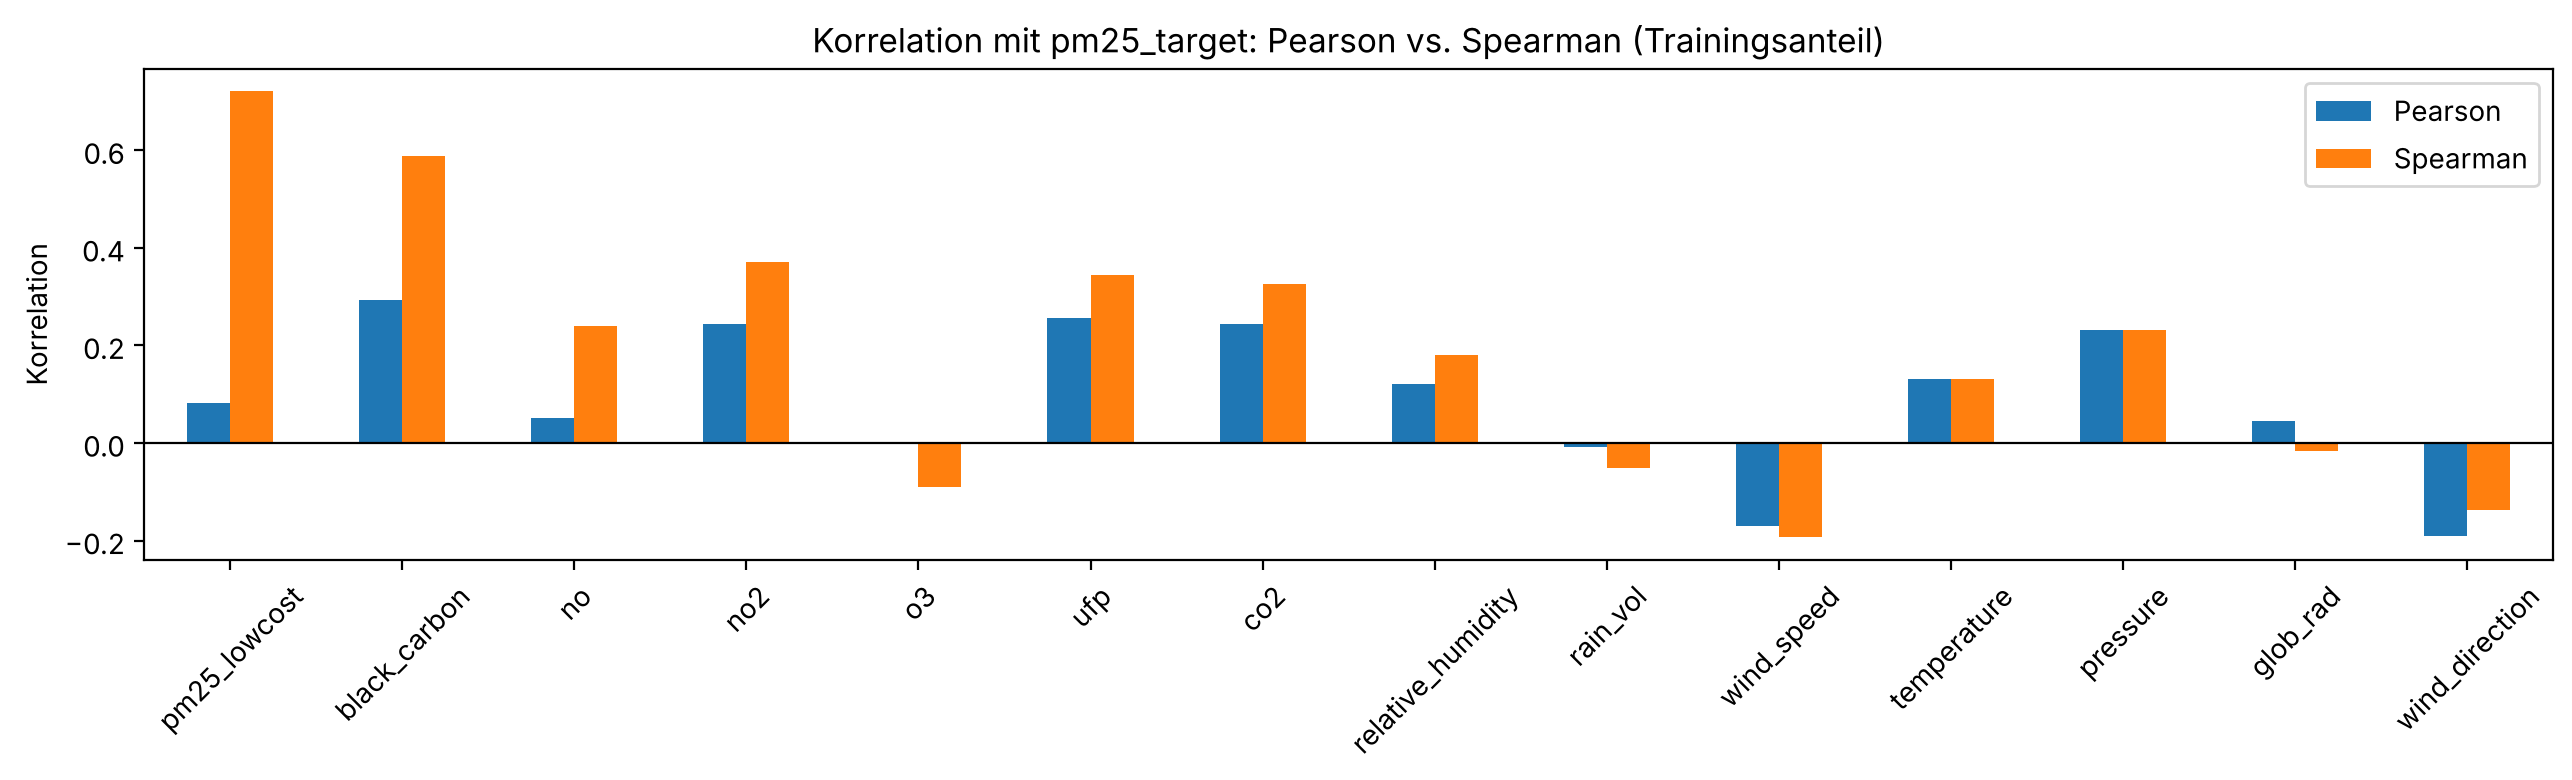

In [12]:
train_corr_base = raw_train.loc[train_idx]
train_corr_base = train_corr_base[train_corr_base[TARGET].notna()]
numeric_train = train_corr_base.select_dtypes(include="number").drop(columns=TARGET)

corr_compare = pd.DataFrame({
    "Pearson": numeric_train.corrwith(train_corr_base[TARGET], method="pearson"),
    "Spearman": numeric_train.corrwith(train_corr_base[TARGET], method="spearman"),
})
corr_compare["Lücke (|Spearman| - |Pearson|)"] = corr_compare["Spearman"].abs() - corr_compare["Pearson"].abs()
corr_compare = corr_compare.sort_values("Lücke (|Spearman| - |Pearson|)", ascending=False)
display(corr_compare.round(3))

corr_compare[["Pearson", "Spearman"]].plot.bar(figsize=(13, 4), rot=45)
plt.title("Korrelation mit pm25_target: Pearson vs. Spearman (Trainingsanteil)")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Korrelation")
plt.tight_layout()
plt.show()

In [13]:
# Features mit einer Lücke > 0.15 werden in M3 behandelt (Schwelle: deutlich sichtbarer Abstand im Diagramm)
GAP_THRESHOLD = 0.15
OUTLIER_FEATURES = corr_compare[corr_compare["Lücke (|Spearman| - |Pearson|)"] > GAP_THRESHOLD].index.tolist()
print("Features für das Outlier Handling:", OUTLIER_FEATURES)

Features für das Outlier Handling: ['pm25_lowcost', 'black_carbon', 'no']


**Das ist die Auffälligkeit aus dem Hinweis:** Bei `pm25_lowcost` beträgt die Pearson-Korrelation nur **0,08**, die Spearman-Korrelation dagegen **0,72**. Der Low-Cost-Sensor hängt also **stark und monoton** mit der Referenzmessung zusammen („steigt die Referenz, steigt der Low-Cost-Wert"). Der lineare Zusammenhang wird aber durch wenige extreme Werte fast vollständig verdeckt. Dasselbe, nur schwächer, gilt für `black_carbon` (0,29 vs. 0,59) und `no` (0,05 vs. 0,24).

Damit liefert der Vergleich zwei Dinge:
1. **Welche Features** ein Ausreißerproblem haben: genau die mit großer Lücke. Bei Temperatur oder Luftdruck sind Pearson und Spearman fast gleich, dort gibt es nichts zu korrigieren.
2. **Wie viel Potenzial** in der Behandlung steckt: Spearman ist eine Art Obergrenze dafür, wie gut ein monotoner Zusammenhang nach einer passenden Transformation linear werden kann.

#### Pearson vs. Spearman als Korrelationsmatrizen

Bisher haben wir nur die Korrelation jedes Features mit dem Label betrachtet. Eine Ausreißerbehandlung verändert aber auch die Zusammenhänge **zwischen** den Features. Deshalb vergleichen wir die vollständigen Korrelationsmatrizen:

1. **Pearson**: lineare Zusammenhänge der echten Werte
2. **Spearman**: monotone Zusammenhänge der Ränge
3. **Differenz |Spearman| − |Pearson|**: Wo ist sie groß? Dort verdecken Ausreißer (oder ein nicht linearer Verlauf) einen Zusammenhang.

Alle Matrizen werden nur auf dem Trainingsanteil berechnet.

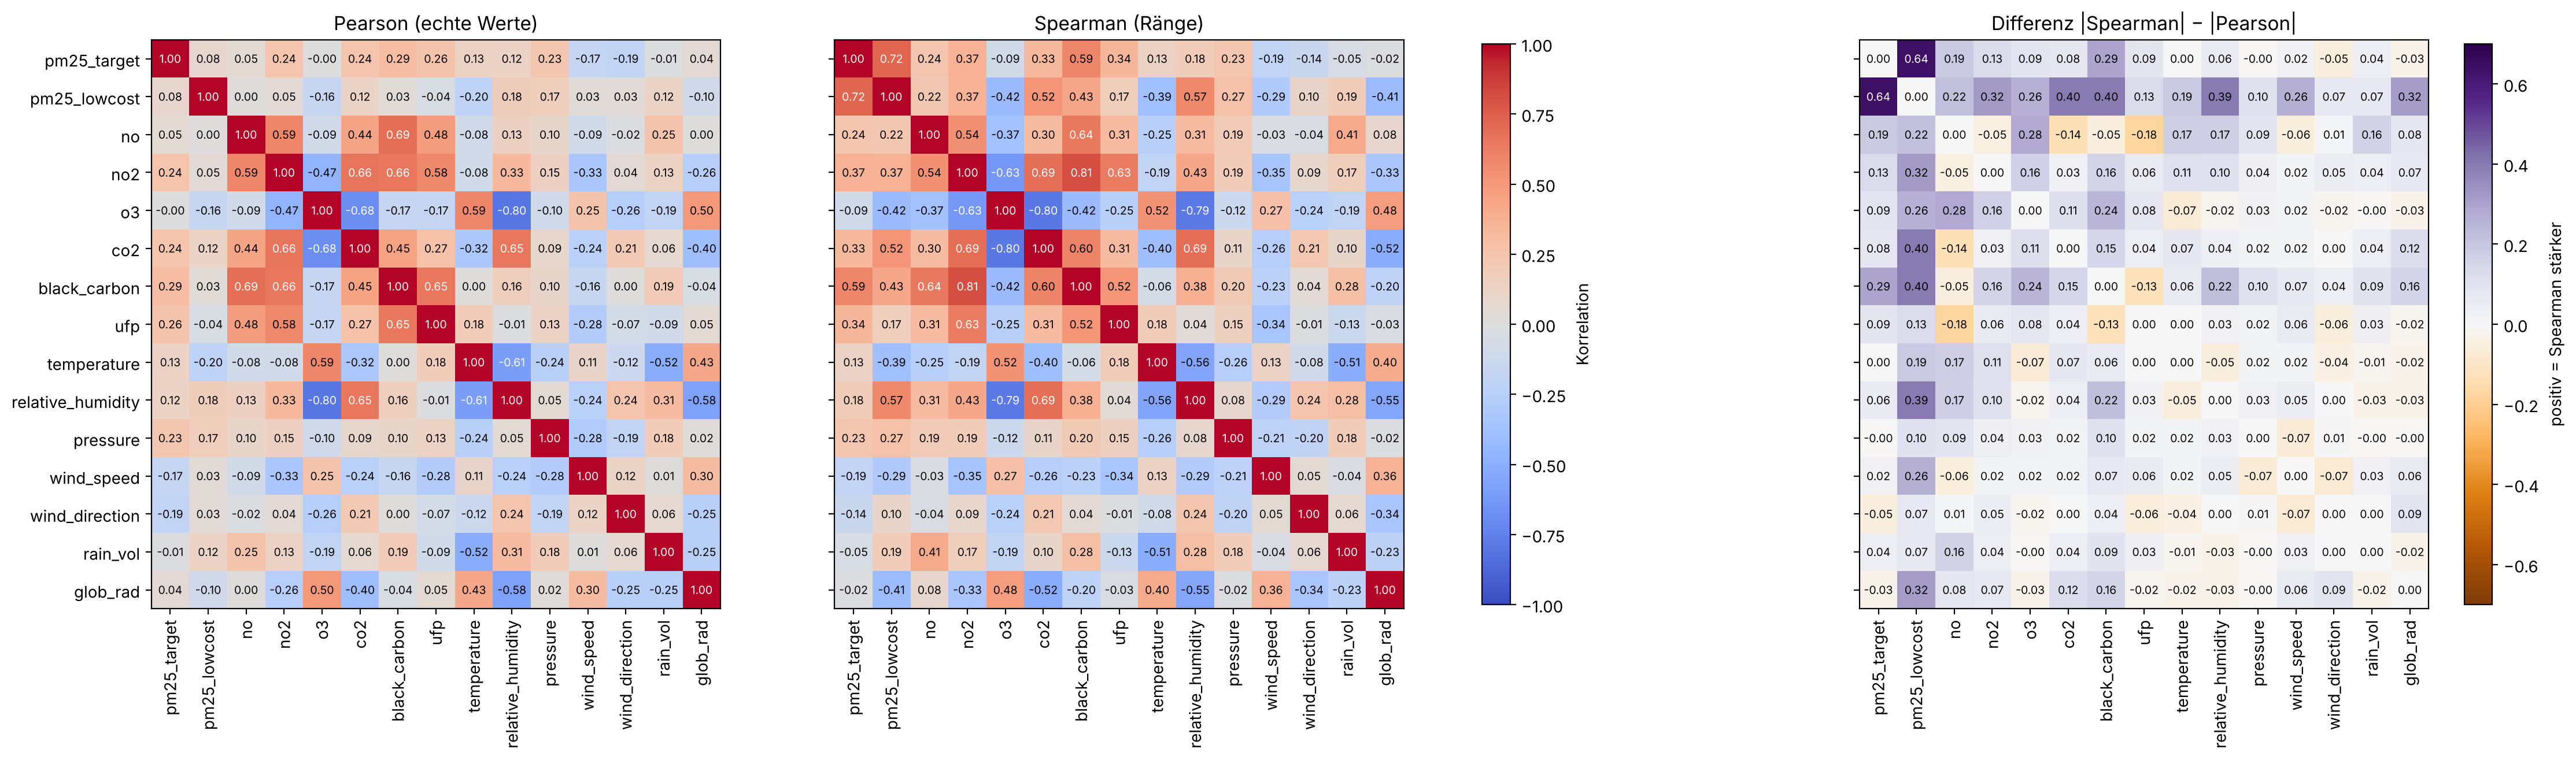

In [14]:
def plot_corr_matrix(matrix, ax, title, vmin=-1, vmax=1, cmap="coolwarm", show_ylabels=True):
    # Korrelationsmatrix als Heatmap mit Zahlenwerten (nur matplotlib, wie in den Labs)
    image = ax.imshow(matrix.values, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns, rotation=90)
    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(matrix.index if show_ylabels else [])   # Beschriftung nur links, sonst überlappt sie
    for i in range(len(matrix.index)):
        for j in range(len(matrix.columns)):
            value = matrix.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(value) > 0.6 * max(abs(vmin), abs(vmax)) else "black")
    ax.set_title(title)
    return image


numeric_with_label = train_corr_base.select_dtypes(include="number")
pearson_matrix = numeric_with_label.corr(method="pearson")
spearman_matrix = numeric_with_label.corr(method="spearman")
diff_matrix = spearman_matrix.abs() - pearson_matrix.abs()

fig, axes = plt.subplots(1, 3, figsize=(27, 9))
plot_corr_matrix(pearson_matrix, axes[0], "Pearson (echte Werte)")
img = plot_corr_matrix(spearman_matrix, axes[1], "Spearman (Ränge)", show_ylabels=False)
fig.colorbar(img, ax=axes[:2], shrink=0.7, label="Korrelation")
img_diff = plot_corr_matrix(diff_matrix, axes[2], "Differenz |Spearman| − |Pearson|", vmin=-0.7, vmax=0.7, cmap="PuOr",
                            show_ylabels=False)
fig.colorbar(img_diff, ax=axes[2], shrink=0.7, label="positiv = Spearman stärker")
plt.show()

Im zweiten Schritt prüfen wir, ob die Winsorisierung am 95. Perzentil (Vorschlag aus Task 1) die Pearson-Matrix an die Spearman-Matrix heranführt. Dafür kappen wir die drei Ausreißer-Features probeweise auf dem Trainingsanteil und vergleichen die Matrizen für die wichtigsten Features.

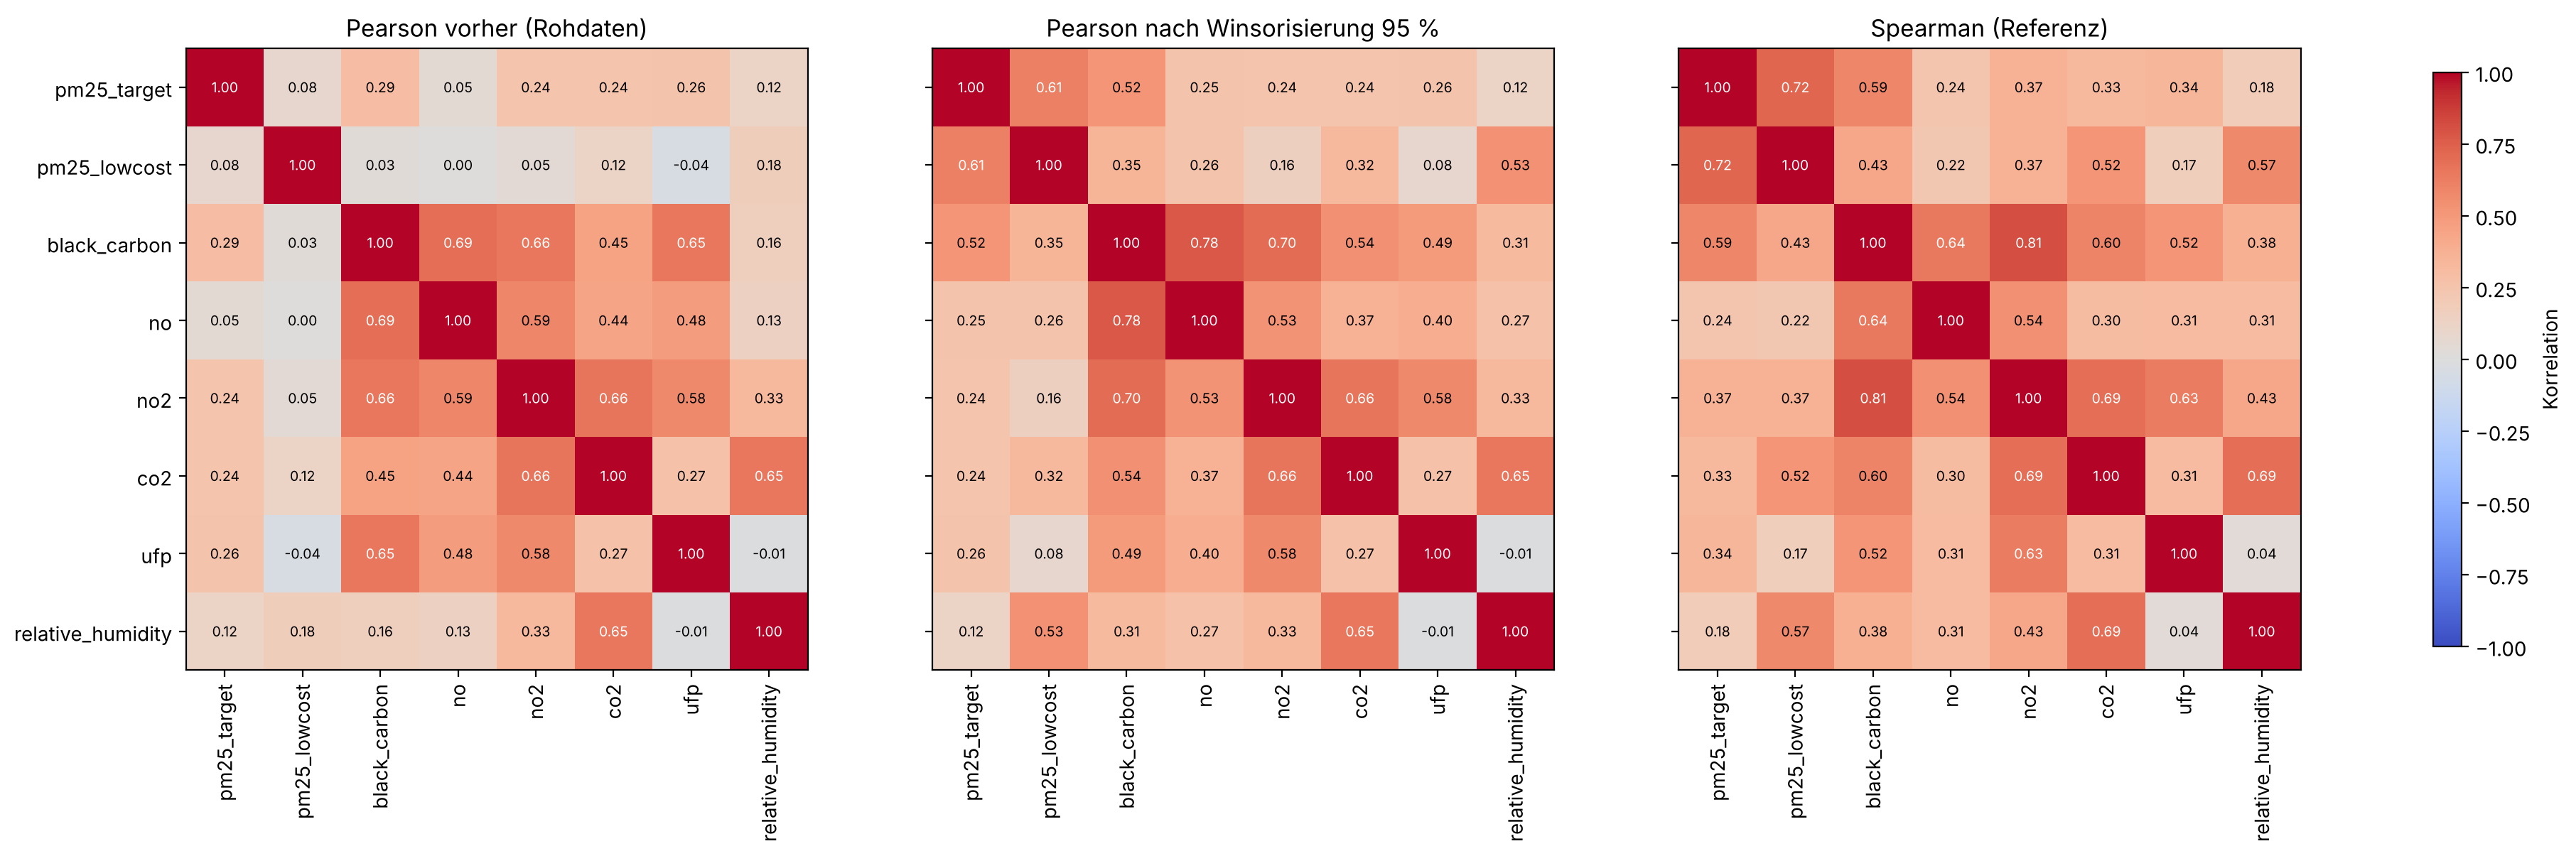

,Pearson vorher,Pearson nach Winsor 95 %,Spearman
pm25_target,0.08,0.61,0.72
black_carbon,0.03,0.35,0.43
no,0.00,0.26,0.22
no2,0.05,0.16,0.37
co2,0.12,0.32,0.52
ufp,-0.04,0.08,0.17
relative_humidity,0.18,0.53,0.57


In [15]:
matrix_features = [TARGET, "pm25_lowcost", "black_carbon", "no", "no2", "co2", "ufp", "relative_humidity"]

capped_train = train_corr_base[matrix_features].copy()
for feature in OUTLIER_FEATURES:
    capped_train[feature] = capped_train[feature].clip(upper=capped_train[feature].quantile(0.95))

pearson_raw = train_corr_base[matrix_features].corr(method="pearson")
pearson_capped = capped_train.corr(method="pearson")
spearman_sel = train_corr_base[matrix_features].corr(method="spearman")

fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))
plot_corr_matrix(pearson_raw, axes[0], "Pearson vorher (Rohdaten)")
plot_corr_matrix(pearson_capped, axes[1], "Pearson nach Winsorisierung 95 %", show_ylabels=False)
img = plot_corr_matrix(spearman_sel, axes[2], "Spearman (Referenz)", show_ylabels=False)
fig.colorbar(img, ax=axes, shrink=0.7, label="Korrelation")
plt.show()

# Die Zeile von pm25_lowcost im direkten Vergleich
lowcost_row = pd.DataFrame({
    "Pearson vorher": pearson_raw["pm25_lowcost"],
    "Pearson nach Winsor 95 %": pearson_capped["pm25_lowcost"],
    "Spearman": spearman_sel["pm25_lowcost"],
}).drop(index="pm25_lowcost")
display(lowcost_row.round(2))

**Interpretation der Korrelationsmatrizen:**

- **In der Differenzmatrix fällt eine komplette Zeile und Spalte auf: `pm25_lowcost`.** Die Ausreißer verfälschen also nicht nur den Zusammenhang mit dem Label, sondern auch fast alle Zusammenhänge mit anderen Features. In der Pearson-Matrix wirkt der Low-Cost-Sensor wie ein Zufallsrauschen ohne Bezug zu irgendetwas, obwohl er nach Spearman mit Referenz, Luftfeuchte, CO₂ und Black Carbon deutlich zusammenhängt. Schwächer sieht man dasselbe Muster bei `black_carbon` und `no`.
- **Die Winsorisierung am 95. Perzentil holt den Großteil zurück.** Pearson mit dem Label steigt von 0,08 auf 0,61 (Spearman: 0,72). Die übrige Matrix nähert sich ebenfalls der Spearman-Matrix an, z. B. `pm25_lowcost` ↔ `black_carbon` von 0,03 auf 0,35 (Spearman 0,43).
- **Der wichtigste Nebenbefund: die Luftfeuchte.** Zwischen `pm25_lowcost` und `relative_humidity` liegt Pearson in den Rohdaten bei 0,18, nach der Kappung bei 0,53, Spearman bei 0,57. Der Zusammenhang zwischen Sensor und Luftfeuchte war also in den Daten vorhanden, wurde aber von den Ausreißern verdeckt. Genau das untersuchen wir im nächsten Schritt.
- Ganz erreicht Pearson die Spearman-Werte nicht. Der Rest ist kein Ausreißereffekt mehr, sondern ein **nicht linearer** Zusammenhang, den eine Kappung allein nicht linear machen kann.

**Learning:** Die Matrix-Sicht zeigt mehr als die einzelne Korrelation mit dem Label. Erst hier wird sichtbar, dass die Ausreißer die Beziehung des Sensors zur Luftfeuchte verdecken. Aus genau diesem Hinweis ist später das Feature `lowcost_x_humidity` entstanden.

#### Wann und warum entstehen die Ausreißer von `pm25_lowcost`?

Bevor wir Werte verändern, prüfen wir, ob die Ausreißer **Messfehler** oder **echte Extremwerte** sind (Empfehlung aus Task 1). Das Label (Referenzgerät) dient dabei als Kontrolle: Wäre die Luft wirklich stark belastet, müsste auch `pm25_target` hoch sein.

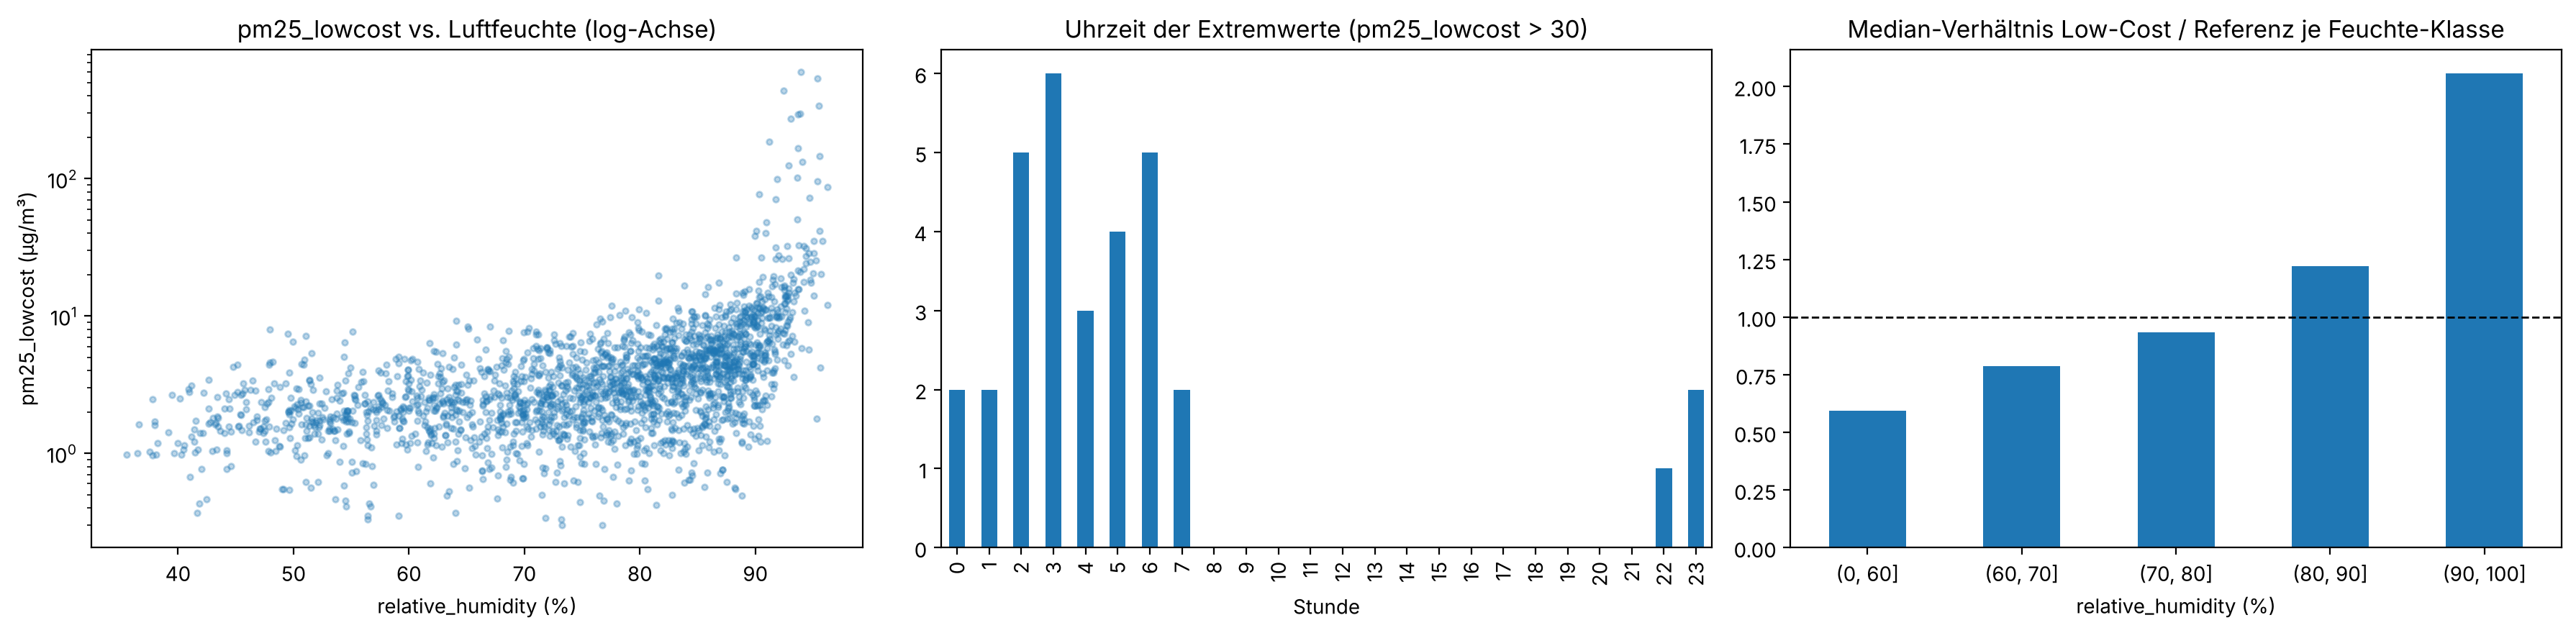

Extremwerte (> 30 µg/m³): 32
Median-Luftfeuchte bei Extremwerten: 93.7 %  | gesamt: 78.6 %
Maximum pm25_target bei diesen Extremwerten: 7.55 µg/m³


In [16]:
lc = train_corr_base.dropna(subset=["pm25_lowcost", "relative_humidity"]).copy()
lc["Verhältnis lowcost / target"] = lc["pm25_lowcost"] / lc[TARGET]
lc["Feuchte-Klasse"] = pd.cut(lc["relative_humidity"], bins=[0, 60, 70, 80, 90, 100])
extreme = lc[lc["pm25_lowcost"] > 30]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].scatter(lc["relative_humidity"], lc["pm25_lowcost"], s=8, alpha=0.3)
axes[0].set_yscale("log")
axes[0].set_title("pm25_lowcost vs. Luftfeuchte (log-Achse)")
axes[0].set_xlabel("relative_humidity (%)")
axes[0].set_ylabel("pm25_lowcost (µg/m³)")

extreme["timestamp"].dt.hour.value_counts().sort_index().reindex(range(24), fill_value=0).plot.bar(ax=axes[1])
axes[1].set_title("Uhrzeit der Extremwerte (pm25_lowcost > 30)")
axes[1].set_xlabel("Stunde")

lc.groupby("Feuchte-Klasse", observed=True)["Verhältnis lowcost / target"].median().plot.bar(ax=axes[2], rot=0)
axes[2].axhline(1, color="black", linestyle="--", linewidth=1)
axes[2].set_title("Median-Verhältnis Low-Cost / Referenz je Feuchte-Klasse")
axes[2].set_xlabel("relative_humidity (%)")

plt.tight_layout()
plt.show()

print("Extremwerte (> 30 µg/m³):", len(extreme))
print("Median-Luftfeuchte bei Extremwerten:", round(extreme["relative_humidity"].median(), 1), "%  | gesamt:",
      round(lc["relative_humidity"].median(), 1), "%")
print("Maximum pm25_target bei diesen Extremwerten:", extreme[TARGET].max(), "µg/m³")

**Interpretation:** Die Extremwerte sind **Messfehler des Low-Cost-Sensors** und keine echte Luftbelastung:
- Sie treten fast ausschließlich **nachts zwischen 22 und 7 Uhr** auf, bei einer medianen Luftfeuchte von **94 %** (gesamt: 79 %).
- Die Referenz misst gleichzeitig höchstens **7,6 µg/m³**, also normale Werte.
- Das Verhältnis Low-Cost/Referenz steigt mit der Luftfeuchte gleichmäßig an: unter 60 % misst der Sensor etwa 40 % zu wenig, über 90 % etwa doppelt so viel.

Das passt zu einem bekannten physikalischen Effekt: Bei sehr hoher Luftfeuchte (z. B. Nebel über dem Rhein in der Nacht) nehmen Partikel Wasser auf, werden größer und werden vom optischen Low-Cost-Sensor als mehr Feinstaub gezählt. Das Referenzgerät trocknet die Luft vor der Messung.

**Konsequenz für die Data Preparation:**
1. Die Ausreißer dürfen „entschärft" werden, weil sie keine echte Information über die Luftqualität tragen. Löschen dürfen wir sie in Validierung und Test nicht. Wir verändern deshalb nur Feature-Werte (Kappung bzw. Transformation).
2. Der Feuchteeffekt besteht nicht nur bei den Extremwerten, sondern im gesamten Wertebereich. Das greifen wir in **M5 (Feuchte-Interaktion)** auf.

#### Welche Kappungsgrenze ist die richtige?

Task 1 hat eine Winsorisierung auf das **95. Perzentil** vorgeschlagen, also den Standardwert aus der Vorlesung. Mit dem Pearson/Spearman-Vergleich können wir die Grenze aber auch **datenbasiert** prüfen. Wir kappen probeweise an verschiedenen Perzentilen und beobachten, wie nah Pearson dabei an Spearman herankommt. Zusätzlich vergleichen wir zwei Transformationen aus der Vorlesung, die Ausreißer ohne feste Grenze entschärfen:

- **Log-Transformation**: staucht große Werte stark zusammen (geeignet für rechtsschiefe Verteilungen)
- **Rang-Transformation**: genau der „Raum", in dem Spearman rechnet. Der Wert wird durch seinen Rang ersetzt (umgesetzt mit dem `QuantileTransformer` aus der Vorlesung).

,Kappung 0.8,Kappung 0.85,Kappung 0.9,Kappung 0.95,Kappung 0.975,Kappung 0.99,Kappung 1.0,Log,Rang (= Spearman)
pm25_lowcost,0.658,0.662,0.651,0.611,0.551,0.407,0.081,0.556,0.721
black_carbon,0.528,0.534,0.532,0.516,0.494,0.449,0.292,0.483,0.587
no,0.212,0.228,0.244,0.255,0.262,0.252,0.051,0.242,0.239


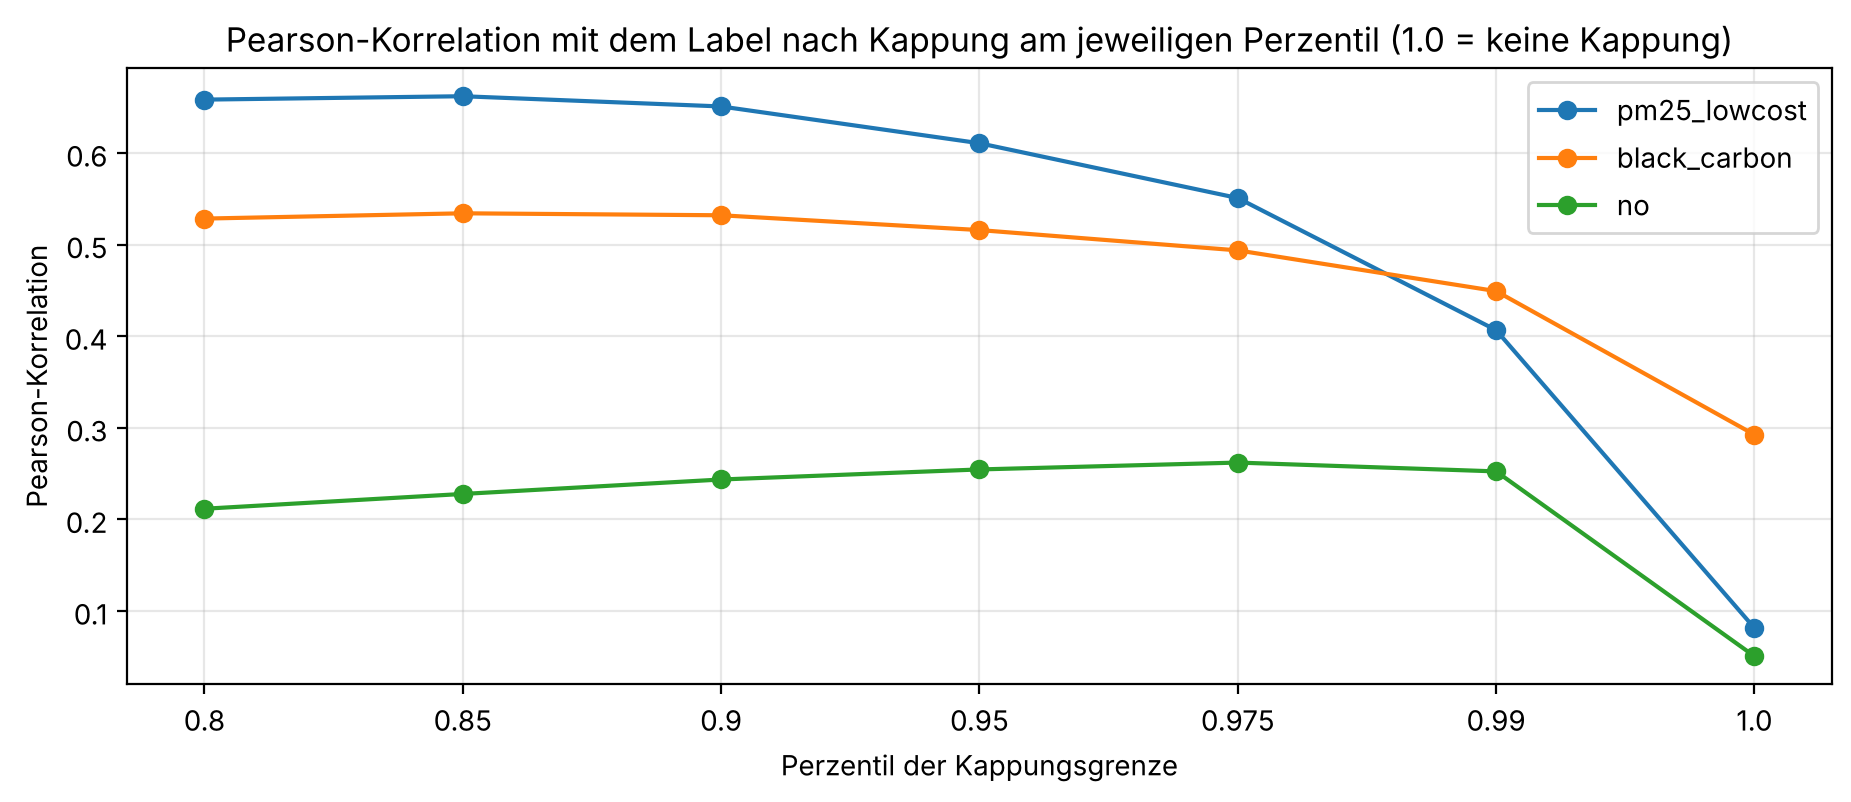

In [17]:
percentiles = [0.80, 0.85, 0.90, 0.95, 0.975, 0.99, 1.0]
y_corr = train_corr_base[TARGET]

scan_rows = {}
for feature in OUTLIER_FEATURES:
    x = train_corr_base[feature]
    row = {}
    for q in percentiles:
        row["Kappung " + str(q)] = x.clip(upper=x.quantile(q)).corr(y_corr)
    row["Log"] = np.log1p(x.clip(lower=0)).corr(y_corr)
    row["Rang (= Spearman)"] = x.corr(y_corr, method="spearman")
    scan_rows[feature] = row

scan_df = pd.DataFrame(scan_rows).T
display(scan_df.round(3))

kappung_cols = [col for col in scan_df.columns if col.startswith("Kappung")]
scan_df[kappung_cols].T.plot(marker="o", figsize=(11, 4))
plt.xticks(range(len(kappung_cols)), [c.replace("Kappung ", "") for c in kappung_cols])
plt.title("Pearson-Korrelation mit dem Label nach Kappung am jeweiligen Perzentil (1.0 = keine Kappung)")
plt.xlabel("Perzentil der Kappungsgrenze")
plt.ylabel("Pearson-Korrelation")
plt.grid(alpha=0.3)
plt.show()

**Interpretation:**
- Bei `pm25_lowcost` steigt die Pearson-Korrelation durch eine Kappung von 0,08 auf bis zu **0,66** (Kappung am 85. Perzentil). Das 95. Perzentil aus Task 1 erreicht 0,61, das 99. Perzentil nur 0,41. Eine Kappung am 99. Perzentil ist also zu großzügig, weil noch zu viele Fehlwerte übrig bleiben.
- Keine Kappung erreicht ganz den Spearman-Wert (0,72). Ein Teil des Zusammenhangs ist nicht linear (Feuchteeffekt) und lässt sich durch Kappen allein nicht herstellen.
- Bei `no` verläuft die Kurve flacher. Dort hilft schon eine leichte Kappung am 97,5. Perzentil am meisten.
- Log- und Rang-Transformation helfen ebenfalls deutlich, liegen aber unter der besten Kappung.

**Wichtig:** Eine hohe Korrelation zwischen **einem** Feature und dem Label garantiert noch kein besseres **Modell** mit allen Features. Deshalb testen wir alle Varianten im Modell: die Perzentile 95 und 99, die Boxplot-Grenze (IQR), die „Pearson-optimierte" Grenze sowie Log und Rang.

In [18]:
CAP_PERCENTILES = [0.80, 0.85, 0.90, 0.925, 0.95, 0.975, 0.99]


def m3_outliers(train_part, other_parts, method):
    # Behandelt Ausreißer in OUTLIER_FEATURES. Grenzen werden nur auf dem Trainingsanteil bestimmt.
    # Es werden keine Zeilen gelöscht, nur Feature-Werte verändert (in Validierung/Test erlaubt).
    train_part = train_part.copy()
    other_parts = [part.copy() for part in other_parts]
    info = {"Methode": method}

    for feature in OUTLIER_FEATURES:
        x = train_part[feature]

        if method in ["winsor95", "winsor99", "iqr", "pearson_opt"]:
            # 1) Obergrenze bestimmen (nur nach oben, da kleine Werte = saubere Luft plausibel sind)
            if method == "winsor95":
                upper = x.quantile(0.95)
            elif method == "winsor99":
                upper = x.quantile(0.99)
            elif method == "iqr":
                q1, q3 = x.quantile(0.25), x.quantile(0.75)
                upper = q3 + 1.5 * (q3 - q1)          # obere Boxplot-Grenze aus Task 1
            else:
                # Perzentil wählen, bei dem die Pearson-Korrelation mit dem Label am höchsten ist
                corr_by_q = {q: x.clip(upper=x.quantile(q)).corr(train_part[TARGET]) for q in CAP_PERCENTILES}
                best_q = max(corr_by_q, key=corr_by_q.get)
                upper = x.quantile(best_q)
                info[feature + " Perzentil"] = best_q
            info[feature + " Obergrenze"] = round(upper, 3)
            # 2) Grenze auf alle Datensätze anwenden
            train_part[feature] = train_part[feature].clip(upper=upper)
            for part in other_parts:
                part[feature] = part[feature].clip(upper=upper)

        elif method == "log":
            # log(1 + x); negative Werte vorher auf 0, da der Logarithmus dort nicht definiert ist
            train_part[feature] = np.log1p(train_part[feature].clip(lower=0))
            for part in other_parts:
                part[feature] = np.log1p(part[feature].clip(lower=0))

        elif method == "rank":
            # Rang-Transformation über den QuantileTransformer (gleichverteilt zwischen 0 und 1)
            qt = QuantileTransformer(n_quantiles=100, output_distribution="uniform")
            train_part[feature] = qt.fit_transform(train_part[[feature]]).ravel()
            for part in other_parts:
                part[feature] = qt.transform(part[[feature]]).ravel()

    return train_part, other_parts, info

### M4 – Scaling

Task 1 hat empfohlen, eine Standardisierung zu prüfen, weil die Features sehr unterschiedliche Wertebereiche haben (z. B. `ufp` ≈ 10.000 vs. `black_carbon` ≈ 1).

**Unsere Erwartung vorab:** Bei einer *normalen* linearen Regression (ohne Regularisierung) bringt Skalierung **keine** Verbesserung der Vorhersage. Der Grund: Die Standardisierung `x' = (x − Mittelwert) / Std` ist selbst eine lineare Transformation. Das Modell gleicht sie exakt aus, indem es den Koeffizienten mit der Standardabweichung multipliziert und den Achsenabschnitt verschiebt. Die Vorhersagen bleiben identisch, nur die Koeffizienten werden vergleichbar. Wir testen es trotzdem, um die Annahme zu belegen (Feedback Vorjahr: „Kurze Analyse, warum Scaling hier nichts bringt").

In [19]:
def m4_scaling(train_part, other_parts, method, feature_cols):
    # Standardisierung: Mittelwert und Standardabweichung kommen nur aus dem Trainingsanteil
    info = {"Methode": method}
    if method != "standard":
        return train_part, other_parts, info

    train_part = train_part.copy()
    scaler = StandardScaler()
    train_part[feature_cols] = scaler.fit_transform(train_part[feature_cols])

    scaled_others = []
    for part in other_parts:
        part = part.copy()
        part[feature_cols] = scaler.transform(part[feature_cols])
        scaled_others.append(part)
    return train_part, scaled_others, info

### M5 – Feature Engineering

Aus den Analysen oben ergeben sich drei neue Features:

1. **Tageszeit (`hour`)**: Die Ausreißer treten fast nur nachts auf, und Luftschadstoffe haben einen Tagesrhythmus (Verkehr, Durchmischung der Luft). Die Stunde als einfache Zahl 0–23 wäre aber irreführend: 23 Uhr und 0 Uhr liegen zeitlich direkt nebeneinander, als Zahl aber 23 auseinander. Deshalb stellen wir die Uhrzeit als Punkt auf einem Kreis dar (`hour_sin`, `hour_cos`).
2. **Windrichtung (`wind`)**: Dasselbe Problem: 359° und 1° sind fast dieselbe Richtung. Auch hier verwenden wir Sinus und Kosinus.
3. **Feuchte-Interaktion (`humidity`)**: Die Analyse in M3 zeigt, dass der Low-Cost-Sensor bei hoher Luftfeuchte systematisch zu hoch misst (Partikel nehmen Wasser auf und erscheinen dem optischen Sensor größer). Eine lineare Regression kann diesen Effekt nur erfassen, wenn wir ihn als **kombiniertes Feature** anbieten: `pm25_lowcost × relative_humidity / 100` (Vorlesung Transformation: „Combine data").

**Wichtig – Reihenfolge:** M5 läuft **nach** dem Outlier Handling. Würde man das Interaktionsfeature aus den ungekappten Werten bilden, würden sich die Ausreißer (bis 595 µg/m³) direkt in das neue Feature übertragen.

In [20]:
def m5_feature_engineering(train_part, other_parts, options):
    # Erzeugt neue Features. Keine gelernten Parameter -> auf alle Datensätze gleich anwenden.
    def add_features(df):
        df = df.copy()
        if "hour" in options:
            hour = df["timestamp"].dt.hour
            df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
            df["hour_cos"] = np.cos(2 * np.pi * hour / 24)
        if "wind" in options:
            radians = np.deg2rad(df["wind_direction"])
            df["wind_dir_sin"] = np.sin(radians)
            df["wind_dir_cos"] = np.cos(radians)
            df = df.drop(columns="wind_direction")
        if "humidity" in options:
            df["lowcost_x_humidity"] = df["pm25_lowcost"] * df["relative_humidity"] / 100
        return df

    info = {"neue Features": options}
    return add_features(train_part), [add_features(part) for part in other_parts], info

### M6 – Feature Selection

Task 1 hat gezeigt, dass mehr Features nicht automatisch bessere Ergebnisse bringen. Wir verwenden die Methoden aus dem Lab *Feature Selection for Regression*:

1. **Korrelationsfilter**: `corrwith(label)` auf dem Trainingsanteil; Features mit |r| < 0,05 werden entfernt. `pm25_lowcost` bleibt als fachlich wichtigstes Feature immer erhalten.
2. **Multikollinearität (VIF)**: Der Variance Inflation Factor zeigt, wie stark ein Feature durch die anderen Features erklärt wird (VIF = 1 / (1 − R²)). Ab VIF > 10 gilt ein Feature als stark redundant. Statt `statsmodels` berechnen wir den VIF direkt mit `LinearRegression`, damit klar ist, was dahinter steckt.

In [21]:
CORR_THRESHOLD = 0.05
VIF_THRESHOLD = 10


def calc_vif(X):
    # VIF je Feature: Wie gut lässt sich das Feature aus allen anderen Features vorhersagen?
    vif = {}
    for col in X.columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        vif[col] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(vif).sort_values(ascending=False)


def m6_feature_selection(train_part, feature_cols, method):
    # Gibt die ausgewählte Feature-Liste zurück. Entscheidung nur auf Basis des Trainingsanteils.
    info = {"Methode": method}
    if method is None:
        return feature_cols, info

    selected = list(feature_cols)
    if method in ["corr", "corr_vif"]:
        corr = train_part[selected].corrwith(train_part[TARGET]).abs()
        dropped = [col for col in selected if corr[col] < CORR_THRESHOLD and col != "pm25_lowcost"]
        selected = [col for col in selected if col not in dropped]
        info["entfernt (Korrelation)"] = dropped

    if method == "corr_vif":
        dropped_vif = []
        # schrittweise das Feature mit dem höchsten VIF entfernen, bis alle unter der Schwelle liegen
        # pm25_lowcost wird dabei nie entfernt
        while True:
            vif = calc_vif(train_part[selected]).drop("pm25_lowcost", errors="ignore")
            if vif.max() <= VIF_THRESHOLD:
                break
            dropped_vif.append(vif.idxmax())
            selected.remove(vif.idxmax())
        info["entfernt (VIF)"] = dropped_vif

    return selected, info

## 5. Pipeline: Module in fester Reihenfolge verbinden

Die Funktion `run_pipeline()` verbindet die Module. Welche Module mit welcher Variante laufen, steuert ein **Konfigurations-Dictionary**. So kann jede Kombination mit einer Zeile erzeugt werden, und der Ablauf ist für alle Experimente identisch.

**Datenfluss:**

```
Originaldateien (Training / Test)
   │  M1  Regelkorrekturen              (ganze Datei, keine gelernten Parameter)
   │  M2a zeitliche Interpolation       (ganze Datei, nur Features, optional)
   ▼
Split über feste Indizes  →  train_part | val_part | test_part
   │  Trainingszeilen ohne Label entfernen (nur train_part)
   │  M2  Missing Values   ─┐
   │  M3  Outlier Handling  │  Parameter werden auf train_part gelernt
   │  M5  Feature Eng.      │  und auf val_part / test_part angewendet
   │  M6  Feature Selection │
   │  M4  Scaling          ─┘
   ▼
X_train, y_train | X_val, y_val | X_test, y_test
```

**Begründung der Reihenfolge:**
- **M1 vor M3:** Der Logarithmus ist für negative `no`-Werte nicht definiert. Diesen Fehler haben wir beim ersten Testen tatsächlich bekommen (NaN nach `np.log1p`).
- **M2 vor M3:** Die Kappung arbeitet auf vollständigen Daten. Der Median als Füllwert ist von der Kappung praktisch nicht betroffen.
- **M3 vor M5:** Das Interaktionsfeature soll aus bereits gekappten Werten gebildet werden.
- **M4 zum Schluss:** Die Skalierung soll auf die finalen Features angewendet werden.

In [22]:
BASE_CONFIG = {
    "M1_rules": False,       # True / False
    "M2_missing": "median",  # "median", "mean", "interpolation", "drop_rows"
    "M3_outliers": None,     # None, "winsor95", "winsor99", "iqr", "pearson_opt", "log", "rank"
    "M4_scaling": None,      # None, "standard"
    "M5_features": [],       # Liste aus "hour", "wind", "humidity"
    "M6_selection": None,    # None, "corr", "corr_vif"
}

NON_FEATURES = ["timestamp", "year_month", TARGET]


def run_pipeline(config, train_file=None):
    # Führt alle Module gemäß config aus und gibt die vorbereiteten Datensätze zurück.
    # train_file: optional eine veränderte Kopie der Trainingsdatei (nur für die Stress-Validierung in Abschnitt 10)
    cfg = BASE_CONFIG.copy()
    cfg.update(config)
    info = {}

    # Schritt 1: Schritte mit Zeitbezug auf den ganzen Originaldateien
    train_file = raw_train.copy() if train_file is None else train_file.copy()
    test_file = raw_test.copy()
    if cfg["M1_rules"]:
        train_file, test_file = m1_rules(train_file), m1_rules(test_file)
    if cfg["M2_missing"] == "interpolation":
        train_file, test_file = interpolate_features(train_file), interpolate_features(test_file)

    # Schritt 2: Split über die festen Indizes aus Abschnitt 1
    train_part = train_file.loc[train_idx]
    val_part = train_file.loc[val_idx]
    test_part = test_file
    train_part = train_part[train_part[TARGET].notna()]      # nur im Training erlaubt

    # Schritt 3: Module mit gelernten Parametern (fit auf train_part)
    train_part, (val_part, test_part), info["M2"] = m2_missing_values(train_part, [val_part, test_part], cfg["M2_missing"])
    if cfg["M3_outliers"] is not None:
        train_part, (val_part, test_part), info["M3"] = m3_outliers(train_part, [val_part, test_part], cfg["M3_outliers"])
    if cfg["M5_features"]:
        train_part, (val_part, test_part), info["M5"] = m5_feature_engineering(train_part, [val_part, test_part], cfg["M5_features"])

    feature_cols = [col for col in train_part.columns if col not in NON_FEATURES]
    feature_cols, info["M6"] = m6_feature_selection(train_part, feature_cols, cfg["M6_selection"])
    train_part, (val_part, test_part), info["M4"] = m4_scaling(train_part, [val_part, test_part], cfg["M4_scaling"], feature_cols)

    # Sicherheitsprüfungen: Validierung und Test vollständig, Labels unverändert
    assert len(val_part) == len(val_idx) and len(test_part) == len(raw_test)
    assert val_part[TARGET].equals(raw_train.loc[val_idx, TARGET])
    assert test_part[TARGET].equals(raw_test[TARGET])
    for part in [train_part, val_part, test_part]:
        assert part[feature_cols].isna().sum().sum() == 0

    return {"train": train_part, "val": val_part, "test": test_part, "features": feature_cols, "info": info}


def run_experiment(name, module, description, config):
    # Pipeline ausführen, lineare Regression trainieren, Ergebnis ins Log schreiben
    data = run_pipeline(config)
    feats = data["features"]
    _, metrics = evaluate_model(data["train"][feats], data["train"][TARGET], data["val"][feats], data["val"][TARGET])
    return log_result(name, module, description, len(feats), metrics), data

**Kontrolle:** Die Pipeline ohne aktivierte Module muss exakt die Baseline aus Abschnitt 3 ergeben. So stellen wir sicher, dass die Pipeline korrekt arbeitet. Das Ergebnis wird nicht ins Log geschrieben.

In [23]:
check = run_pipeline({})
_, check_metrics = evaluate_model(check["train"][check["features"]], check["train"][TARGET],
                                  check["val"][check["features"]], check["val"][TARGET])
print("Baseline direkt:  ", round(baseline_metrics["MAE_val"], 6))
print("Baseline Pipeline:", round(check_metrics["MAE_val"], 6))
assert abs(check_metrics["MAE_val"] - baseline_metrics["MAE_val"]) < 1e-9

Baseline direkt:   1.273812
Baseline Pipeline: 1.273812


## 6. Experimente: jedes Modul einzeln

Jedes Modul wird zunächst **allein** auf die Baseline gesetzt. So sehen wir den isolierten Effekt jeder Maßnahme. Die Experimente werden in einer Liste definiert und in einer Schleife ausgeführt.

In [24]:
single_experiments = [
    # (sprechender Name, Modul, Beschreibung, Konfiguration)
    ("M1 Regelkorrekturen (no >= 0, Regen pro Stunde)", "M1", "negative no-Werte auf 0, rain_vol -> rain_hourly",
     {"M1_rules": True}),

    ("M2 Mittelwert-Imputation", "M2", "NaN durch Trainings-Mittelwert statt Median", {"M2_missing": "mean"}),
    ("M2 Zeitliche Interpolation (max. 6 h)", "M2", "lineare Interpolation über die Zeit, Rest Median",
     {"M2_missing": "interpolation"}),
    ("M2 Zeilen ohne pm25_lowcost löschen (nur Training)", "M2", "Listwise Deletion im Training, Rest Median",
     {"M2_missing": "drop_rows"}),

    ("M3 Winsorisierung 95. Perzentil", "M3", "Kappung oben am 95. Perzentil (Vorschlag Task 1)",
     {"M3_outliers": "winsor95"}),
    ("M3 Winsorisierung 99. Perzentil", "M3", "Kappung oben am 99. Perzentil", {"M3_outliers": "winsor99"}),
    ("M3 IQR-Kappung (Boxplot-Grenze)", "M3", "Kappung an Q3 + 1,5 * IQR", {"M3_outliers": "iqr"}),
    ("M3 Pearson-optimierte Kappung", "M3", "Perzentil mit maximaler Pearson-Korrelation je Feature",
     {"M3_outliers": "pearson_opt"}),
    ("M3 Log-Transformation", "M3", "log(1 + x) für Ausreißer-Features", {"M3_outliers": "log"}),
    ("M3 Rang-Transformation", "M3", "QuantileTransformer (Rangraum wie Spearman)", {"M3_outliers": "rank"}),

    ("M4 Standardisierung", "M4", "StandardScaler auf alle Features", {"M4_scaling": "standard"}),

    ("M5 Tageszeit (sin/cos)", "M5", "hour_sin, hour_cos aus timestamp", {"M5_features": ["hour"]}),
    ("M5 Windrichtung (sin/cos)", "M5", "wind_direction -> wind_dir_sin, wind_dir_cos", {"M5_features": ["wind"]}),
    ("M5 Feuchte-Interaktion (ohne Kappung)", "M5", "pm25_lowcost * relative_humidity / 100",
     {"M5_features": ["humidity"]}),

    ("M6 Korrelationsfilter (|r| < 0.05 entfernen)", "M6", "corrwith auf Trainingsanteil", {"M6_selection": "corr"}),
    ("M6 Korrelationsfilter + VIF-Check", "M6", "zusätzlich Features mit VIF > 10 entfernen",
     {"M6_selection": "corr_vif"}),
]

experiment_data = {}   # vorbereitete Daten je Experiment, z. B. für den späteren Export
for name, module, description, config in single_experiments:
    log_df, experiment_data[name] = run_experiment(name, module, description, config)

show_results(log_df)

,Modell,Anzahl Features,MAE_train,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Overfitting-Lücke (MAE_val - MAE_train)
0,"Baseline (alle Features, Median-Imputation)",14,1.3457,1.2738,0.3195,0.0000,0.0000,-0.0718
1,"M1 Regelkorrekturen (no >= 0, Regen pro Stunde)",14,1.3454,1.2744,0.3202,-0.0006,-0.0470,-0.0710
2,M2 Mittelwert-Imputation,14,1.3497,1.2745,0.3217,-0.0007,-0.0559,-0.0752
3,M2 Zeitliche Interpolation (max. 6 h),14,1.3441,1.2742,0.3170,-0.0004,-0.0282,-0.0700
4,M2 Zeilen ohne pm25_lowcost löschen (nur Train...,14,1.3410,1.2506,0.3340,0.0233,1.8257,-0.0904
5,M3 Winsorisierung 95. Perzentil,14,0.8620,0.8601,0.6501,0.4137,32.4799,-0.0020
6,M3 Winsorisierung 99. Perzentil,14,1.0759,1.0349,0.4887,0.2389,18.7519,-0.0410
7,M3 IQR-Kappung (Boxplot-Grenze),14,0.8344,0.8498,0.6807,0.4240,33.2860,0.0154
8,M3 Pearson-optimierte Kappung,14,0.8429,0.8716,0.6668,0.4022,31.5760,0.0287
9,M3 Log-Transformation,14,0.8947,0.8853,0.5882,0.3885,30.5003,-0.0094


Was haben die Module im Detail gelernt bzw. verändert? Die `info`-Ausgaben dokumentieren das, z. B. die Kappungsgrenzen in M3 und die entfernten Features in M6.

In [25]:
for name in ["M2 Zeilen ohne pm25_lowcost löschen (nur Training)", "M3 Winsorisierung 95. Perzentil",
             "M3 IQR-Kappung (Boxplot-Grenze)", "M3 Pearson-optimierte Kappung",
             "M6 Korrelationsfilter (|r| < 0.05 entfernen)", "M6 Korrelationsfilter + VIF-Check"]:
    module = name.split(" ")[0]
    print(name, "->", experiment_data[name]["info"][module])

M2 Zeilen ohne pm25_lowcost löschen (nur Training) -> {'Methode': 'drop_rows', 'gelöschte Trainingszeilen': 270, 'noch fehlende Werte vor dem Füllen (Training)': 3719}
M3 Winsorisierung 95. Perzentil -> {'Methode': 'winsor95', 'pm25_lowcost Obergrenze': np.float64(11.13), 'black_carbon Obergrenze': np.float64(2.301), 'no Obergrenze': np.float64(24.085)}
M3 IQR-Kappung (Boxplot-Grenze) -> {'Methode': 'iqr', 'pm25_lowcost Obergrenze': np.float64(8.61), 'black_carbon Obergrenze': np.float64(2.064), 'no Obergrenze': np.float64(11.15)}
M3 Pearson-optimierte Kappung -> {'Methode': 'pearson_opt', 'pm25_lowcost Perzentil': 0.85, 'pm25_lowcost Obergrenze': np.float64(6.166), 'black_carbon Perzentil': 0.85, 'black_carbon Obergrenze': np.float64(1.375), 'no Perzentil': 0.975, 'no Obergrenze': np.float64(36.192)}
M6 Korrelationsfilter (|r| < 0.05 entfernen) -> {'Methode': 'corr', 'entfernt (Korrelation)': ['o3', 'rain_vol']}
M6 Korrelationsfilter + VIF-Check -> {'Methode': 'corr_vif', 'entfernt (K

In [26]:
# VIF der Baseline-Features (zur Einordnung von M6)
display(calc_vif(experiment_data["M4 Standardisierung"]["train"][baseline_features]).round(2).to_frame("VIF"))

,VIF
black_carbon,3.31
no2,3.00
relative_humidity,2.85
no,2.81
o3,2.81
temperature,2.44
co2,2.35
ufp,1.83
glob_rad,1.77
rain_vol,1.62


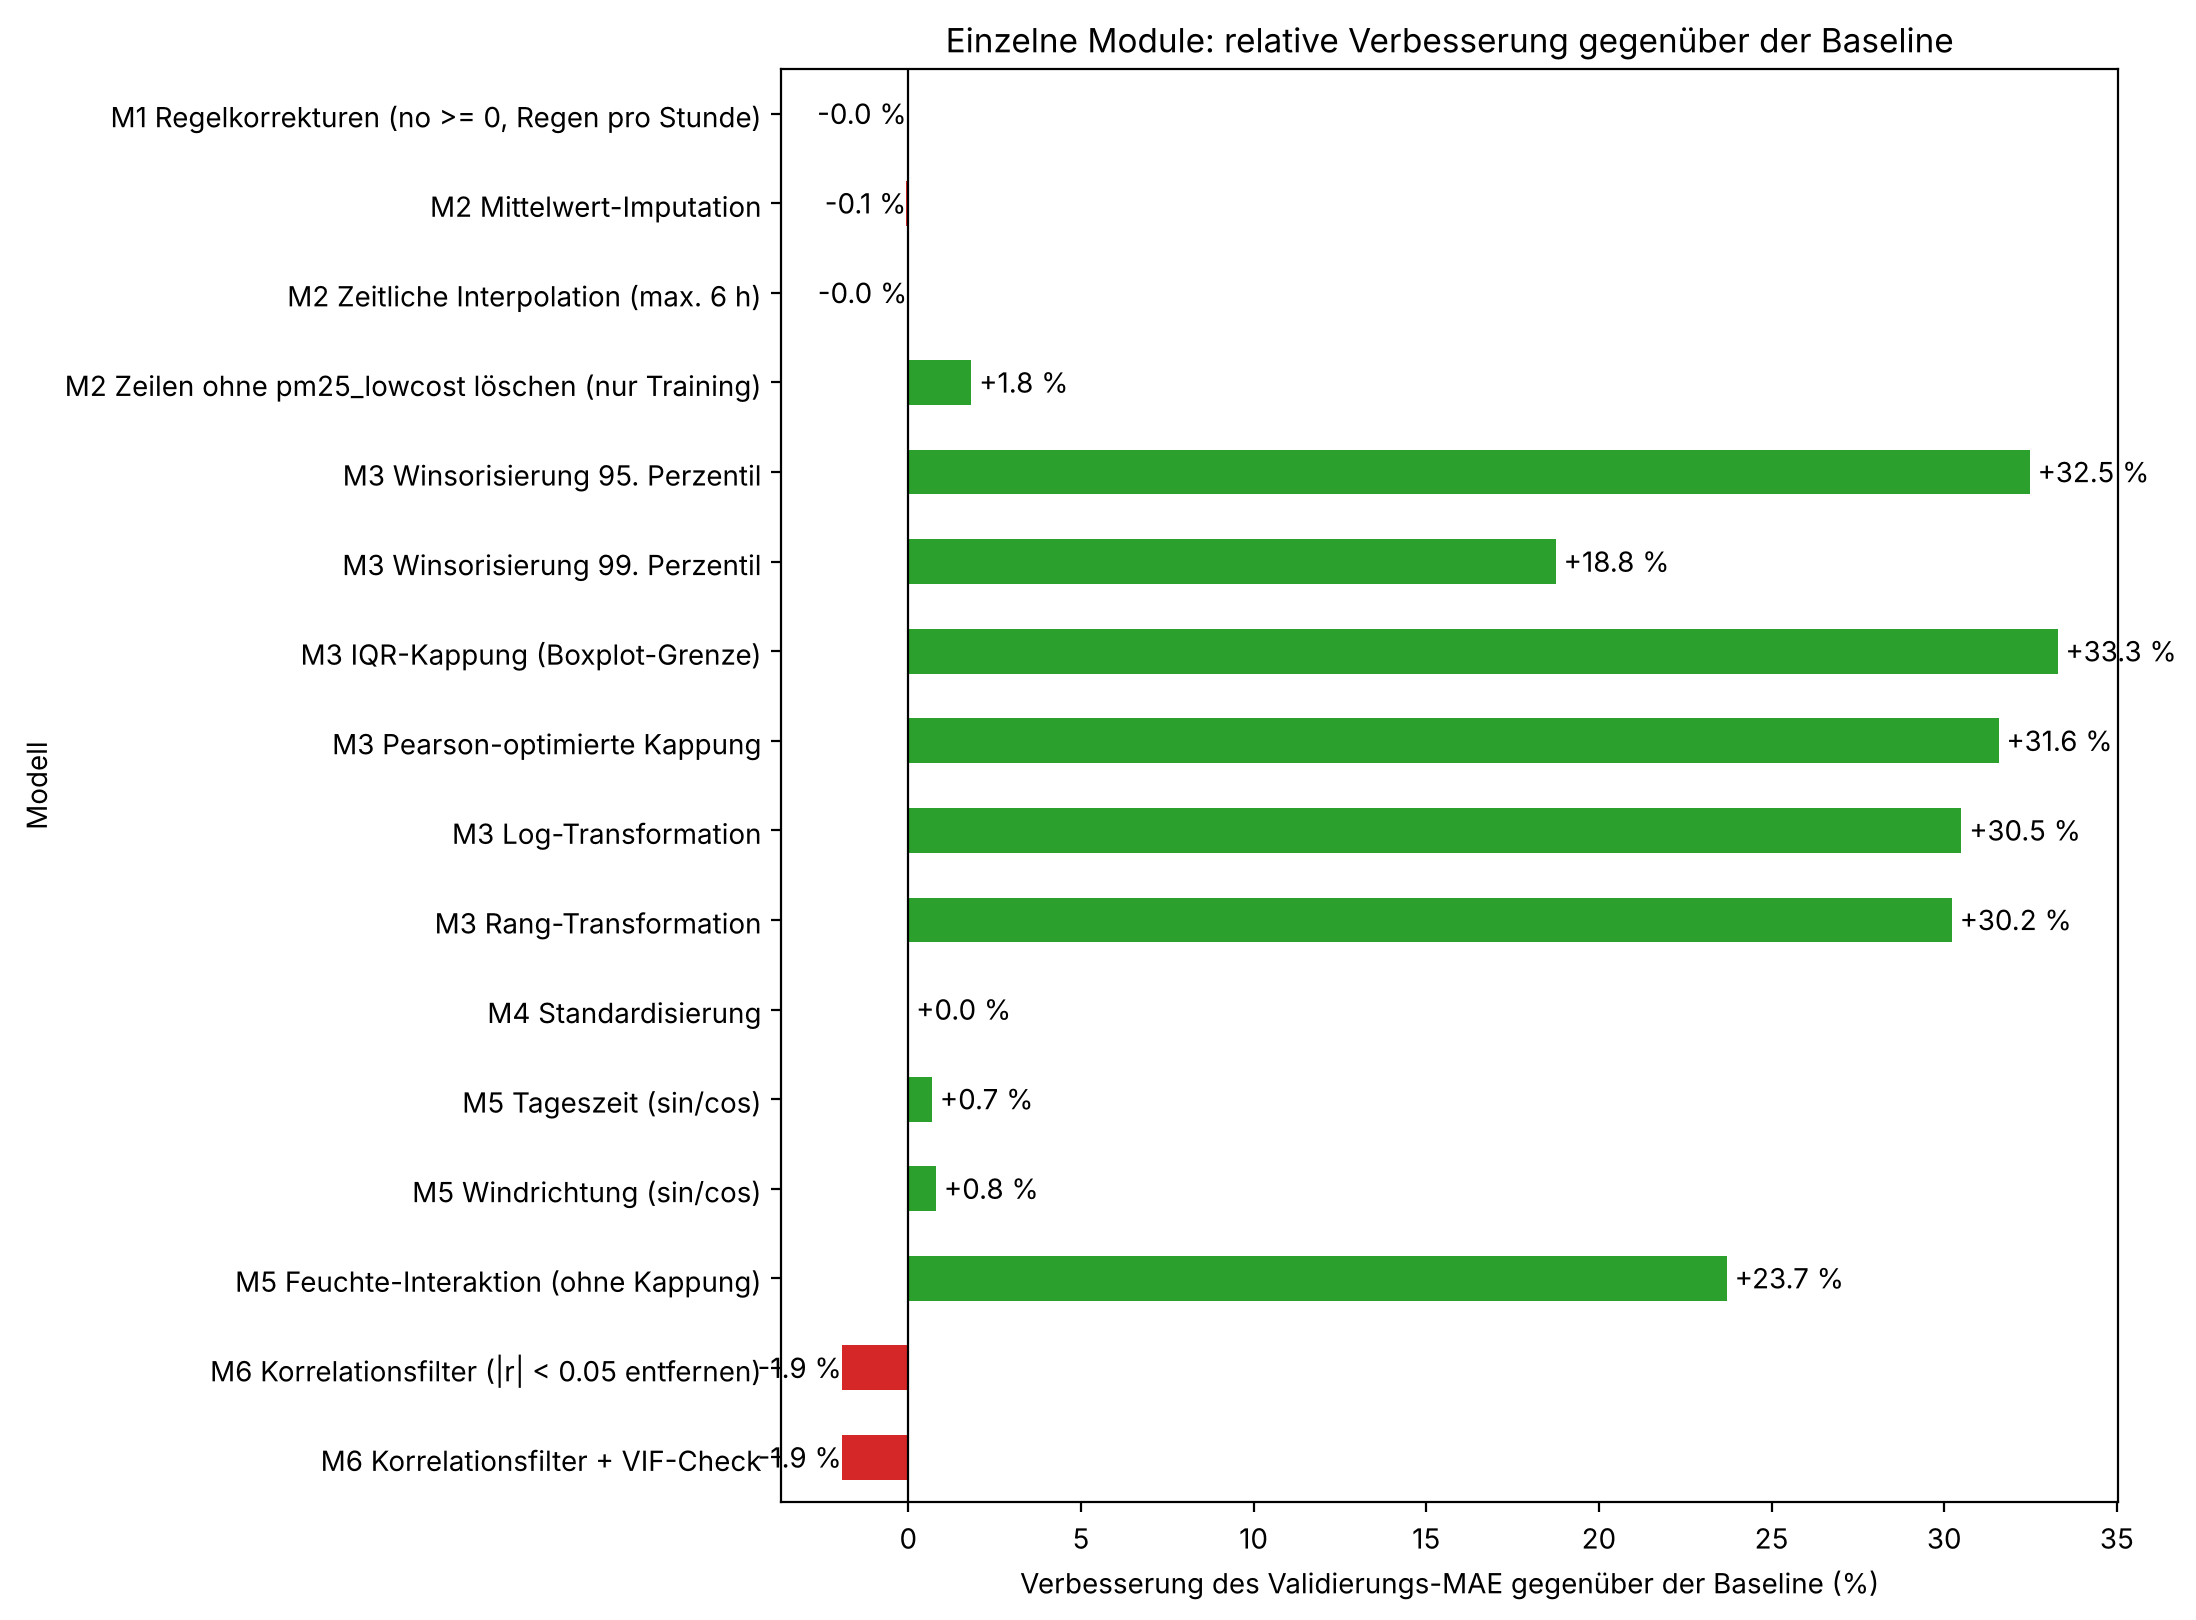

In [27]:
def plot_delta(log_df, rows, title):
    # Balkendiagramm: Verbesserung des Validierungs-MAE gegenüber der Baseline in %
    view = log_df.loc[rows].set_index("Modell")["Delta MAE (%)"]
    colors = ["tab:green" if value > 0 else "tab:red" for value in view]
    ax = view.plot.barh(figsize=(11, 0.45 * len(view) + 1), color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    for i, value in enumerate(view):
        ax.text(value, i, f" {value:+.1f} %", va="center", ha="left" if value >= 0 else "right")
    ax.set_title(title)
    ax.set_xlabel("Verbesserung des Validierungs-MAE gegenüber der Baseline (%)")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


plot_delta(log_df, log_df.index[1:], "Einzelne Module: relative Verbesserung gegenüber der Baseline")

**Interpretation der Einzel-Module:**

| Modul | Effekt auf Validierungs-MAE | Erklärung |
|---|---|---|
| **M3 Outlier Handling** | **−30 bis −33 %** (bester Wert: IQR-Kappung, MAE 0,85) | mit Abstand der größte Hebel; `pm25_lowcost` wird für das Modell erst nach der Kappung nutzbar |
| M3 Winsorisierung 99 % | −19 % | Grenze zu hoch, es bleiben zu viele Fehlwerte |
| M5 Feuchte-Interaktion (ohne Kappung) | −24 % | hilft, obwohl die Ausreißer noch im Feature stecken; das zeigt, wie stark der Feuchteeffekt ist |
| M2 Zeilen löschen (nur Training) | −1,8 % | kleiner Effekt; ohne erfundene Werte im wichtigsten Feature wird die Steigung sauberer gelernt |
| M5 Tageszeit / Windrichtung | je ca. −0,7 bis −0,8 % | kleiner Zusatznutzen |
| M1, M2 Mittelwert, M2 Interpolation | ±0,05 % | fachlich sinnvolle Korrekturen, aber ohne messbaren Effekt (zu wenige betroffene Werte bzw. lange Lücken) |
| M4 Standardisierung | **exakt 0 %** | bestätigt unsere Erwartung: Die lineare Regression gleicht eine lineare Skalierung über die Koeffizienten aus |
| M6 Korrelationsfilter | +1,9 % (schlechter) | `o3` und `rain_vol` sind einzeln kaum korreliert, tragen im Zusammenspiel aber noch etwas bei |

**Learnings:**
- Die **Pearson-optimierte Kappung** (85. Perzentil für `pm25_lowcost`) ist im Modell *schlechter* als die IQR-Grenze und das 95. Perzentil. Die maximale Einzelkorrelation ist also nicht automatisch die beste Grenze. Kappt man zu früh, verliert man auch echte, höhere Messwerte. Der Pearson/Spearman-Vergleich war vor allem nützlich, um **die richtigen Features** für das Outlier Handling zu finden und **das 99. Perzentil auszuschließen**.
- Die **Rang-Transformation**, also genau der Raum, in dem Spearman rechnet, ist im Modell schwächer als die Kappung. Laut Vorlesung verzerrt sie Abstände. Die lineare Regression braucht aber genau diese Abstände, z. B. dass 8 µg/m³ doppelt so viel ist wie 4 µg/m³.
- **Scaling** bringt bei der linearen Regression nichts (Feedback Vorjahr: „Analyse, warum Scaling nichts bringt"). Es wird erst für Task 3 relevant, z. B. bei regularisierten Modellen oder KNN.

## 7. Experimente: Kombinationen der Module

Im Vorjahr wurde angemerkt, dass auch **Kombinationen** der Maßnahmen untersucht werden sollten (z. B. Missing Values + Outlier). Einzelne Module können sich gegenseitig verstärken oder aufheben.

Für die Kombinationen verwenden wir **je Modul die beste Variante aus Abschnitt 6** (nach Validierungs-MAE). Die Auswahl erfolgt automatisch aus dem Log, damit sie nachvollziehbar und nicht „von Hand" gesetzt ist.

In [28]:
def best_variant(candidates, mapping):
    # Beste Variante nach Validierungs-MAE; mapping übersetzt den Modellnamen in die Einstellung des Moduls
    best_name = candidates.loc[candidates["MAE_val"].idxmin(), "Modell"]
    return best_name, mapping[best_name]


# Zuordnung Modellname -> Einstellung des Moduls
m2_mapping = {name: cfg["M2_missing"] for name, module, _, cfg in single_experiments if module == "M2"}
m2_mapping[log_df.loc[0, "Modell"]] = "median"     # die Baseline ist die Median-Variante von M2
m3_mapping = {name: cfg["M3_outliers"] for name, module, _, cfg in single_experiments if module == "M3"}

best_m2_name, BEST_M2 = best_variant(log_df[log_df["Modul"].isin(["Baseline", "M2"])], m2_mapping)
best_m3_name, BEST_M3 = best_variant(log_df[log_df["Modul"] == "M3"], m3_mapping)
print("Beste M2-Variante:", best_m2_name, "->", BEST_M2)
print("Beste M3-Variante:", best_m3_name, "->", BEST_M3)

Beste M2-Variante: M2 Zeilen ohne pm25_lowcost löschen (nur Training) -> drop_rows
Beste M3-Variante: M3 IQR-Kappung (Boxplot-Grenze) -> iqr


In [29]:
combo_start = len(results)

m2_text = "M2 " + BEST_M2
m3_text = "M3 " + BEST_M3
combo_experiments = [
    ("Kombi M1 + M2", "Kombi", "Regelkorrekturen + " + m2_text,
     {"M1_rules": True, "M2_missing": BEST_M2}),
    ("Kombi M2 + M3 (Missing Values + Outlier)", "Kombi", m2_text + " + " + m3_text,
     {"M2_missing": BEST_M2, "M3_outliers": BEST_M3}),
    ("Kombi M1 + M3", "Kombi", "Regelkorrekturen + " + m3_text,
     {"M1_rules": True, "M3_outliers": BEST_M3}),
    ("Kombi M1 + M2 + M3", "Kombi", "Regelkorrekturen + " + m2_text + " + " + m3_text,
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3}),
    ("Kombi M1-M3 + Tageszeit + Wind", "Kombi", "M1-M3 + hour/wind als sin/cos",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind"]}),
    ("Kombi M1-M3 + Feuchte-Interaktion", "Kombi", "M1-M3 + lowcost x humidity (aus gekappten Werten)",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["humidity"]}),
    ("Kombi M1-M3 + alle M5-Features", "Kombi", "M1-M3 + hour, wind, humidity",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind", "humidity"]}),
    ("Kombi M1-M3 + M5 + Korrelationsfilter", "Kombi", "M1-M3 + alle M5-Features + M6 corr",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind", "humidity"],
      "M6_selection": "corr"}),
    ("Kombi M1-M3 + M5 + Korrelationsfilter + VIF", "Kombi", "M1-M3 + alle M5-Features + M6 corr_vif",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind", "humidity"],
      "M6_selection": "corr_vif"}),
    ("Kombi Alle Module (M1-M6 inkl. Scaling)", "Kombi", "M1-M3 + M5 + M6 corr + Standardisierung",
     {"M1_rules": True, "M2_missing": BEST_M2, "M3_outliers": BEST_M3, "M5_features": ["hour", "wind", "humidity"],
      "M6_selection": "corr", "M4_scaling": "standard"}),
]

for name, module, description, config in combo_experiments:
    log_df, experiment_data[name] = run_experiment(name, module, description, config)

show_results(log_df, log_df.index[combo_start:])
print("M6 in der Kombination:", experiment_data["Kombi M1-M3 + M5 + Korrelationsfilter + VIF"]["info"]["M6"])

,Modell,Anzahl Features,MAE_train,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Overfitting-Lücke (MAE_val - MAE_train)
17,Kombi M1 + M2,14,1.3428,1.2474,0.3350,0.0264,2.0713,-0.0954
18,Kombi M2 + M3 (Missing Values + Outlier),14,0.8592,0.8650,0.6666,0.4088,32.0916,0.0058
19,Kombi M1 + M3,14,0.8291,0.8522,0.6776,0.4216,33.0989,0.0231
20,Kombi M1 + M2 + M3,14,0.8517,0.8655,0.6638,0.4083,32.0533,0.0138
21,Kombi M1-M3 + Tageszeit + Wind,17,0.8420,0.8698,0.6746,0.4040,31.7181,0.0278
22,Kombi M1-M3 + Feuchte-Interaktion,15,0.7235,0.7932,0.7397,0.4806,37.7317,0.0697
23,Kombi M1-M3 + alle M5-Features,18,0.7162,0.7862,0.7447,0.4876,38.2781,0.0700
24,Kombi M1-M3 + M5 + Korrelationsfilter,16,0.7277,0.8022,0.7389,0.4716,37.0205,0.0745
25,Kombi M1-M3 + M5 + Korrelationsfilter + VIF,15,0.8548,0.8889,0.6677,0.3849,30.2160,0.0341
26,Kombi Alle Module (M1-M6 inkl. Scaling),16,0.7277,0.8022,0.7389,0.4716,37.0205,0.0745


M6 in der Kombination: {'Methode': 'corr_vif', 'entfernt (Korrelation)': ['o3', 'rain_hourly'], 'entfernt (VIF)': ['lowcost_x_humidity']}


### 7.1 Kombinationsmatrix: Gilt die beste Einzelvariante auch in der Kombination?

Bisher haben wir für jedes Modul die Variante genommen, die **allein** am besten war. Das muss in Kombination nicht stimmen: Eine Maßnahme kann ein Problem lösen, das ein anderes Modul ohnehin schon löst. Deshalb testen wir systematisch eine kleine Matrix aus

- **M2:** Median (Baseline) und beste Einzelvariante
- **M3:** die drei besten Outlier-Methoden aus Abschnitt 6
- **M5:** Tageszeit + Wind bzw. alle drei M5-Features

M1 ist immer aktiv. Kombinationen, die schon in Abschnitt 7 enthalten sind, werden übersprungen.

In [30]:
matrix_start = len(results)
m3_ranking = log_df[log_df["Modul"] == "M3"].sort_values("MAE_val")
top_m3 = [m3_mapping[name] for name in m3_ranking["Modell"]][:3]
m2_options = ["median", BEST_M2] if BEST_M2 != "median" else ["median"]
fe_options = {"Tageszeit + Wind": ["hour", "wind"], "alle M5-Features": ["hour", "wind", "humidity"]}

matrix_configs = {}
for m2 in m2_options:
    for m3 in top_m3:
        for fe_name, fe_list in fe_options.items():
            if m2 == BEST_M2 and m3 == BEST_M3:
                continue   # bereits in Abschnitt 7 enthalten
            name = "Matrix M1 + M2 " + m2 + " + M3 " + m3 + " + " + fe_name
            config = {"M1_rules": True, "M2_missing": m2, "M3_outliers": m3, "M5_features": fe_list}
            matrix_configs[name] = config
            log_df, experiment_data[name] = run_experiment(name, "Matrix", "M2 = " + m2 + ", M3 = " + m3 + ", M5 = " + fe_name, config)

show_results(log_df, log_df.index[matrix_start:])

,Modell,Anzahl Features,MAE_train,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Overfitting-Lücke (MAE_val - MAE_train)
27,Matrix M1 + M2 median + M3 iqr + Tageszeit + Wind,17,0.8246,0.8474,0.6902,0.4264,33.4755,0.0228
28,Matrix M1 + M2 median + M3 iqr + alle M5-Features,18,0.7489,0.7906,0.7471,0.4832,37.9333,0.0418
29,Matrix M1 + M2 median + M3 winsor95 + Tageszei...,17,0.8521,0.8630,0.6535,0.4108,32.2512,0.0109
30,Matrix M1 + M2 median + M3 winsor95 + alle M5-...,18,0.7492,0.7822,0.7440,0.4916,38.5964,0.0330
31,Matrix M1 + M2 median + M3 pearson_opt + Tages...,17,0.8414,0.8708,0.6687,0.4030,31.6405,0.0294
32,Matrix M1 + M2 median + M3 pearson_opt + alle ...,18,0.8087,0.8526,0.6941,0.4212,33.0664,0.0439
33,Matrix M1 + M2 drop_rows + M3 winsor95 + Tages...,17,0.8628,0.8791,0.6458,0.3947,30.9845,0.0163
34,Matrix M1 + M2 drop_rows + M3 winsor95 + alle ...,18,0.7171,0.7807,0.7395,0.4931,38.7122,0.0636
35,Matrix M1 + M2 drop_rows + M3 pearson_opt + Ta...,17,0.8356,0.8729,0.6707,0.4009,31.4741,0.0373
36,Matrix M1 + M2 drop_rows + M3 pearson_opt + al...,18,0.7727,0.8400,0.7012,0.4338,34.0553,0.0673


**Interpretation der Kombinationen:**

- **Missing Values + Outlier (M2 + M3):** Die Zeilenlöschung, als Einzelmodul die beste M2-Variante, bringt **in Kombination mit M3 keinen Vorteil mehr**. „M1 + M3" (Median, MAE 0,852) ist sogar etwas besser als „M1 + M2 + M3" (Zeilenlöschung, 0,866). Erklärung: Die Zeilenlöschung half vor allem, weil das Modell weniger durch die verzerrte Steigung von `pm25_lowcost` gestört wurde. Dieses Problem löst M3 ohnehin, und die Löschung kostet zusätzlich 270 Trainingszeilen. **Die beste Einzelvariante ist also nicht automatisch die beste Variante in der Kombination.** Genau deshalb war die Kombinationsmatrix wichtig.
- **Feuchte-Interaktion:** Auf den gekappten Werten bringt sie den nächsten großen Schritt (von ca. 0,85–0,87 auf **0,79**). Tageszeit und Wind helfen allein kaum, zusammen mit der Feuchte-Interaktion aber noch leicht.
- **Feature Selection (M6) in der Kombination:** Der Korrelationsfilter verschlechtert leicht (0,786 → 0,802). Der VIF-Check entfernt `lowcost_x_humidity`, weil es stark mit `pm25_lowcost` zusammenhängt, und verschlechtert deutlich (→ 0,889). **Learning:** Ein hoher VIF bedeutet „ähnlich", nicht „überflüssig". Das Interaktionsfeature ist mit `pm25_lowcost` korreliert, enthält aber genau die zusätzliche Feuchte-Information.
- **Scaling** verändert auch in der Gesamtkombination nichts (identische Werte mit und ohne M4).
- **Matrix:** Die vier besten Modelle liegen alle bei **MAE 0,78–0,79** und unterscheiden sich um weniger als 0,01 µg/m³. Ihre gemeinsame Basis ist entscheidend: **M1 + Kappung der drei Ausreißer-Features + alle M5-Features**. Ob Median oder Zeilenlöschung und ob 95. Perzentil oder IQR-Grenze, spielt dagegen kaum eine Rolle.

## 8. Gesamtvergleich, Overfitting-Check und Auswahl des finalen Modells

### 8.1 Alle Ergebnisse im Überblick

Das vollständige Log (inkl. Beschreibung jedes Datensatzes) liegt zusätzlich in `Output/evaluation_log.csv`.

In [31]:
overview = log_df.sort_values("MAE_val").reset_index(drop=True)
overview.index = overview.index + 1   # Rangplatz
display(overview[["Modell", "Modul", "Anzahl Features", "MAE_val", "R2_val", "Delta MAE (abs)", "Delta MAE (%)",
                  "Delta R2 (abs)"]].round(4))

,Modell,Modul,Anzahl Features,MAE_val,R2_val,Delta MAE (abs),Delta MAE (%),Delta R2 (abs)
1,Matrix M1 + M2 drop_rows + M3 winsor95 + alle ...,Matrix,18,0.7807,0.7395,0.4931,38.7122,0.4200
2,Matrix M1 + M2 median + M3 winsor95 + alle M5-...,Matrix,18,0.7822,0.7440,0.4916,38.5964,0.4245
3,Kombi M1-M3 + alle M5-Features,Kombi,18,0.7862,0.7447,0.4876,38.2781,0.4252
4,Matrix M1 + M2 median + M3 iqr + alle M5-Features,Matrix,18,0.7906,0.7471,0.4832,37.9333,0.4276
5,Kombi M1-M3 + Feuchte-Interaktion,Kombi,15,0.7932,0.7397,0.4806,37.7317,0.4202
6,Kombi M1-M3 + M5 + Korrelationsfilter,Kombi,16,0.8022,0.7389,0.4716,37.0205,0.4194
7,Kombi Alle Module (M1-M6 inkl. Scaling),Kombi,16,0.8022,0.7389,0.4716,37.0205,0.4194
8,Matrix M1 + M2 drop_rows + M3 pearson_opt + al...,Matrix,18,0.8400,0.7012,0.4338,34.0553,0.3817
9,Matrix M1 + M2 median + M3 iqr + Tageszeit + Wind,Matrix,17,0.8474,0.6902,0.4264,33.4755,0.3707
10,M3 IQR-Kappung (Boxplot-Grenze),M3,14,0.8498,0.6807,0.4240,33.2860,0.3612


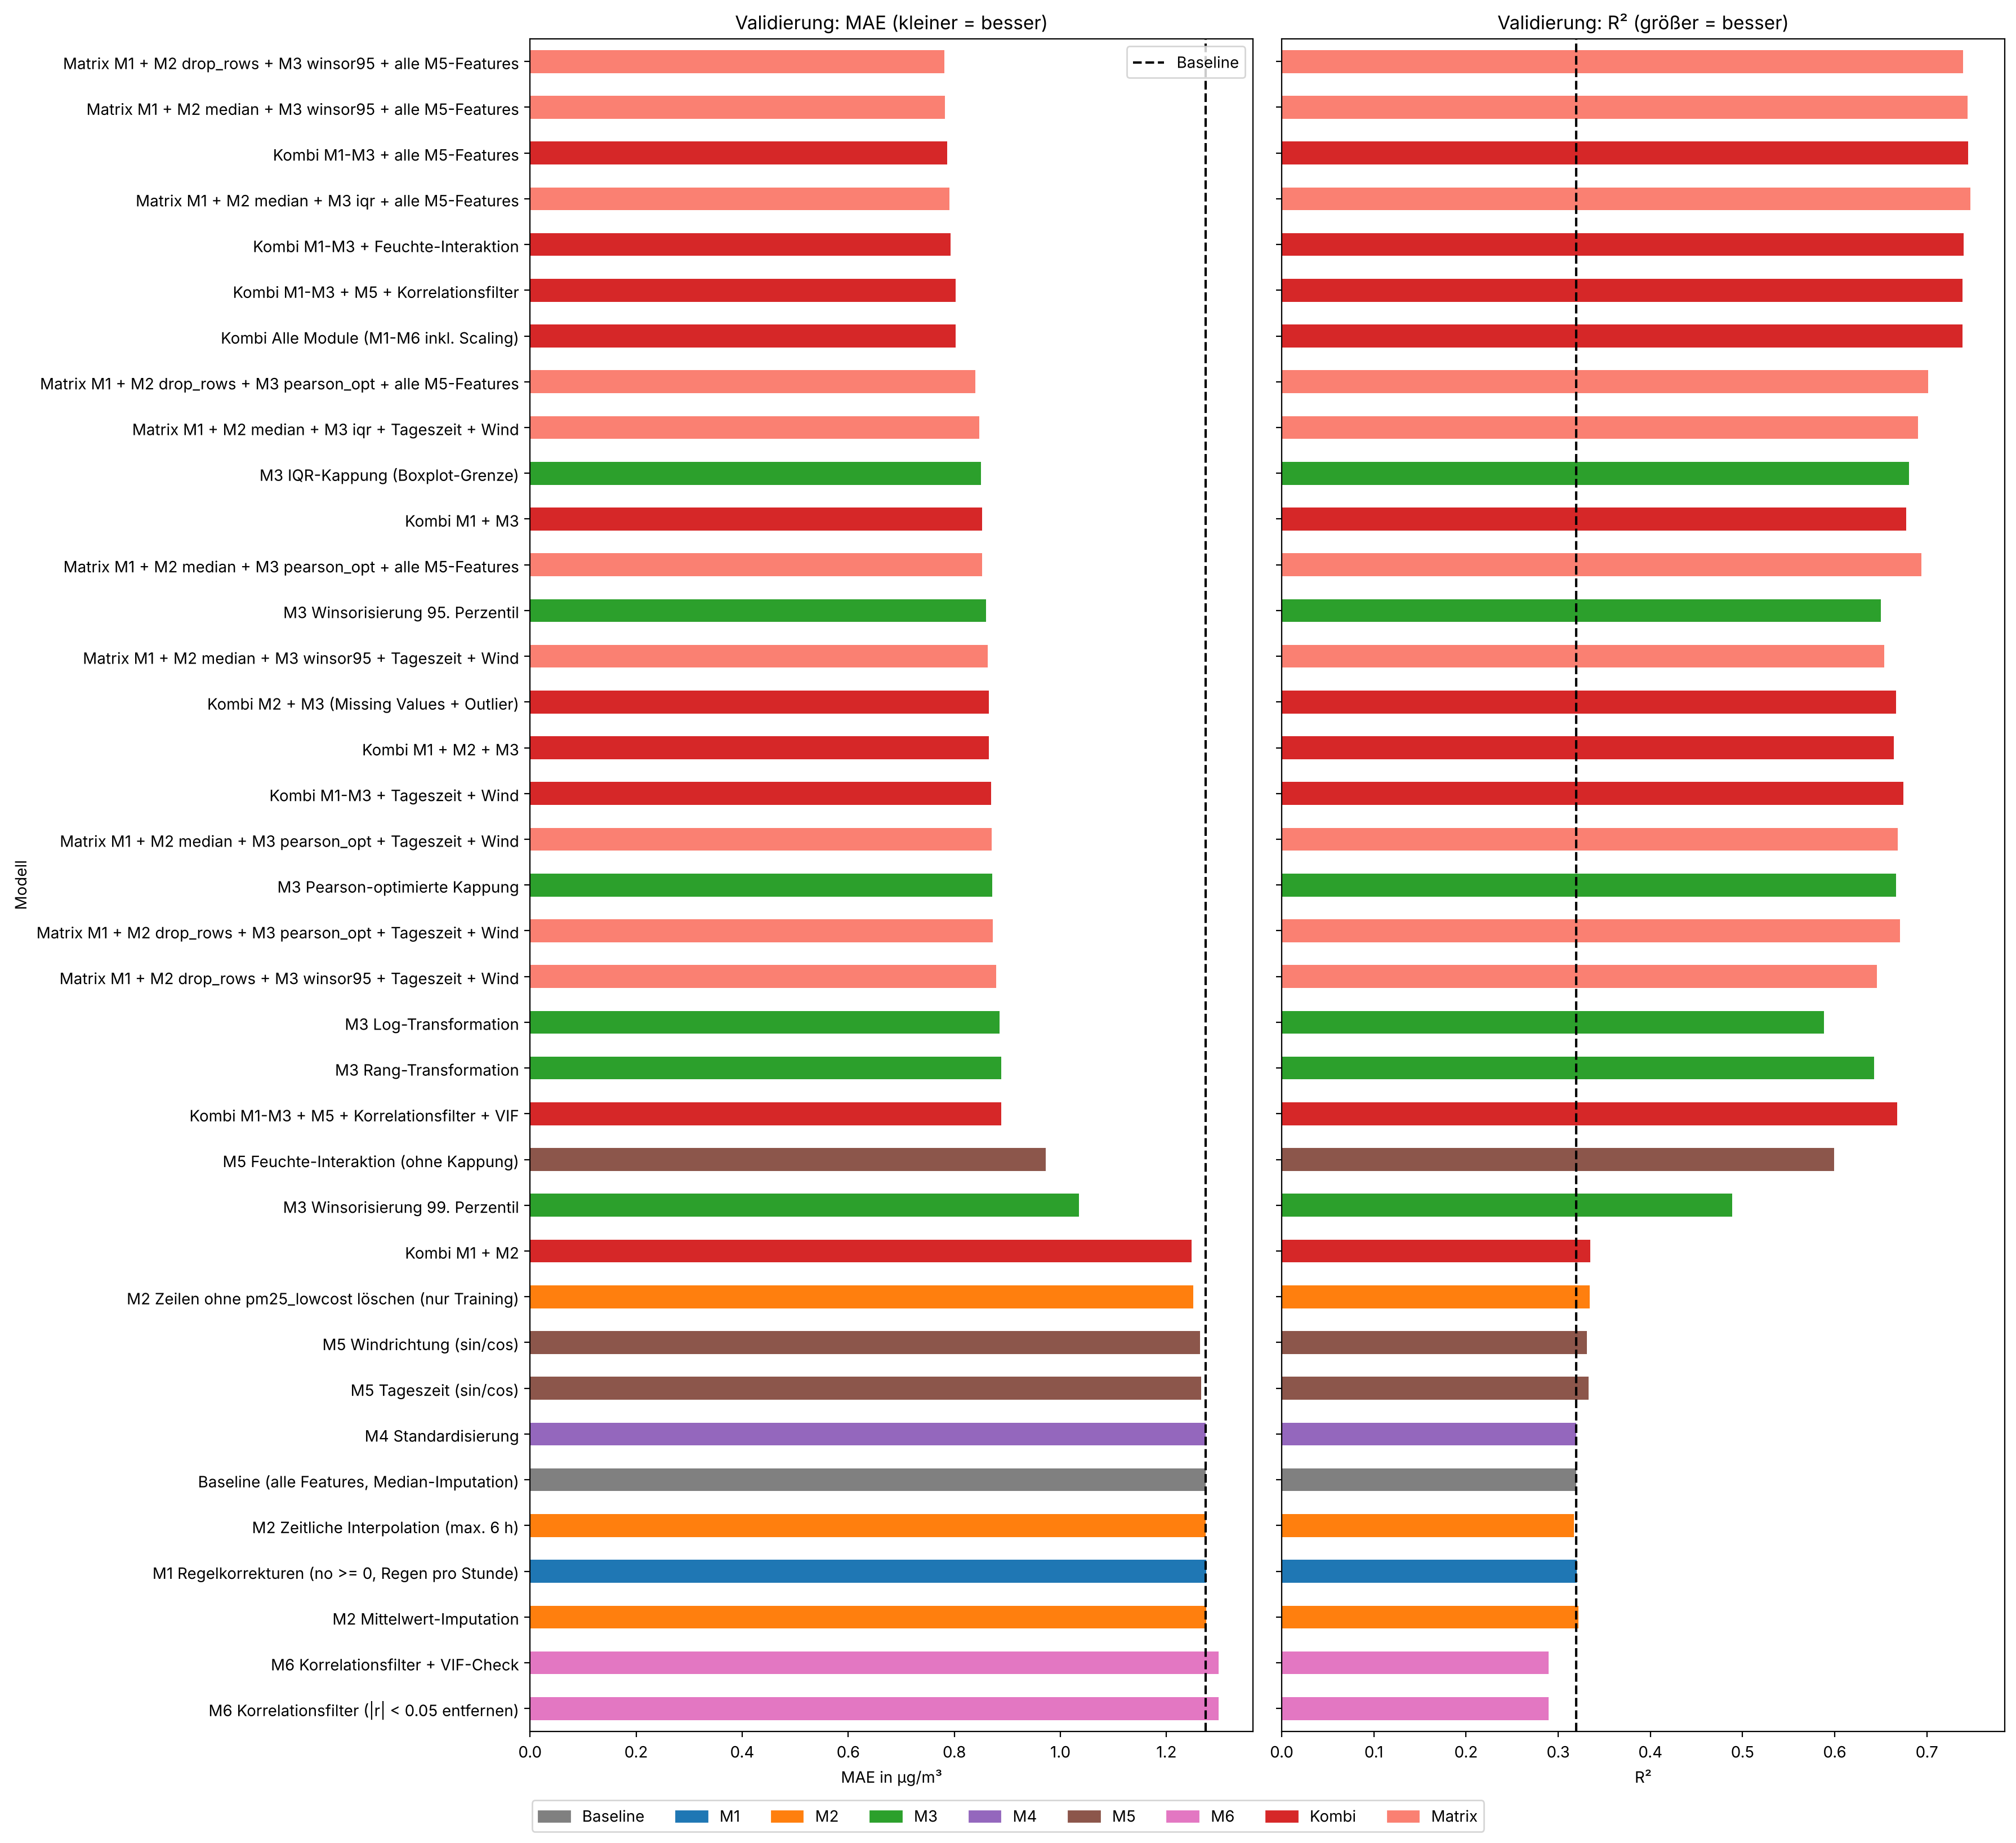

In [32]:
# Grafische Gegenüberstellung aller Modelle: absoluter MAE und R² auf der Validierung
plot_df = log_df.sort_values("MAE_val", ascending=False).set_index("Modell")
module_colors = {"Baseline": "grey", "M1": "tab:blue", "M2": "tab:orange", "M3": "tab:green", "M4": "tab:purple",
                 "M5": "tab:brown", "M6": "tab:pink", "Kombi": "tab:red", "Matrix": "salmon"}
colors = [module_colors[m] for m in plot_df["Modul"]]

fig, axes = plt.subplots(1, 2, figsize=(18, 0.38 * len(plot_df) + 2), sharey=True)
plot_df["MAE_val"].plot.barh(ax=axes[0], color=colors)
baseline_line = axes[0].axvline(baseline_metrics["MAE_val"], color="black", linestyle="--", label="Baseline")
axes[0].set_title("Validierung: MAE (kleiner = besser)")
axes[0].set_xlabel("MAE in µg/m³")
axes[0].legend(handles=[baseline_line])

plot_df["R2_val"].plot.barh(ax=axes[1], color=colors)
axes[1].axvline(baseline_metrics["R2_val"], color="black", linestyle="--")
axes[1].set_title("Validierung: R² (größer = besser)")
axes[1].set_xlabel("R²")

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in module_colors.values()]
fig.legend(handles, module_colors.keys(), loc="lower center", ncol=len(module_colors), bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.show()

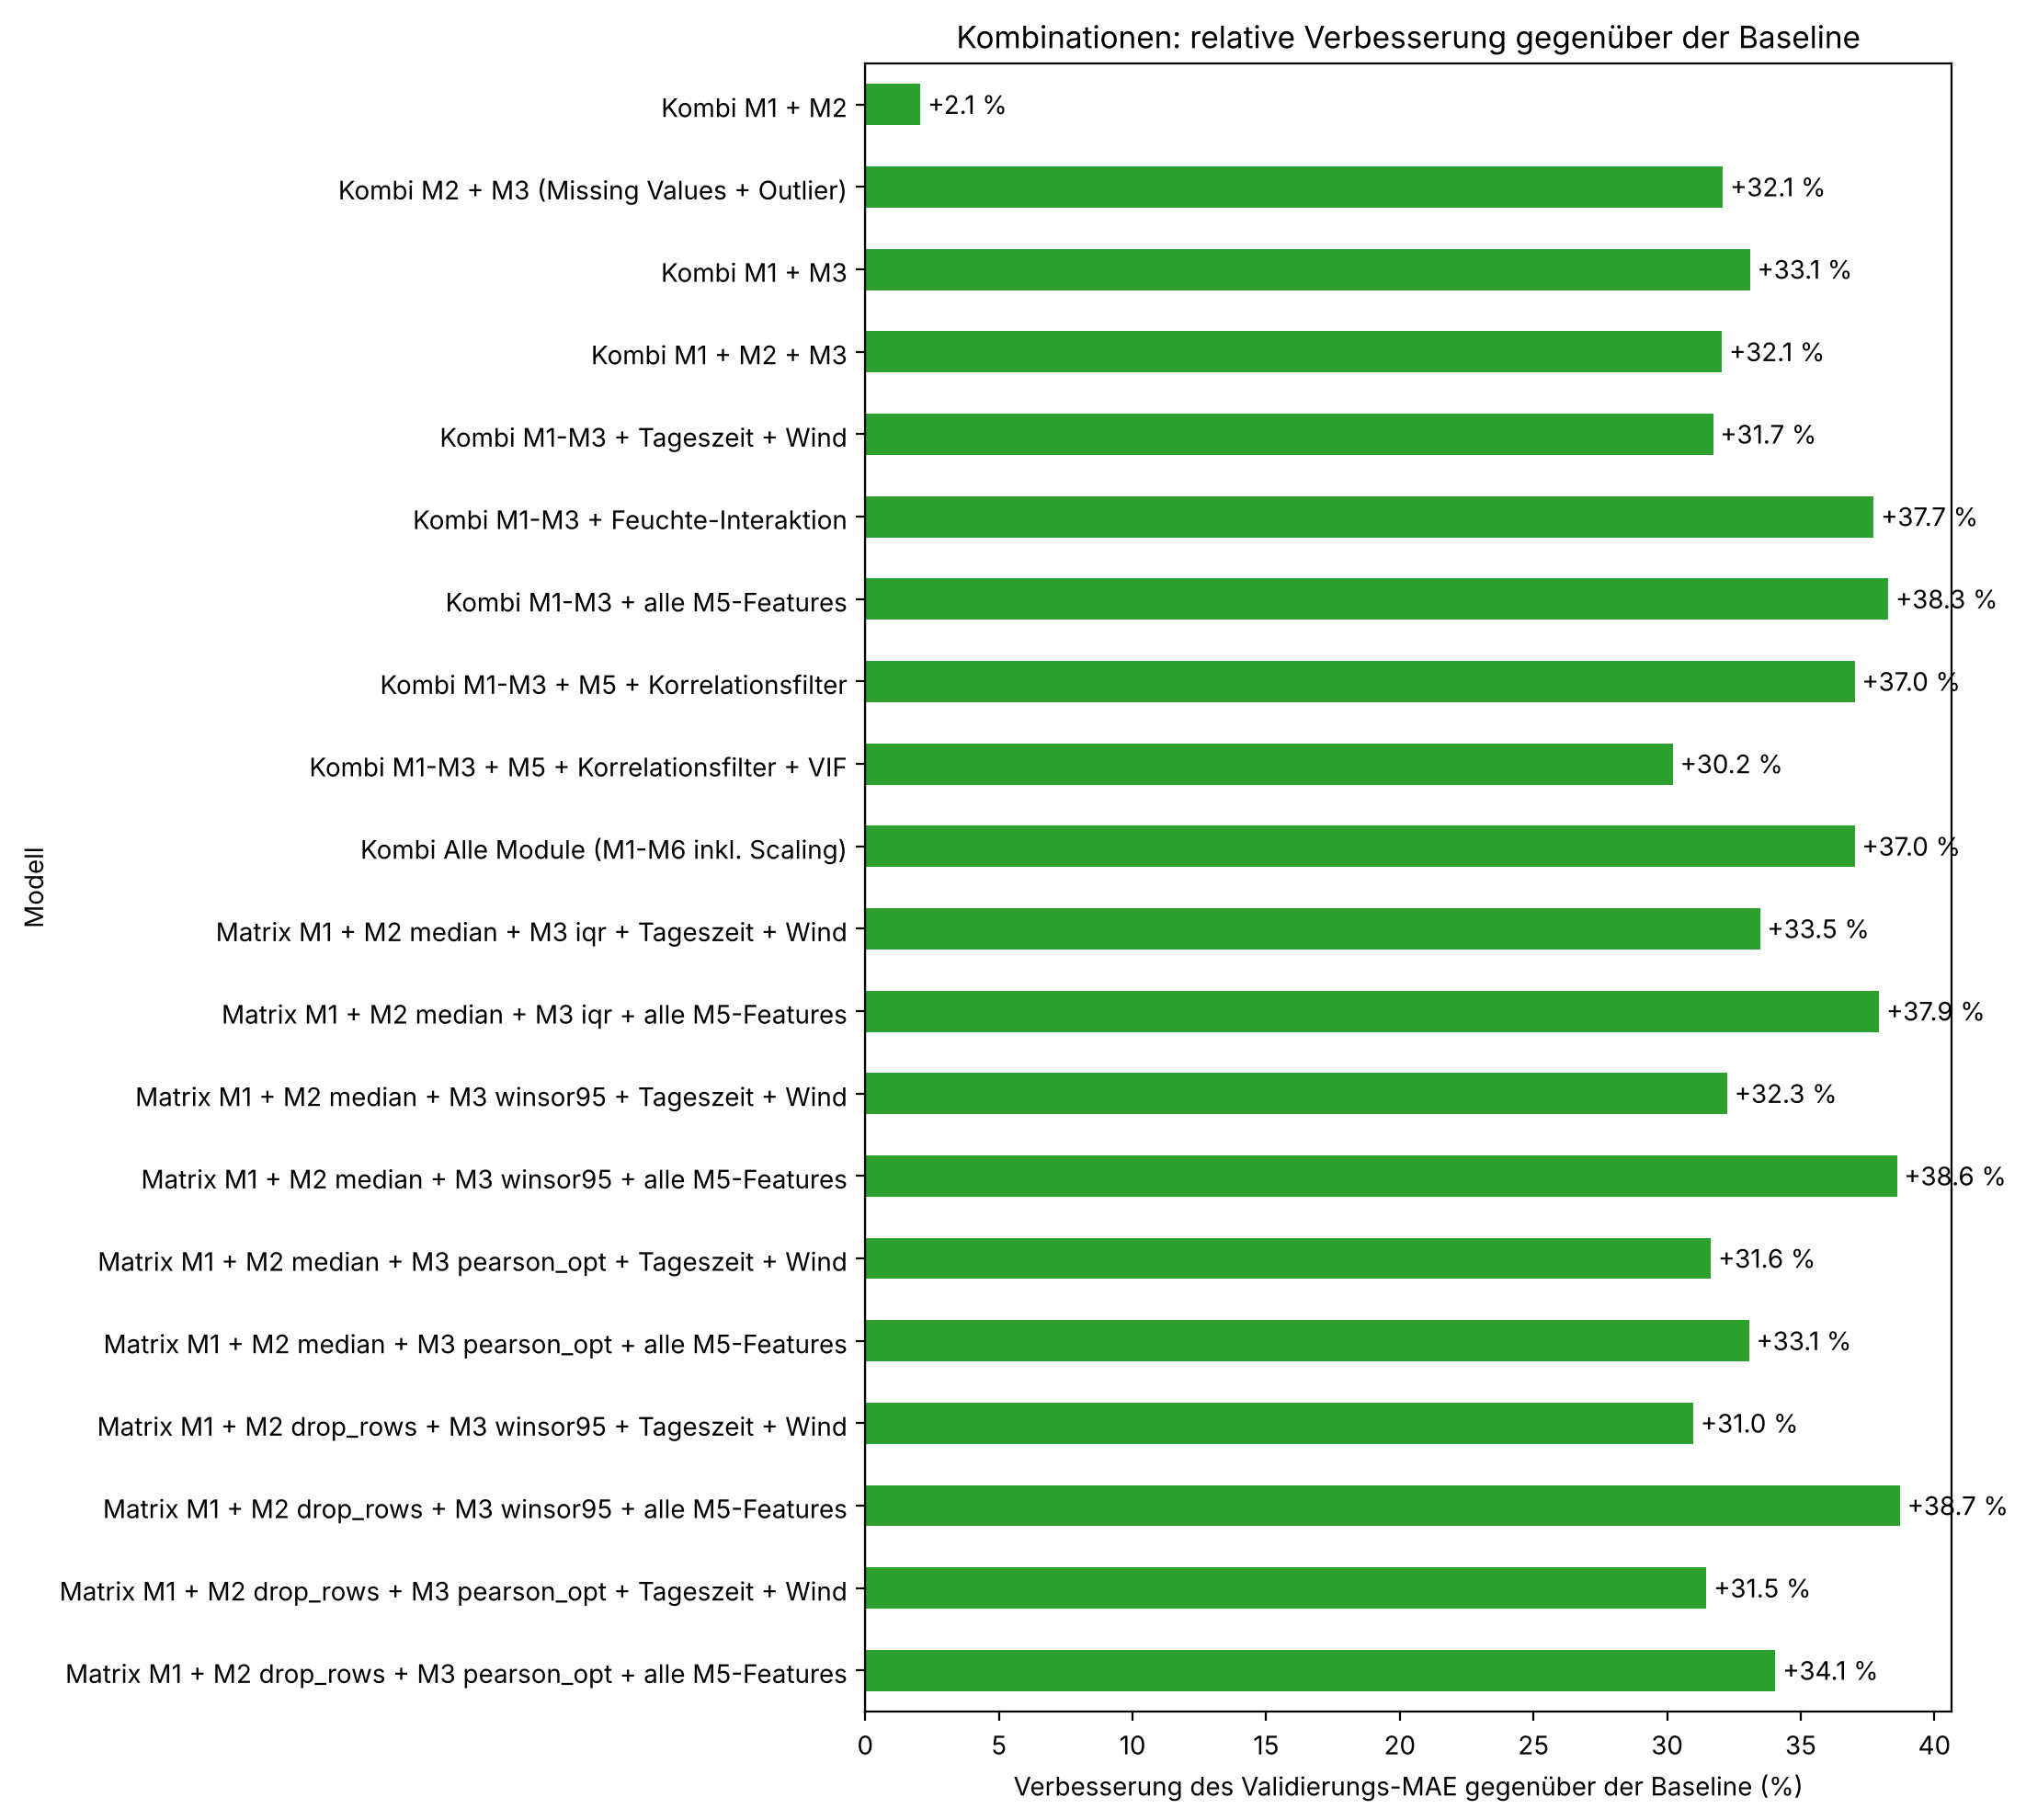

In [33]:
plot_delta(log_df, log_df.index[combo_start:], "Kombinationen: relative Verbesserung gegenüber der Baseline")

### 8.2 Auswahl des finalen Modells

**Auswahlregel (vor dem Blick auf den Test festgelegt):** Das Modell mit dem **kleinsten Validierungs-MAE** wird zum finalen Modell. Über die Kombinationsmatrix ist sichergestellt, dass wir nicht nur die naheliegende Kombination der Einzelsieger betrachten.

In [34]:
final_name = log_df.loc[log_df["MAE_val"].idxmin(), "Modell"]
final_row = log_df.loc[log_df["MAE_val"].idxmin()]
all_configs = {name: cfg for name, _, _, cfg in single_experiments + combo_experiments}
all_configs.update(matrix_configs)
FINAL_CONFIG = {**BASE_CONFIG, **all_configs[final_name]}

print("Finales Modell:", final_name)
print("Konfiguration:", FINAL_CONFIG)
print("Validierung MAE:", round(final_row["MAE_val"], 4), "| R²:", round(final_row["R2_val"], 4))
print("Verbesserung ggü. Baseline:", round(final_row["Delta MAE (abs)"], 4), "µg/m³ bzw.",
      round(final_row["Delta MAE (%)"], 2), "%")

Finales Modell: Matrix M1 + M2 drop_rows + M3 winsor95 + alle M5-Features
Konfiguration: {'M1_rules': True, 'M2_missing': 'drop_rows', 'M3_outliers': 'winsor95', 'M4_scaling': None, 'M5_features': ['hour', 'wind', 'humidity'], 'M6_selection': None}
Validierung MAE: 0.7807 | R²: 0.7395
Verbesserung ggü. Baseline: 0.4931 µg/m³ bzw. 38.71 %


### 8.3 Overfitting-Check: Training vs. Validierung

Overfitting erkennt man daran, dass ein Modell auf den Trainingsdaten deutlich besser ist als auf unbekannten Daten. Wir vergleichen daher MAE und R² auf Training und Validierung für die Baseline, die Kombinationen aus Abschnitt 7 und das finale Modell.

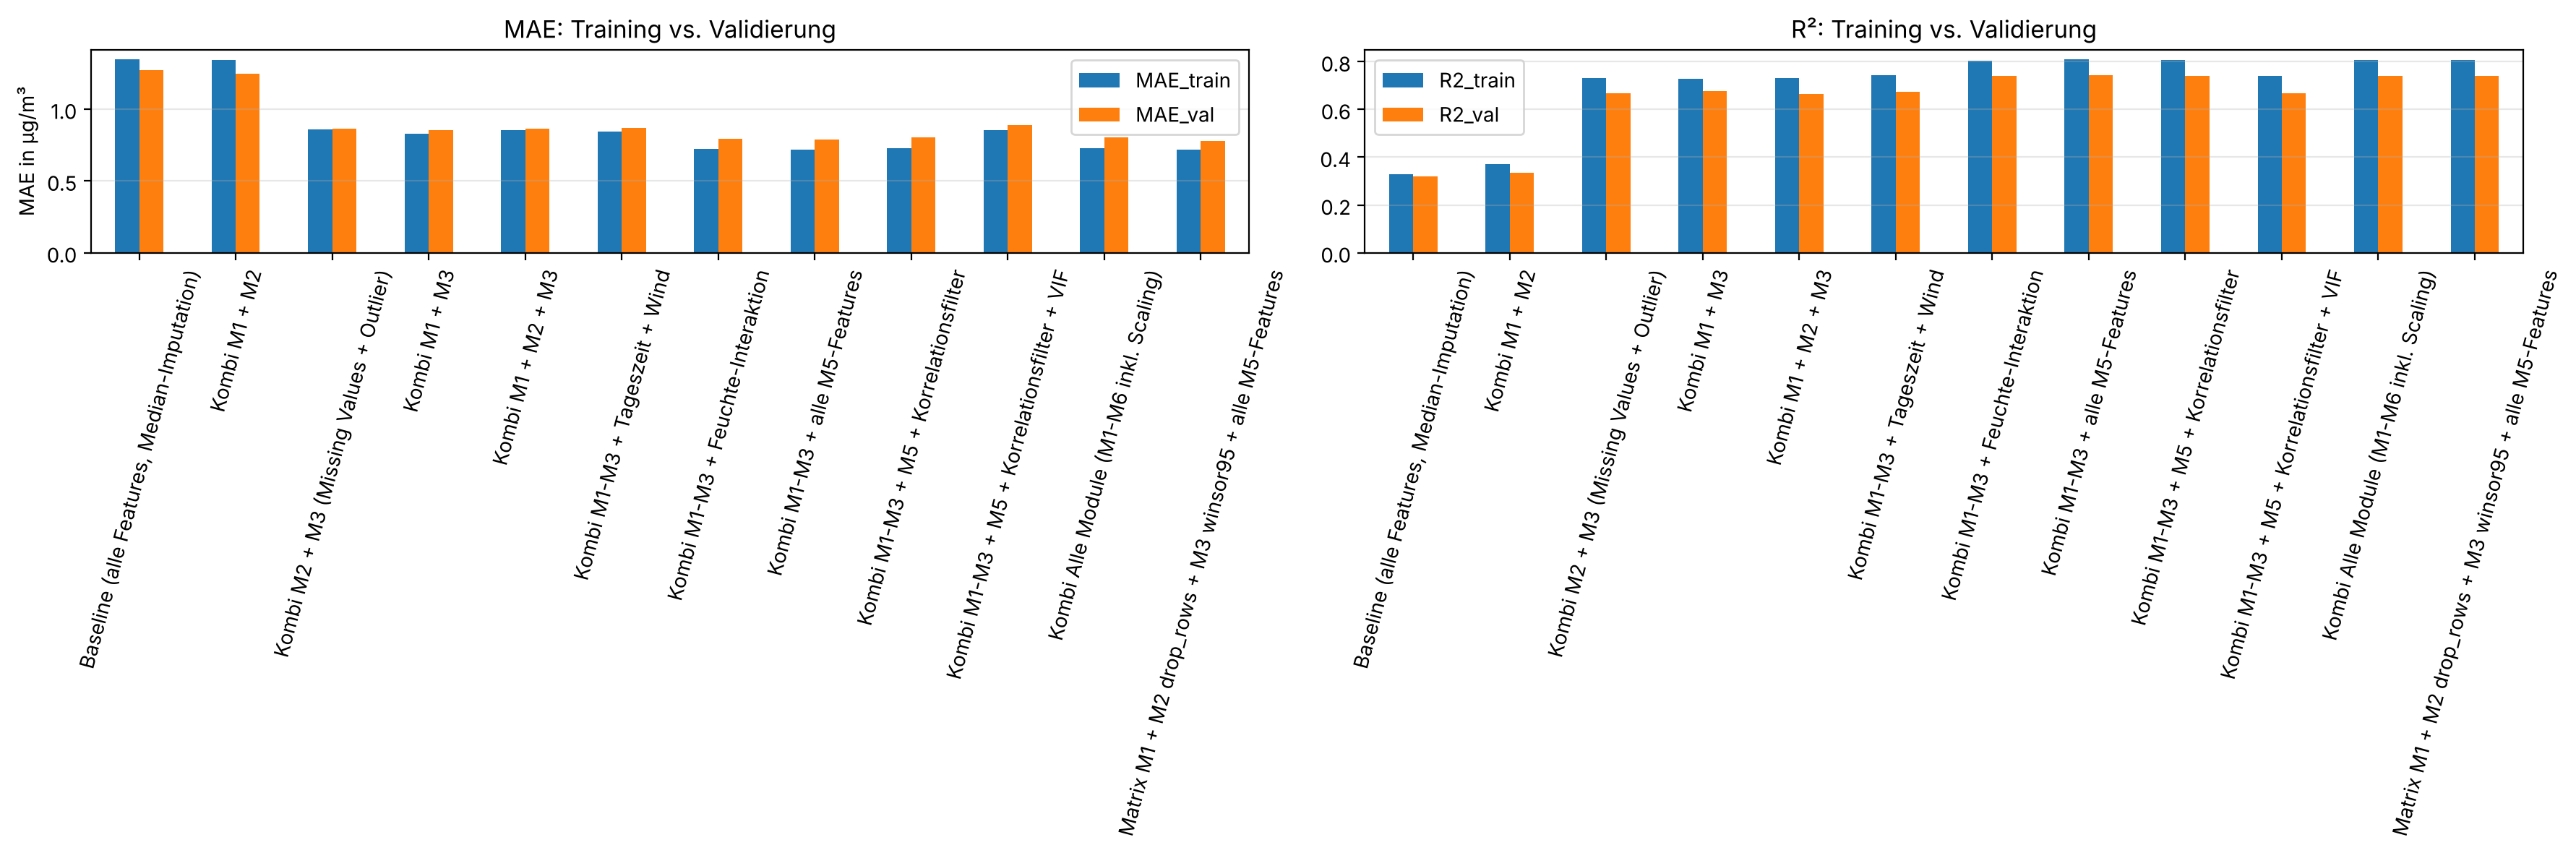

,MAE_train,MAE_val,Overfitting-Lücke (MAE_val - MAE_train),R2_train,R2_val
Modell,,,,,
"Baseline (alle Features, Median-Imputation)",1.3457,1.2738,-0.0718,0.3298,0.3195
Kombi M1 + M2,1.3428,1.2474,-0.0954,0.3698,0.3350
Kombi M2 + M3 (Missing Values + Outlier),0.8592,0.8650,0.0058,0.7301,0.6666
Kombi M1 + M3,0.8291,0.8522,0.0231,0.7269,0.6776
Kombi M1 + M2 + M3,0.8517,0.8655,0.0138,0.7298,0.6638
Kombi M1-M3 + Tageszeit + Wind,0.8420,0.8698,0.0278,0.7427,0.6746
Kombi M1-M3 + Feuchte-Interaktion,0.7235,0.7932,0.0697,0.8034,0.7397
Kombi M1-M3 + alle M5-Features,0.7162,0.7862,0.0700,0.8090,0.7447
Kombi M1-M3 + M5 + Korrelationsfilter,0.7277,0.8022,0.0745,0.8067,0.7389


In [35]:
final_idx = log_df["MAE_val"].idxmin()
of_rows = [0] + list(range(combo_start, matrix_start)) + ([final_idx] if final_idx >= matrix_start else [])
of_df = log_df.loc[of_rows].set_index("Modell")

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
of_df[["MAE_train", "MAE_val"]].plot.bar(ax=axes[0], rot=75)
axes[0].set_title("MAE: Training vs. Validierung")
axes[0].set_ylabel("MAE in µg/m³")
of_df[["R2_train", "R2_val"]].plot.bar(ax=axes[1], rot=75)
axes[1].set_title("R²: Training vs. Validierung")
for ax in axes:
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(of_df[["MAE_train", "MAE_val", "Overfitting-Lücke (MAE_val - MAE_train)", "R2_train", "R2_val"]].round(4))

**Interpretation Overfitting:**
- Bei allen Modellen liegen Trainings- und Validierungsfehler nah beieinander. Die größte Lücke beträgt etwa **0,07 µg/m³** (ca. 9 % des MAE), das R² sinkt von etwa 0,81 auf 0,74.
- Die Lücke wächst mit den M5-Features leicht an: Mehr Features bedeuten etwas mehr Anpassung an die Trainingsdaten. Für eine lineare Regression mit 18 Features und rund 2.500 Trainingszeilen ist das aber unkritisch. Wir sehen **kein relevantes Overfitting**.
- Bei der Baseline ist die Validierung sogar besser als das Training. Ursache sind die Ausreißer, die zufällig im Trainingsanteil liegen.

**Wichtig:** Dieser Check zeigt nur, dass das Modell innerhalb **desselben Zeitraums** (Juni–Oktober) gut generalisiert. Ob es auf einen anderen Zeitraum übertragbar ist, zeigt erst der Test.

## 9. Finales Modell auf den Testdaten

Erst jetzt verwenden wir die Testdaten. Die Pipeline lernt alle Parameter auf dem Trainingsanteil und wendet sie unverändert auf die Testdaten an. Zum fairen Vergleich bewerten wir die **Baseline** mit denselben Trainingsdaten ebenfalls auf dem Test.

Wie in Task 1 bleiben alle 1.464 Testzeilen erhalten; MAE/R² werden nur auf den Zeilen mit Label berechnet.

In [36]:
def evaluate_on_test(config):
    data = run_pipeline(config)
    feats = data["features"]
    model = LinearRegression().fit(data["train"][feats], data["train"][TARGET])
    has_label = data["test"][TARGET].notna().to_numpy()
    y_true = data["test"].loc[has_label, TARGET]
    y_pred = model.predict(data["test"][feats])
    return {"MAE": mean_absolute_error(y_true, y_pred[has_label]), "R2": r2_score(y_true, y_pred[has_label]),
            "pred": y_pred, "model": model, "data": data}


test_baseline = evaluate_on_test({})
test_final = evaluate_on_test(FINAL_CONFIG)

test_overview = pd.DataFrame({
    "MAE_val": [baseline_metrics["MAE_val"], final_row["MAE_val"]],
    "MAE_test": [test_baseline["MAE"], test_final["MAE"]],
    "R2_val": [baseline_metrics["R2_val"], final_row["R2_val"]],
    "R2_test": [test_baseline["R2"], test_final["R2"]],
}, index=["Baseline", "Finales Modell: " + final_name])
test_overview["Delta MAE_test ggü. Baseline (%)"] = (test_baseline["MAE"] - test_overview["MAE_test"]) / test_baseline["MAE"] * 100
display(test_overview.round(4))

print("Testzeilen gesamt:", len(raw_test), "| davon mit Label (bewertet):", int(raw_test[TARGET].notna().sum()))

# Testergebnis ebenfalls ins Log-File
test_log = test_overview.reset_index().rename(columns={"index": "Modell"})
test_log.round(4).to_csv(OUTPUT_DIR + "test_evaluation.csv", index=False, sep=";", decimal=",")

,MAE_val,MAE_test,R2_val,R2_test,Delta MAE_test ggü. Baseline (%)
Baseline,1.2738,2.2145,0.3195,-0.1320,0.0000
Finales Modell: Matrix M1 + M2 drop_rows + M3 winsor95 + alle M5-Features,0.7807,1.6271,0.7395,0.4238,26.5257


Testzeilen gesamt: 1464 | davon mit Label (bewertet): 1419


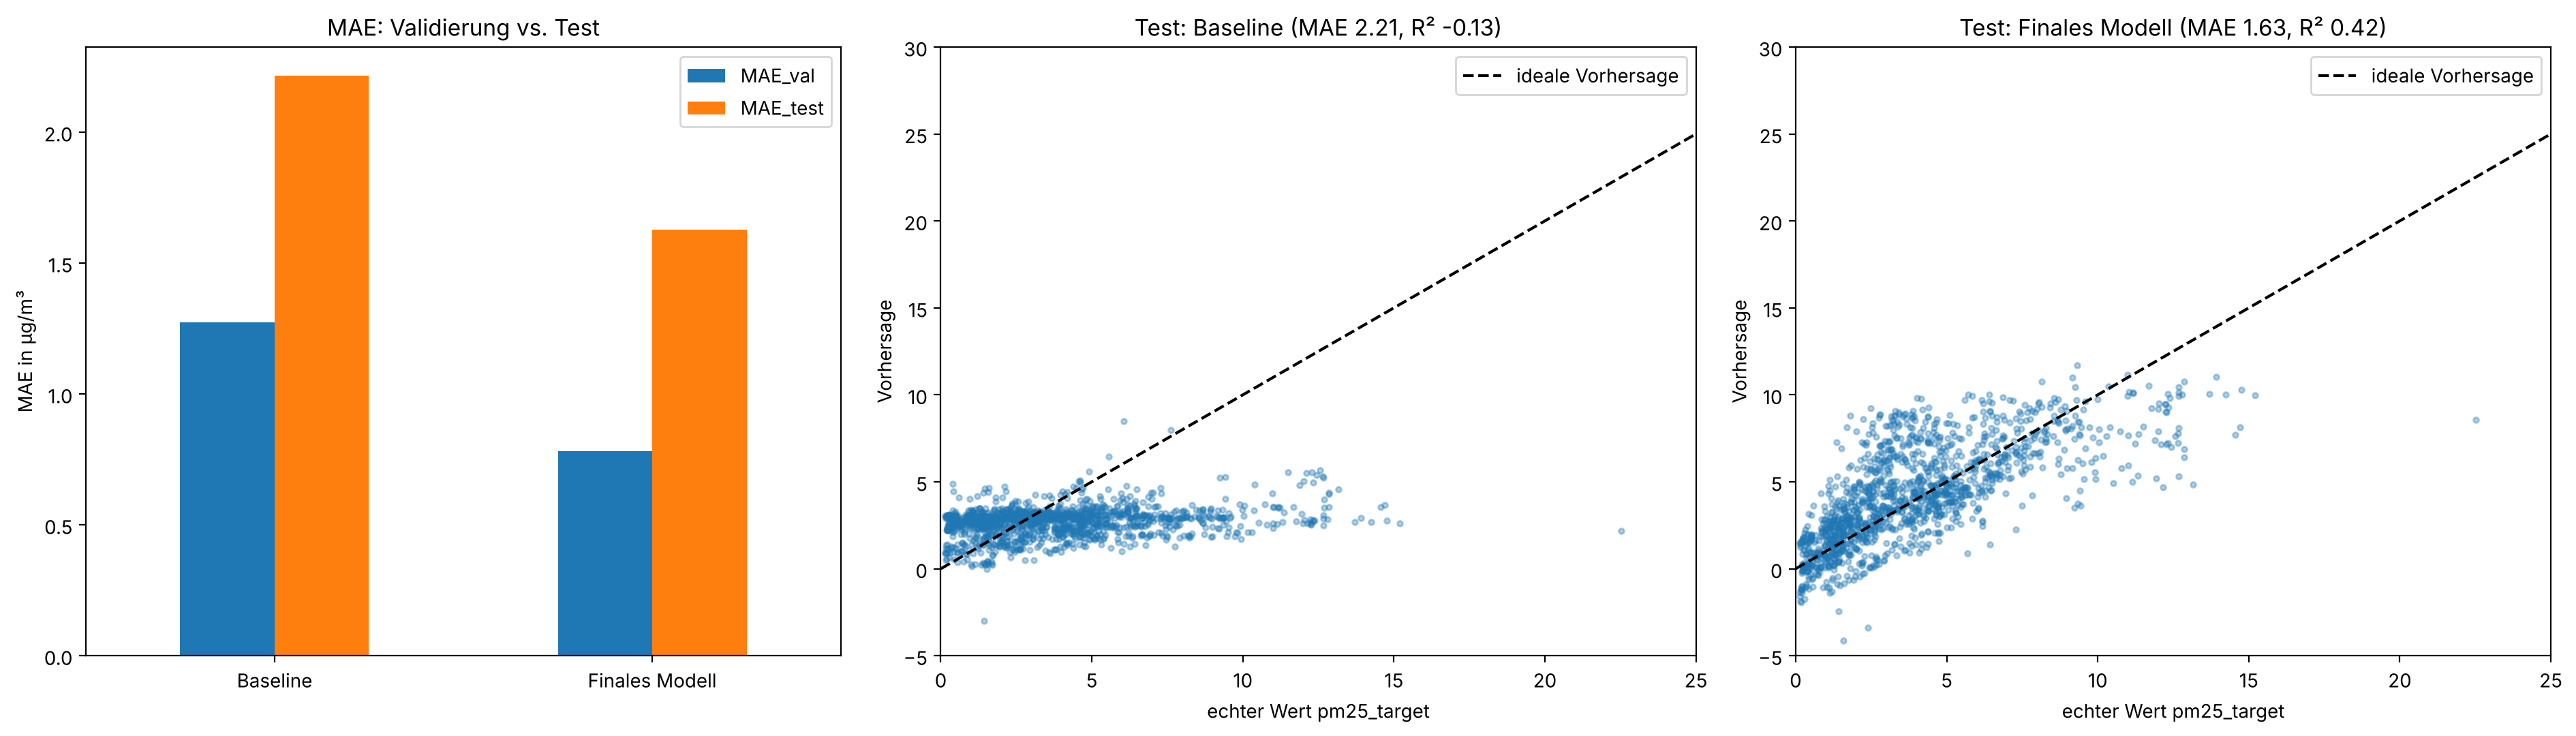

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

test_overview[["MAE_val", "MAE_test"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("MAE: Validierung vs. Test")
axes[0].set_xticks([0, 1], ["Baseline", "Finales Modell"])
axes[0].set_ylabel("MAE in µg/m³")

has_label = raw_test[TARGET].notna().to_numpy()
y_test = raw_test.loc[has_label, TARGET]
limits = (0, max(y_test.max(), 25))
for ax, (title, result) in zip(axes[1:], [("Test: Baseline", test_baseline), ("Test: Finales Modell", test_final)]):
    ax.scatter(y_test, result["pred"][has_label], s=8, alpha=0.35)
    ax.plot(limits, limits, "--", color="black", label="ideale Vorhersage")
    ax.set_xlim(limits)
    ax.set_ylim(-5, 30)
    ax.set_title(title + f" (MAE {result['MAE']:.2f}, R² {result['R2']:.2f})")
    ax.set_xlabel("echter Wert pm25_target")
    ax.set_ylabel("Vorhersage")
    ax.legend()

plt.tight_layout()
plt.show()

**Interpretation Testergebnis:**
- Das finale Modell verbessert den Test-MAE gegenüber der Baseline von **2,21 auf 1,63 µg/m³ (−26,5 %)**. Das R² steigt von **−0,13** (schlechter als der Mittelwert) auf **0,42**. Die Data Preparation wirkt also auch auf völlig unbekannten Daten deutlich.
- Im Streudiagramm sieht man den Unterschied klar: Die Baseline sagt fast immer 2–4 µg/m³ voraus, unabhängig vom echten Wert. Die Punkte liegen als flaches Band. Das finale Modell folgt der Diagonale.
- **Aber:** Der Test-MAE (1,63) ist deutlich schlechter als der Validierungs-MAE (0,78). Bei niedrigen echten Werten (0–5 µg/m³) **überschätzt** das finale Modell häufig. Das untersuchen wir im nächsten Abschnitt.
- Im Vergleich zu Task 1b: Dort war das Feature-Modell auf dem Test schlechter als die Baseline (2,21 vs. 2,16). Mit der Data Preparation ist es jetzt klar besser.

## 10. Analyse: Warum ist der Test schlechter als die Validierung?

Diese Frage war schon in Task 1 offen. Wir untersuchen zwei mögliche Ursachen:

1. **Datenqualität der Testfeatures:** Fehlen im Test andere oder mehr Werte als im Training?
2. **Saison:** Die Testdaten (Nov/Dez) stammen aus einer anderen Jahreszeit als die Trainingsdaten (Jun–Okt).

**Wichtig:** Diese Analyse findet **nach** der Modellauswahl statt und ändert die Auswahl nicht mehr. Sie dient dazu, das Ergebnis zu verstehen und Empfehlungen für Task 3 abzuleiten.

In [38]:
missing_compare = pd.DataFrame({
    "fehlend Training (%)": (raw_train.isna().mean() * 100).round(1),
    "fehlend Test (%)": (raw_test.isna().mean() * 100).round(1),
    "längster Block Test (Stunden)": [longest_gap(raw_test[col]) for col in raw_test.columns],
})
display(missing_compare[(missing_compare["fehlend Training (%)"] > 0) | (missing_compare["fehlend Test (%)"] > 0)])

print("Fehlende Wetterdaten im Test liegen im Zeitraum",
      raw_test.loc[raw_test["temperature"].isna(), "timestamp"].min(), "bis",
      raw_test.loc[raw_test["temperature"].isna(), "timestamp"].max())

,fehlend Training (%),fehlend Test (%),längster Block Test (Stunden)
pm25_target,5.6,3.1,45
pm25_lowcost,12.8,0.2,3
no,0.6,0.1,2
no2,0.6,0.1,2
o3,20.7,10.7,156
co2,25.7,58.6,744
black_carbon,0.1,48.7,713
ufp,21.5,42.0,576
temperature,11.8,67.3,984
relative_humidity,11.8,67.3,984


Fehlende Wetterdaten im Test liegen im Zeitraum 2024-11-07 13:00:00 bis 2024-12-31 23:00:00


,pm25_target,pm25_lowcost,temperature,relative_humidity,black_carbon
year_month,,,,,
2024-06,2.80,2.71,17.66,70.75,0.43
2024-07,2.34,1.95,19.81,72.80,0.50
2024-08,3.24,2.61,21.66,73.39,0.65
2024-09,2.79,3.31,16.58,78.13,0.73
2024-10,2.66,3.75,13.11,83.69,0.95
2024-11,3.52,5.98,8.20,85.20,0.88
2024-12,3.04,5.57,4.81,81.56,0.56


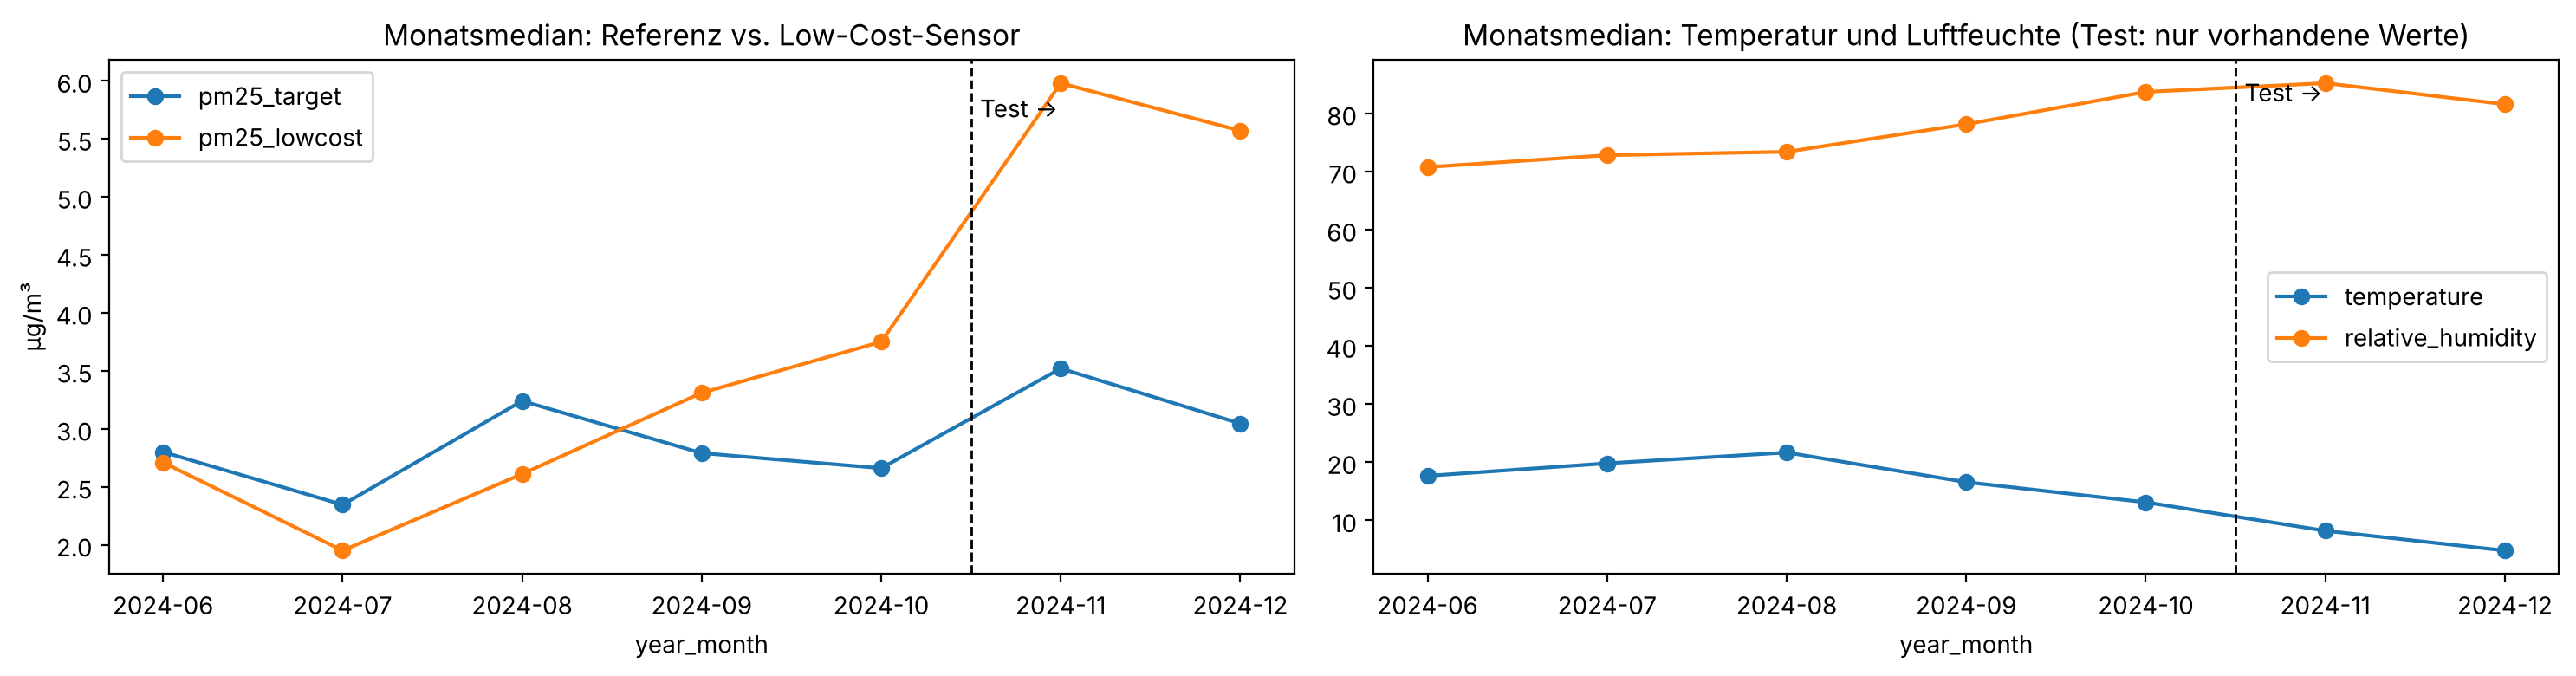

In [39]:
monthly = pd.concat([raw_train, raw_test]).groupby("year_month")[
    ["pm25_target", "pm25_lowcost", "temperature", "relative_humidity", "black_carbon"]].median()
display(monthly.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
monthly[["pm25_target", "pm25_lowcost"]].plot(marker="o", ax=axes[0])
axes[0].set_title("Monatsmedian: Referenz vs. Low-Cost-Sensor")
axes[0].set_ylabel("µg/m³")
monthly[["temperature", "relative_humidity"]].plot(marker="o", ax=axes[1])
axes[1].set_title("Monatsmedian: Temperatur und Luftfeuchte (Test: nur vorhandene Werte)")
for ax in axes:
    ax.axvline(4.5, color="black", linestyle="--", linewidth=1)
    ax.text(4.55, ax.get_ylim()[1] * 0.92, "Test →")
plt.tight_layout()
plt.show()

#### Stress-Validierung: Wie viel der Lücke erklären die fehlenden Testwerte?

Um den Effekt der fehlenden Werte vom Effekt der Saison zu trennen, simulieren wir die Datenlage des Tests auf der Validierung. Wir setzen in einer **Kopie** der Validierung Features mit derselben Quote auf NaN, wie sie im Test fehlen. Die Wetterdaten fallen dabei wie im Test gemeinsam aus. Dafür nutzen wir nur die **Vollständigkeit der Testfeatures**, keine Test-Labels.

- Wird das Modell auf der Stress-Validierung so schlecht wie auf dem Test, liegt es an den fehlenden Werten.
- Bleibt es deutlich besser als auf dem Test, ist der Rest der Lücke durch die **Saison** zu erklären.

,MAE Validierung,MAE Stress-Validierung,MAE Test
Baseline,1.274,1.434,2.214
Finales Modell,0.781,1.161,1.627


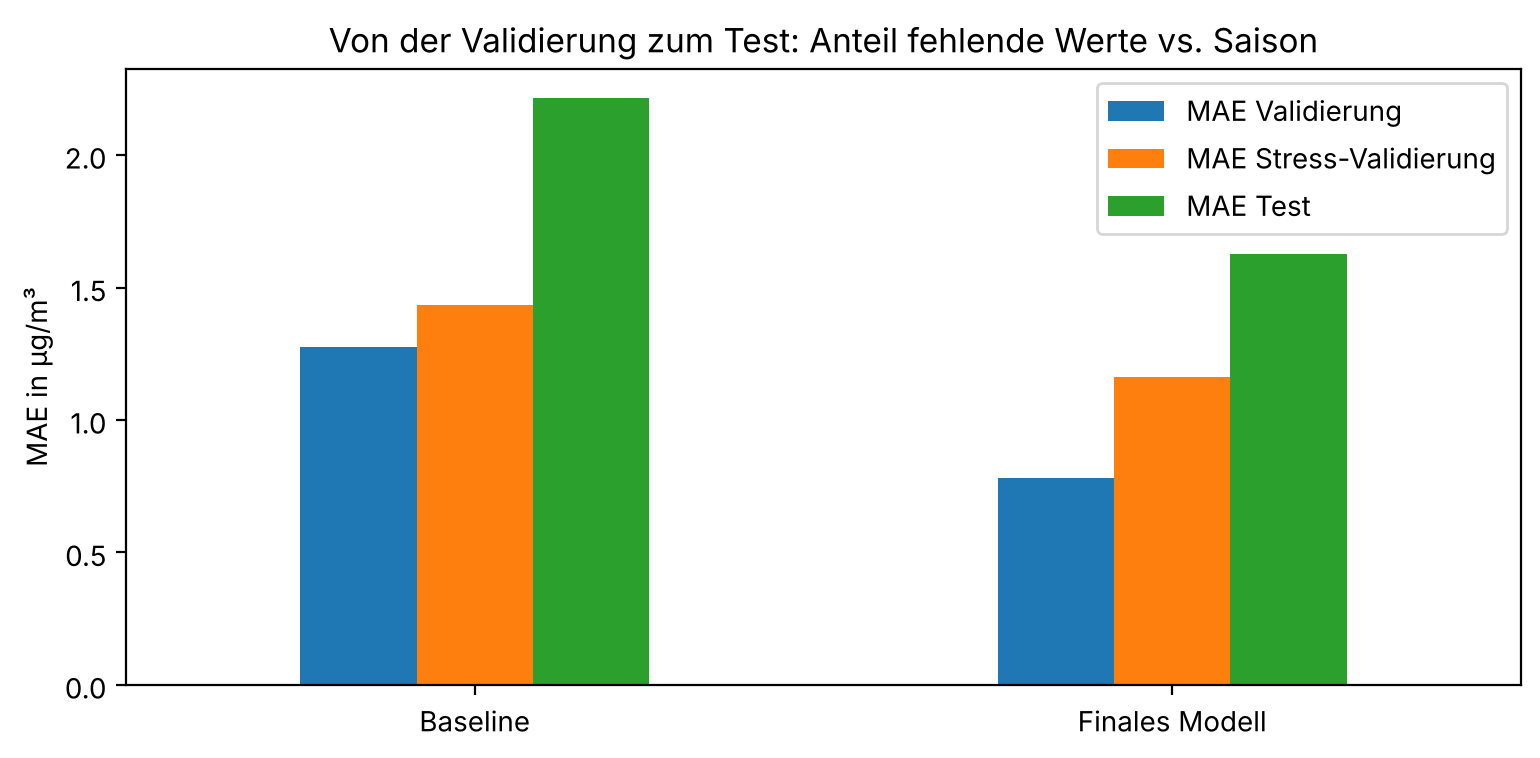

In [40]:
METEO = ["temperature", "relative_humidity", "pressure", "wind_speed", "wind_direction", "rain_vol", "glob_rad"]
test_missing_rate = raw_test.isna().mean()
rng = np.random.default_rng(42)


def make_stress_copy(df):
    stress = df.copy()
    n = len(stress)
    meteo_mask = rng.random(n) < test_missing_rate["temperature"]     # Wetterdaten fallen gemeinsam aus
    stress.loc[meteo_mask, METEO] = np.nan
    for col in ["black_carbon", "co2", "ufp", "o3"]:
        stress.loc[rng.random(n) < test_missing_rate[col], col] = np.nan
    return stress


stress_val_raw = make_stress_copy(raw_train.loc[val_idx])


# Trainingsdatei, in der nur die Validierungszeilen durch die Stress-Kopie ersetzt sind
stressed_train_file = raw_train.copy()
stressed_train_file.loc[val_idx] = stress_val_raw


def evaluate_stress(config):
    # gleiche Pipeline, gleiches Training – nur die Validierungszeilen haben die Datenlücken des Tests
    data = run_pipeline(config, train_file=stressed_train_file)
    feats = data["features"]
    _, metrics = evaluate_model(data["train"][feats], data["train"][TARGET], data["val"][feats], data["val"][TARGET])
    return metrics["MAE_val"]


gap_df = pd.DataFrame({
    "MAE Validierung": [baseline_metrics["MAE_val"], final_row["MAE_val"]],
    "MAE Stress-Validierung": [evaluate_stress({}), evaluate_stress(FINAL_CONFIG)],
    "MAE Test": [test_baseline["MAE"], test_final["MAE"]],
}, index=["Baseline", "Finales Modell"])
display(gap_df.round(3))

gap_df.plot.bar(rot=0, figsize=(9, 4))
plt.title("Von der Validierung zum Test: Anteil fehlende Werte vs. Saison")
plt.ylabel("MAE in µg/m³")
plt.show()

**Hinweis:** In der Stress-Validierung fehlt `rain_vol` vor M1. Dadurch wird `rain_hourly` dort ebenfalls NaN und per Median gefüllt. Das entspricht der Situation im Test.

#### Nachträgliche Kontrolle: Wie schneiden die besten Validierungsmodelle auf dem Test ab?

Diese Tabelle ist ausdrücklich **keine Grundlage für die Modellauswahl** (das wäre Test-Leakage), sondern dient nur dem Verständnis und der Übergabe an Task 3.

In [41]:
top_names = log_df.sort_values("MAE_val")["Modell"].head(6).tolist()
posthoc = []
for name in top_names:
    result = evaluate_on_test({**BASE_CONFIG, **all_configs[name]})
    posthoc.append({"Modell": name, "MAE_val": log_df.set_index("Modell").loc[name, "MAE_val"],
                    "MAE_test": result["MAE"], "R2_test": result["R2"]})
posthoc.append({"Modell": "Baseline", "MAE_val": baseline_metrics["MAE_val"], "MAE_test": test_baseline["MAE"],
                "R2_test": test_baseline["R2"]})
display(pd.DataFrame(posthoc).round(4))

,Modell,MAE_val,MAE_test,R2_test
0,Matrix M1 + M2 drop_rows + M3 winsor95 + alle ...,0.7807,1.6271,0.4238
1,Matrix M1 + M2 median + M3 winsor95 + alle M5-...,0.7822,1.5919,0.4519
2,Kombi M1-M3 + alle M5-Features,0.7862,1.5798,0.4573
3,Matrix M1 + M2 median + M3 iqr + alle M5-Features,0.7906,1.5407,0.4786
4,Kombi M1-M3 + Feuchte-Interaktion,0.7932,1.5797,0.4521
5,Kombi M1-M3 + M5 + Korrelationsfilter,0.8022,1.5789,0.4566
6,Baseline,1.2738,2.2145,-0.1320


**Interpretation: Warum der Test schlechter ist**

**1. Fehlende Werte im Test (Datenqualität):**
Im Test fehlen alle Wetterdaten zu **67 %**, überwiegend vom 07.11. bis Ende Dezember. `black_carbon` fehlt zu **49 %** (im Training nur 2 Werte!), `co2` zu 59 % und `ufp` zu 42 %. Diese Lücken werden mit dem **Sommer-Median** des Trainings gefüllt. Für Temperatur heißt das z. B. ca. 17 °C statt der tatsächlichen ca. 5–8 °C. Das erklärt auch Task 1b: Das dortige Modell stützte sich stark auf `black_carbon`, das im Test zur Hälfte fehlt.

**2. Saison (Verteilungsverschiebung):**
Die Monatsmediane zeigen einen klaren Trend: Je kälter und feuchter es wird, desto stärker misst der Low-Cost-Sensor über der Referenz. Im Juni messen beide fast gleich (2,7 vs. 2,8), im November liegt der Low-Cost-Sensor bei 6,0 gegenüber 3,5 µg/m³. Diese Kombination aus Kälte und Feuchte kommt in den Trainingsdaten kaum vor. Das Modell muss also **extrapolieren**, was eine lineare Regression nur begrenzt kann.

**3. Stress-Validierung trennt beide Effekte:**
Simuliert man auf der Validierung die Lücken des Tests, steigt der MAE des finalen Modells von 0,78 auf **1,16**. Der Test liegt bei 1,63. Grob erklärt damit die fehlende Datenqualität etwa **die Hälfte** der Lücke, der Rest ist der **Saisoneffekt**. Selbst unter Stress-Bedingungen bleibt das finale Modell deutlich besser als die Baseline.

**4. Nachträgliche Kontrolle:**
Die nächstbesten Validierungsmodelle liegen auf dem Test zwischen 1,54 und 1,59, also leicht besser als unser finales Modell (1,63). Die Unterschiede auf der Validierung waren kleiner als 0,01. Die Reihenfolge der Top-Modelle ist also nicht stabil, die Größenordnung der Verbesserung aber schon. Wir ändern unsere Auswahl **bewusst nicht**: Eine Auswahl anhand des Tests wäre Leakage. Für Task 3 nehmen wir aber mit, dass die Modelle **mit Median-Imputation statt Zeilenlöschung** auf dem Test etwas robuster sind.

**Learning:** Eine zufällige Validierung aus demselben Zeitraum misst nur, wie gut das Modell **innerhalb der Saison** ist. Sie unterschätzt den Fehler, wenn sich die Bedingungen ändern. Die Validierung war nicht „falsch", sie beantwortet nur eine andere Frage als der Test.

## 11. Export der vorbereiteten Datensätze

Für Task 3 exportieren wir die mit der finalen Pipeline vorbereiteten Datensätze. Sie enthalten den `timestamp` (zur Orientierung), alle finalen Features und das Label. Im Validierungs- und Testdatensatz sind **alle Zeilen** enthalten, auch die ohne Label, und die Labels sind unverändert.

In [42]:
final_data = test_final["data"]
export_cols = ["timestamp"] + final_data["features"] + [TARGET]

exports = {"Task2_preprocessed_train.csv": final_data["train"],
           "Task2_preprocessed_validation.csv": final_data["val"],
           "Task2_preprocessed_test.csv": final_data["test"]}

for file_name, df in exports.items():
    df[export_cols].to_csv(OUTPUT_DIR + file_name, index=False)
    print(f"{file_name:38s} Zeilen: {len(df):5d} | Spalten: {len(export_cols)} | Zeilen ohne Label: {df[TARGET].isna().sum()}")

# Kontrollen gemäß Aufgabenstellung
assert len(final_data["val"]) == len(val_idx)
assert len(final_data["test"]) == len(raw_test)
assert final_data["test"][TARGET].equals(raw_test[TARGET])

print("\nFeatures im Export:", final_data["features"])
print("Gelernte Parameter:", final_data["info"])

Task2_preprocessed_train.csv           Zeilen:  2454 | Spalten: 20 | Zeilen ohne Label: 0
Task2_preprocessed_validation.csv      Zeilen:   723 | Spalten: 20 | Zeilen ohne Label: 38
Task2_preprocessed_test.csv            Zeilen:  1464 | Spalten: 20 | Zeilen ohne Label: 45

Features im Export: ['pm25_lowcost', 'no', 'no2', 'o3', 'co2', 'black_carbon', 'ufp', 'temperature', 'relative_humidity', 'pressure', 'wind_speed', 'glob_rad', 'rain_hourly', 'hour_sin', 'hour_cos', 'wind_dir_sin', 'wind_dir_cos', 'lowcost_x_humidity']
Gelernte Parameter: {'M2': {'Methode': 'drop_rows', 'gelöschte Trainingszeilen': 270, 'noch fehlende Werte vor dem Füllen (Training)': 3720}, 'M3': {'Methode': 'winsor95', 'pm25_lowcost Obergrenze': np.float64(11.394), 'black_carbon Obergrenze': np.float64(2.272), 'no Obergrenze': np.float64(24.435)}, 'M5': {'neue Features': ['hour', 'wind', 'humidity']}, 'M6': {'Methode': None}, 'M4': {'Methode': None}}


## 12. Learnings, Übergabe an Task 3 und Coding-Reflexion

### 12.1 Zusammenfassung der Ergebnisse

| | Validierung MAE | Validierung R² | Test MAE | Test R² |
|---|---|---|---|---|
| Baseline (alle Features, Median) | 1,27 | 0,32 | 2,21 | −0,13 |
| Finales Modell (M1 + M2 + M3 Winsor 95 + alle M5-Features) | 0,78 | 0,74 | 1,63 | 0,42 |
| **Verbesserung** | **−38,7 %** | **+0,42** | **−26,5 %** | **+0,56** |

### 12.2 Fachliche Learnings

1. **Der Pearson/Spearman-Vergleich war der Schlüssel.** Pearson 0,08 vs. Spearman 0,72 bei `pm25_lowcost` zeigt, dass der Low-Cost-Sensor eigentlich sehr gut mit der Referenz zusammenhängt. Der Zusammenhang wird nur von wenigen Extremwerten verdeckt. Über die Lücke zwischen beiden Korrelationen haben wir außerdem automatisch die richtigen Features für das Outlier Handling gefunden (`pm25_lowcost`, `black_carbon`, `no`).
2. **Die Ausreißer haben eine physikalische Ursache.** Sie entstehen nachts bei über 90 % Luftfeuchte. Daraus haben wir nicht nur die Behandlung abgeleitet (Kappung statt Löschen), sondern auch ein neues Feature (Feuchte-Interaktion). Das war nach dem Outlier Handling der zweitgrößte Hebel.
3. **Die beste Kappungsgrenze liegt zwischen „zu streng" und „zu großzügig".** Das 99. Perzentil ist zu großzügig, die Pearson-optimierte Grenze (85. Perzentil) zu streng. Das 95. Perzentil und die Boxplot-Grenze (IQR) funktionieren am besten.
4. **Kombinationen verhalten sich anders als Einzelmaßnahmen.** Die Zeilenlöschung war einzeln die beste Missing-Value-Variante, in Kombination mit dem Outlier Handling aber nicht mehr. Der VIF-Check entfernte ein hilfreiches Feature, weil „ähnlich" nicht „überflüssig" heißt.
5. **Scaling bringt bei linearer Regression nichts.** Das konnten wir erklären (lineare Transformation wird über die Koeffizienten ausgeglichen) und belegen (exakt gleicher MAE).
6. **Validierung ≠ Test.** Die Testdaten stammen aus dem Winter und haben große Datenlücken. Etwa die Hälfte der Lücke zwischen Validierung und Test erklären die fehlenden Werte, der Rest die andere Jahreszeit.

### 12.3 Übergabe an Task 3

- **Dateien:** `Output/Task2_preprocessed_train.csv`, `..._validation.csv`, `..._test.csv` (18 Features + `timestamp` + Label; Validierung und Test vollständig mit unveränderten Labels).
- **Keine erneute Skalierung nötig für lineare Modelle.** Für distanz- oder regularisierungsbasierte Verfahren (z. B. KNN, Ridge/Lasso) sollte Task 3 auf diesen Daten standardisieren.
- **Achtung bei den Testdaten:** Wetterdaten fehlen dort zu 67 %, `black_carbon` zu 49 %. Diese Werte sind im Export mit dem Trainings-Median gefüllt. Modelle, die sich stark auf diese Features stützen, werden auf dem Test schwächer sein als auf der Validierung.
- **Empfehlung:** Nichtlineare Verfahren (z. B. Regression Trees, Polynomial Regression) testen, weil der Feuchteeffekt nicht linear ist (das Verhältnis Low-Cost/Referenz steigt bei hoher Feuchte überproportional). Zusätzlich mit einer **zeitlichen Validierung** (z. B. Oktober als Validierung) prüfen, wie gut ein Modell auf kältere Monate übertragbar ist.
- **Alle Experimente** sind mit Beschreibung in `Output/evaluation_log.csv` dokumentiert, das Testergebnis in `Output/test_evaluation.csv`.

### 12.4 Coding-Reflexion

**Was hat sich bewährt?**
- **Einheitliche Modul-Schnittstelle** (`train_part`, `other_parts`, `method`): Jede Kombination ist nur noch ein Dictionary. Dadurch konnten wir 36 Experimente mit derselben Pipeline ausführen. Im Vorjahr mussten wir für jede Stufe eigene Zellen schreiben.
- **Sicherheitsprüfungen mit `assert`**: Die Pipeline prüft bei jedem Lauf, dass Validierung und Test vollständig sind, die Labels unverändert sind und keine NaN übrig bleiben. Zusätzlich haben wir geprüft, dass die Pipeline ohne Module exakt die Baseline reproduziert.
- **Automatisches Log-File**: Jedes Experiment wird sofort mit sprechendem Namen und Beschreibung gespeichert. Die Auswahl der besten Varianten erfolgt aus dem Log und nicht von Hand.

**Konkrete Fehler und was wir daraus gelernt haben:**
- Beim ersten Test der Log-Transformation entstanden NaN-Werte, weil `np.log1p` für die negativen `no`-Werte nicht definiert ist. Daraus haben wir gelernt, dass die **Reihenfolge der Module** wichtig ist (M1 vor M3). Diese haben wir anschließend für alle Module bewusst festgelegt und begründet.
- Unsere erste Version des VIF-Checks brach ab, sobald `pm25_lowcost` den höchsten VIF hatte, statt das nächste Feature zu prüfen. Aufgefallen ist uns das bei einem Code-Review der Schleifenbedingung. Seitdem prüfen wir die `info`-Ausgaben der Module gezielt auf Plausibilität.
- Der Regenzähler und die zeitliche Interpolation brauchen eine lückenlose Zeitreihe. Im zufällig gezogenen Validierungsanteil gibt es diese nicht. Deshalb laufen diese Schritte auf der ganzen Originaldatei. Sie nutzen dabei nur Feature-Werte und keine Labels.

**Was würden wir beim nächsten Mal anders machen?**
- Die Testdaten von Anfang an auf **Vollständigkeit der Features** prüfen (ohne Labels). Die großen Lücken im Test hätten wir früher erkennen und in die Validierung einplanen können (Stress-Validierung).
- Zusätzlich zur zufälligen Validierung eine **zeitliche Validierung** verwenden, weil die Daten eine Zeitreihe sind und der Test in einer anderen Saison liegt.